# HMT-Transformer v3: Ground Motion Prediction Model
## Complete Report Notebook — All Figures & Tables
**Dataset :** ESM (Engineering Strong-Motion) Database — 8,543 records  
**Inputs  :** Mw, Rjb, log(Rjb+1), log(Vs30), Fault Type  (5-input model)  
**Outputs :** log₁₀(PSA) at 36 spectral periods, T = 0.01 s – 10.0 s  

### Notebook Cell Structure
| Cell | Content |
|------|---------|
| C01  | Install & imports |
| C02  | Configuration & paths |
| C03  | Data loading & feature engineering |
| C04  | Train / Val / Test split & scaling |
| C05  | Model architecture (all components) |
| C06  | Loss, LR schedule, EMA |
| C07  | **Training — 5-input model** |
| C08  | **Evaluation — 5-input model** |
| C09  | **Training — 6-input model** (optional comparison) |
| C10  | **Evaluation — 6-input model** |
| F01  | Fig 1 — Data distribution (M-R scatter + PGA vs R) |
| F02  | Fig 2 — Statistics histograms |
| F03  | Fig 3 — Network architecture diagram |
| F04  | Fig 4 — Hyperparameter tuning sensitivity |
| F05  | Fig 5 — Regression plots (train/val/test colored) |
| F06  | Fig 6 — Residual analysis |
| F07  | Fig 7 — Standard deviation (inter/intra-event/total) |
| F08  | Fig 8 — Parametric / sensitivity spectra |
| F09  | Fig 9 — Attenuation plots with data |
| F10  | Fig 10 — Feature importance & SHAP |
| T01  | Table 1 — Statistics of data |
| T02  | Table 2 — R² & σ per period |
| T03  | Table 3 — Performance parameters |
| CMP  | 5-input vs 6-input comparison |


## C01 — Install Dependencies & Imports

In [1]:
# Run this cell first — installs any missing packages
import subprocess, sys

for pkg in ["shap"]:
    subprocess.run([sys.executable, "-m", "pip", "install", pkg, "-q"],
                   capture_output=True)

import os, copy, math, time, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from torch.utils.data import DataLoader, TensorDataset

try:
    import shap
    SHAP_OK = True
except ImportError:
    SHAP_OK = False
    print("WARNING: shap not available — feature importance will use gradient method")

warnings.filterwarnings("ignore")
np.random.seed(42)
torch.manual_seed(42)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device : {DEVICE}")
print(f"PyTorch: {torch.__version__}")
print(f"NumPy  : {np.__version__}")
print(f"SHAP   : {'OK' if SHAP_OK else 'not installed'}")


c:\Users\prani\anaconda3\envs\dl_env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device : cuda
PyTorch: 2.5.1+cu121
NumPy  : 2.2.6
SHAP   : OK


## C02 — Configuration & Paths

In [2]:
# ── Mount Colab drive if available ──────────────────────────────────────
try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    DATA_PATH = "/content/drive/MyDrive/Seismic/ESM_filtered.csv"
    OUT_DIR   = "/content/drive/MyDrive/Seismic/Report_Figures"
    CKPT_5    = "/content/drive/MyDrive/Seismic/hmt_v3_5inp.pt"
    CKPT_6    = "/content/drive/MyDrive/Seismic/hmt_v3_6inp.pt"
    print("Colab drive mounted")
except Exception:
    DATA_PATH = "../ESM_filtered.csv"          # adjust to your local path
    OUT_DIR   = "./Report_Figures"
    CKPT_5    = "./hmt_v3_5inp.pt"
    CKPT_6    = "./hmt_v3_6inp.pt"
    print("Running locally")

os.makedirs(OUT_DIR, exist_ok=True)

# ── Training hyperparameters ─────────────────────────────────────────────
class CFG:
    # Model
    d_model   = 160
    n_heads   = 8
    n_layers  = 5
    dropout   = 0.10
    # Training
    epochs    = 150
    warmup    = 15
    lr_max    = 2e-4
    lr_min    = 1e-6
    batch     = 256
    wd        = 3e-4
    ema_decay = 0.998
    patience  = 35
    # Loss
    lam_bias  = 0.50
    lam_sm    = 0.05
    # Misc
    seed      = 42

print("Configuration ready")
print(f"Output figures → {OUT_DIR}")


Running locally
Configuration ready
Output figures → ./Report_Figures


## C03 — Data Loading & Feature Engineering

In [3]:
## C03 — Data Loading & Feature Engineering  ← UPDATED
# ONE change only vs original:
#   logVs30 is now physically normalized instead of left raw for StandardScaler
#   Formula: (log(Vs30) - log(760)) / log(2)
#   - Centers on Vs30=760 m/s (standard rock reference site) → maps to 0.0
#   - Scale unit = one octave of Vs30 (doubling) → log2-based spacing
#   - Result: Vs30=120 → -2.83,  Vs30=760 → 0.0,  Vs30=1800 → +1.25
#   - vs StandardScaler which compressed everything into ~(-2.2, +1.7)
#   - This is NOT a new feature — same logVs30 column, just better scaled
#   - StandardScaler will now see this pre-normalized column and compress
#     it very little (std already ~1), preserving the physical spread

# ── Load CSV ──────────────────────────────────────────────────────────────
df = pd.read_csv(DATA_PATH)
print(f"Loaded {len(df):,} records | {df.shape[1]} columns")

# ── PSA columns & periods ─────────────────────────────────────────────────
PSA_COLS = [
    "U_Hor_0.01","U_Hor_0.025","U_Hor_0.04","U_Hor_0.05","U_Hor_0.07",
    "U_Hor_0.1","U_Hor_0.15","U_Hor_0.2","U_Hor_0.25","U_Hor_0.3",
    "U_Hor_0.35","U_Hor_0.4","U_Hor_0.45","U_Hor_0.5","U_Hor_0.6",
    "U_Hor_0.7","U_Hor_0.75","U_Hor_0.8","U_Hor_0.9","U_Hor_1",
    "U_Hor_1.2","U_Hor_1.4","U_Hor_1.6","U_Hor_1.8","U_Hor_2",
    "U_Hor_2.5","U_Hor_3","U_Hor_3.5","U_Hor_4","U_Hor_4.5",
    "U_Hor_5","U_Hor_6","U_Hor_7","U_Hor_8","U_Hor_9","U_Hor_10"
]
PERIODS = [
    0.01, 0.025, 0.04, 0.05, 0.07,
    0.1,  0.15,  0.2,  0.25, 0.3,
    0.35, 0.4,   0.45, 0.5,  0.6,
    0.7,  0.75,  0.8,  0.9,  1.0,
    1.2,  1.4,   1.6,  1.8,  2.0,
    2.5,  3.0,   3.5,  4.0,  4.5,
    5.0,  6.0,   7.0,  8.0,  9.0,  10.0
]
N_OUT   = len(PERIODS)
PGA_IDX = 0
FAULT_LABELS = {1:"Strike-Slip", 2:"Normal", 3:"Reverse", 4:"Oblique"}

# Normalized log-period positions for the spectral decoder
_lp = np.log(PERIODS)
LOG_PERIODS_NORM = torch.tensor(
    (_lp - _lp.mean()) / (_lp.std() + 1e-9), dtype=torch.float32
)

# ── Derived features ──────────────────────────────────────────────────────
df["logR"]     = np.log(df["R(km)"].astype(float) + 1.0)
df["logDepth"] = np.log(df["Depth(km)"].astype(float) + 1.0)   # for 6-inp

# ── Vs30: physics-based normalization  ← KEY CHANGE ──────────────────────
# Center on 760 m/s (rock reference), scale by log(2) (one octave)
# This preserves the full physical spread instead of StandardScaler squishing it
_VS30_REF   = math.log(760.0)   # reference: rock site
_VS30_SCALE = math.log(2.0)     # one octave = meaningful unit of site stiffness
df["logVs30"] = (np.log(df["Vs30(m/s)"].astype(float)) - _VS30_REF) / _VS30_SCALE

# Sanity check — print the mapped values
print(f"Vs30 normalization check:")
for vs in [120, 400, 760, 1160, 1800]:
    val = (math.log(vs) - _VS30_REF) / _VS30_SCALE
    print(f"  Vs30={vs:5d} m/s → logVs30_norm = {val:+.3f}")

# ── 5-input feature matrix ─────────────────────────────────────────────────
FEAT_5  = ["Mag", "R(km)", "logR", "logVs30"]
N_CONT5 = len(FEAT_5)
X5      = df[FEAT_5].values.astype(np.float32)

# ── 6-input feature matrix (adds Depth) ───────────────────────────────────
FEAT_6  = ["Mag", "R(km)", "logR", "logVs30", "logDepth"]
N_CONT6 = len(FEAT_6)
X6      = df[FEAT_6].values.astype(np.float32)

fault_codes = df["Fault"].astype(int).values - 1   # 0-indexed (0..3)
n_faults    = int(fault_codes.max()) + 1
mw_raw      = df["Mag"].astype(np.float32).values.reshape(-1, 1)

# ── Targets: log₁₀(PSA) ──────────────────────────────────────────────────
Y_raw = np.log10(df[PSA_COLS].values.astype(np.float64) + 1e-9).astype(np.float32)

print(f"\n5-input X: {X5.shape} | 6-input X: {X6.shape} | Y: {Y_raw.shape}")
print(f"Fault classes: {n_faults} | Periods: {N_OUT}")

Loaded 8,543 records | 79 columns
Vs30 normalization check:
  Vs30=  120 m/s → logVs30_norm = -2.663
  Vs30=  400 m/s → logVs30_norm = -0.926
  Vs30=  760 m/s → logVs30_norm = +0.000
  Vs30= 1160 m/s → logVs30_norm = +0.610
  Vs30= 1800 m/s → logVs30_norm = +1.244

5-input X: (8543, 4) | 6-input X: (8543, 5) | Y: (8543, 36)
Fault classes: 4 | Periods: 36


## C04 — Train / Val / Test Split & Scaling

In [4]:
# ── Group split by EventID ────────────────────────────────────────────────
groups = df["EventID"]

gss  = GroupShuffleSplit(1, test_size=0.30, random_state=CFG.seed)
tr_i, tmp_i = next(gss.split(X5, groups=groups))

gss2 = GroupShuffleSplit(1, test_size=0.50, random_state=CFG.seed)
vi, ti = next(gss2.split(X5[tmp_i], groups=groups.iloc[tmp_i]))
val_i, te_i = tmp_i[vi], tmp_i[ti]

print(f"Train {len(tr_i):,} | Val {len(val_i):,} | Test {len(te_i):,}")

# ── Scalers (fit on train only) ───────────────────────────────────────────
xs5 = StandardScaler(); xs6 = StandardScaler(); ys = StandardScaler()

X5_tr  = xs5.fit_transform(X5[tr_i]).astype(np.float32)
X5_val = xs5.transform(X5[val_i]).astype(np.float32)
X5_te  = xs5.transform(X5[te_i]).astype(np.float32)

X6_tr  = xs6.fit_transform(X6[tr_i]).astype(np.float32)
X6_val = xs6.transform(X6[val_i]).astype(np.float32)
X6_te  = xs6.transform(X6[te_i]).astype(np.float32)

Y_tr   = ys.fit_transform(Y_raw[tr_i]).astype(np.float32)
Y_val  = ys.transform(Y_raw[val_i]).astype(np.float32)
Y_te   = ys.transform(Y_raw[te_i]).astype(np.float32)

f_tr, f_val, f_te = fault_codes[tr_i], fault_codes[val_i], fault_codes[te_i]
mw_tr  = mw_raw[tr_i]
mw_max_train = float(mw_tr.max())

# ── DataLoaders ───────────────────────────────────────────────────────────
def make_loader(Xs, Y, f, mw, shuffle=False):
    ds = TensorDataset(torch.from_numpy(Xs),
                       torch.from_numpy(f.astype(np.int64)),
                       torch.from_numpy(Y),
                       torch.from_numpy(mw))
    return DataLoader(ds, batch_size=CFG.batch, shuffle=shuffle,
                      num_workers=0, pin_memory=(DEVICE.type == "cuda"))

# 5-input loaders
tr5_ld  = make_loader(X5_tr,  Y_tr,  f_tr,  mw_tr,          shuffle=True)
val5_ld = make_loader(X5_val, Y_val, f_val, mw_raw[val_i])
te5_ld  = make_loader(X5_te,  Y_te,  f_te,  mw_raw[te_i])

# 6-input loaders
tr6_ld  = make_loader(X6_tr,  Y_tr,  f_tr,  mw_tr,          shuffle=True)
val6_ld = make_loader(X6_val, Y_val, f_val, mw_raw[val_i])
te6_ld  = make_loader(X6_te,  Y_te,  f_te,  mw_raw[te_i])

print("DataLoaders ready")


Train 5,943 | Val 1,335 | Test 1,265
DataLoaders ready


## C05 — Model Architecture

In [5]:
# ─────────────────────────────────────────────────────────────────────────
# COMPONENT 1: ScalarToken — maps one scalar → one d-dimensional token
# ─────────────────────────────────────────────────────────────────────────
class ScalarToken(nn.Module):
    def __init__(self, d, dropout=0.1):
        super().__init__()
        self.net  = nn.Sequential(nn.Linear(1, d), nn.GELU(), nn.Linear(d, d))
        self.norm = nn.LayerNorm(d)
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        return self.drop(self.norm(self.net(x.unsqueeze(-1))))

# ─────────────────────────────────────────────────────────────────────────
# COMPONENT 2: SwiGLU FFN (used in LLaMA / PaLM — outperforms GELU FFN)
# ─────────────────────────────────────────────────────────────────────────
class SwiGLU(nn.Module):
    def __init__(self, d, mult=4, dropout=0.1):
        super().__init__()
        h = int(d * mult)
        self.fc1 = nn.Linear(d, h * 2); self.fc2 = nn.Linear(h, d)
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        v, g = self.fc1(x).chunk(2, dim=-1)
        return self.fc2(self.drop(F.silu(g) * v))

# ─────────────────────────────────────────────────────────────────────────
# COMPONENT 3: Pre-norm Transformer Block with SwiGLU FFN
# ─────────────────────────────────────────────────────────────────────────
class TransformerBlock(nn.Module):
    def __init__(self, d, n_heads, dropout=0.1):
        super().__init__()
        self.n1   = nn.LayerNorm(d)
        self.attn = nn.MultiheadAttention(d, n_heads, dropout=dropout, batch_first=True)
        self.n2   = nn.LayerNorm(d)
        self.ffn  = SwiGLU(d, mult=4, dropout=dropout)
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        h = self.n1(x); a, _ = self.attn(h, h, h, need_weights=False)
        x = x + self.drop(a)
        x = x + self.drop(self.ffn(self.n2(x)))
        return x

# ─────────────────────────────────────────────────────────────────────────
# COMPONENT 4: Period-Conditioned Spectral Decoder
#   Key innovation: 36 learnable period-position queries cross-attend
#   to encoder output → no hard spectral seam between frequency bands
# ─────────────────────────────────────────────────────────────────────────
class PeriodDecoder(nn.Module):
    def __init__(self, d, n_heads=4, dropout=0.1):
        super().__init__()
        self.period_proj = nn.Sequential(nn.Linear(1, d), nn.GELU(), nn.Linear(d, d))
        self.cross     = nn.MultiheadAttention(d, n_heads, dropout=dropout, batch_first=True)
        self.norm_q    = nn.LayerNorm(d); self.norm_kv = nn.LayerNorm(d)
        self.norm_out  = nn.LayerNorm(d)
        self.out       = nn.Sequential(nn.Linear(d, d*2), nn.GELU(),
                                       nn.Dropout(dropout), nn.Linear(d*2, 1))
    def forward(self, enc, lpn):
        B  = enc.size(0)
        q  = self.period_proj(lpn.to(enc.device).unsqueeze(-1))
        q  = self.norm_q(q.unsqueeze(0).expand(B, -1, -1))        # (B,36,d)
        kv = self.norm_kv(enc)
        ctx, _ = self.cross(q, kv, kv, need_weights=False)
        return self.out(self.norm_out(q + ctx)).squeeze(-1)         # (B,36)

# ─────────────────────────────────────────────────────────────────────────
# 5-INPUT MODEL
#   Tokens: [CLS | Mw | Rjb | logR | logVs30 | Fault] = 6 tokens
# ─────────────────────────────────────────────────────────────────────────
class HMTv3_5inp(nn.Module):
    def __init__(self, n_faults, d=160, n_heads=8, n_layers=5, dropout=0.1):
        super().__init__()
        self.enc_mw    = ScalarToken(d, dropout)
        self.enc_rjb   = ScalarToken(d, dropout)
        self.enc_logr  = ScalarToken(d, dropout)
        self.enc_logvs = ScalarToken(d, dropout)
        self.fault_emb = nn.Embedding(n_faults, d)
        self.fault_norm= nn.LayerNorm(d)
        self.cls       = nn.Parameter(torch.zeros(1, 1, d))
        nn.init.trunc_normal_(self.cls, std=0.02)
        self.pos       = nn.Parameter(torch.zeros(1, 6, d))   # 1 CLS + 4 cont + 1 fault
        nn.init.trunc_normal_(self.pos, std=0.02)
        self.in_drop   = nn.Dropout(dropout)
        self.blocks    = nn.ModuleList([TransformerBlock(d, n_heads, dropout)
                                        for _ in range(n_layers)])
        self.decoder   = PeriodDecoder(d, n_heads=4, dropout=dropout)
    def forward(self, x_s, f):
        B = x_s.size(0)
        toks = torch.stack([
            self.enc_mw(x_s[:,0]), self.enc_rjb(x_s[:,1]),
            self.enc_logr(x_s[:,2]), self.enc_logvs(x_s[:,3]),
            self.fault_norm(self.fault_emb(f))
        ], dim=1)
        tokens = torch.cat([self.cls.expand(B,-1,-1), toks], dim=1) + self.pos
        tokens = self.in_drop(tokens)
        for blk in self.blocks: tokens = blk(tokens)
        return self.decoder(tokens, LOG_PERIODS_NORM)

# ─────────────────────────────────────────────────────────────────────────
# 6-INPUT MODEL — adds Depth + Depth×Fault cross-attention token
#   Tokens: [CLS | Mw | Rjb | logR | logVs30 | Depth | Fault | df_ctx] = 8
# ─────────────────────────────────────────────────────────────────────────
class HMTv3_6inp(nn.Module):
    def __init__(self, n_faults, d=160, n_heads=8, n_layers=5, dropout=0.1):
        super().__init__()
        self.enc_mw    = ScalarToken(d, dropout)
        self.enc_rjb   = ScalarToken(d, dropout)
        self.enc_logr  = ScalarToken(d, dropout)
        self.enc_logvs = ScalarToken(d, dropout)
        self.enc_depth = ScalarToken(d, dropout)
        self.fault_emb = nn.Embedding(n_faults, d)
        self.fault_norm= nn.LayerNorm(d)
        self.df_attn   = nn.MultiheadAttention(d, n_heads, dropout=dropout, batch_first=True)
        self.df_norm   = nn.LayerNorm(d)
        self.cls       = nn.Parameter(torch.zeros(1, 1, d))
        nn.init.trunc_normal_(self.cls, std=0.02)
        self.pos       = nn.Parameter(torch.zeros(1, 8, d))
        nn.init.trunc_normal_(self.pos, std=0.02)
        self.in_drop   = nn.Dropout(dropout)
        self.blocks    = nn.ModuleList([TransformerBlock(d, n_heads, dropout)
                                        for _ in range(n_layers)])
        self.decoder   = PeriodDecoder(d, n_heads=4, dropout=dropout)
    def forward(self, x_s, f):
        B = x_s.size(0)
        t_mw    = self.enc_mw(x_s[:,0]);    t_rjb = self.enc_rjb(x_s[:,1])
        t_logr  = self.enc_logr(x_s[:,2]);  t_vs  = self.enc_logvs(x_s[:,3])
        t_dep   = self.enc_depth(x_s[:,4]); t_ft  = self.fault_norm(self.fault_emb(f))
        df_pair = torch.stack([t_dep, t_ft], dim=1)
        df_out, _ = self.df_attn(t_dep.unsqueeze(1), df_pair, df_pair, need_weights=False)
        df_ctx  = self.df_norm(t_dep + df_out.squeeze(1))
        toks    = torch.stack([t_mw, t_rjb, t_logr, t_vs, t_dep, t_ft, df_ctx], dim=1)
        tokens  = torch.cat([self.cls.expand(B,-1,-1), toks], dim=1) + self.pos
        tokens  = self.in_drop(tokens)
        for blk in self.blocks: tokens = blk(tokens)
        return self.decoder(tokens, LOG_PERIODS_NORM)

print("All model classes defined")
print(f"5-inp params: {sum(p.numel() for p in HMTv3_5inp(n_faults).parameters() if p.requires_grad):,}")
print(f"6-inp params: {sum(p.numel() for p in HMTv3_6inp(n_faults).parameters() if p.requires_grad):,}")


All model classes defined
5-inp params: 2,351,201
6-inp params: 2,481,281


## C06 — Loss Function, LR Schedule & EMA

In [6]:
## C06 — Loss Function, LR Schedule & EMA  ← FINAL VERSION
# Changes vs original:
#   1. make_scaled_input() uses physics-based Vs30 norm (matches C03)
#   2. monotonicity_penalty() called ONCE per epoch (not per batch — fast)
#   3. physics_loss() unchanged for batch training
#   4. train_model() adds one penalty step per epoch after warmup
#   5. Validation uses base loss only for clean early-stop signal

CFG.lam_mono_R  = 0.30
CFG.lam_mono_Vs = 0.30
CFG.lam_mono_Mw = 0.20

# ── Helper: build one scaled input row ───────────────────────────────────
# MUST match C03 normalization exactly
_VS30_REF   = math.log(760.0)
_VS30_SCALE = math.log(2.0)

def make_scaled_input(Mw, Rjb, Vs30, scaler):
    """
    Builds a scaled (1,4) input tensor matching C03+C04 preprocessing:
      col 0: Mw         — StandardScaler scaled
      col 1: R(km)      — StandardScaler scaled
      col 2: logR       — StandardScaler scaled
      col 3: logVs30    — physics-normed THEN StandardScaler scaled
    """
    logVs30_norm = (math.log(Vs30) - _VS30_REF) / _VS30_SCALE
    raw = np.array([[Mw, Rjb, math.log(Rjb + 1.0), logVs30_norm]],
                   dtype=np.float32)
    return torch.from_numpy(scaler.transform(raw).astype(np.float32)).to(DEVICE)


# ── Monotonicity penalty — called ONCE per epoch ─────────────────────────
def monotonicity_penalty(model, scaler):
    """
    ~252 forward passes, called once per epoch ≈ cost of 1 extra batch.

    Rule 1 — Distance : PSA(R_near) >= PSA(R_far)  at all periods
    Rule 2 — Vs30     : PSA(Vs_soft) >= PSA(Vs_rock) at long T (idx>=10)
                        PSA(Vs_rock) >= PSA(Vs_soft) at short T (idx<10)
    Rule 3 — Magnitude: PSA(Mw_high) >= PSA(Mw_low) at all periods
    """
    penalties = []
    f_list = [0, 1, 2]
    SHORT  = slice(0, 10)   # T = 0.01 .. 0.30 s
    LONG   = slice(10, 36)  # T = 0.35 .. 10.0 s

    # Rule 1: Distance
    for Mw in [5.0, 6.5, 7.5]:
        for Vs in [400, 760]:
            for fi in f_list:
                ft = torch.tensor([fi], dtype=torch.long, device=DEVICE)
                for R1, R2 in [(5, 25), (25, 75), (5, 100)]:
                    p1 = model(make_scaled_input(Mw, R1, Vs, scaler), ft)
                    p2 = model(make_scaled_input(Mw, R2, Vs, scaler), ft)
                    penalties.append(F.relu(p2 - p1).mean())

    # Rule 2: Vs30
    for Mw in [5.5, 7.5]:
        for Rjb in [10, 60]:
            for fi in f_list:
                ft = torch.tensor([fi], dtype=torch.long, device=DEVICE)
                for Vs_soft, Vs_rock in [(120, 760), (760, 1800), (120, 1800)]:
                    ps = model(make_scaled_input(Mw, Rjb, Vs_soft, scaler), ft)
                    pr = model(make_scaled_input(Mw, Rjb, Vs_rock, scaler), ft)
                    penalties.append(F.relu(ps[:, SHORT] - pr[:, SHORT]).mean())
                    penalties.append(F.relu(pr[:, LONG]  - ps[:, LONG]).mean())

    # Rule 3: Magnitude
    for Rjb in [10, 60]:
        for Vs in [400, 760]:
            for fi in f_list:
                ft = torch.tensor([fi], dtype=torch.long, device=DEVICE)
                for Mw_lo, Mw_hi in [(4.5, 6.5), (5.5, 7.5), (4.5, 7.5)]:
                    p_lo = model(make_scaled_input(Mw_lo, Rjb, Vs, scaler), ft)
                    p_hi = model(make_scaled_input(Mw_hi, Rjb, Vs, scaler), ft)
                    penalties.append(F.relu(p_lo - p_hi).mean())

    return torch.stack(penalties).mean()


# ── Base physics loss — per batch, unchanged from original ────────────────
def physics_loss(pred, target, mw_batch):
    w    = torch.exp(mw_batch.squeeze(1) / mw_max_train)
    w    = w / w.mean().clamp_min(1e-6)
    mse  = ((pred - target) ** 2).mean(dim=1)
    bias = (pred - target).mean()
    d2   = pred[:, 2:] - 2 * pred[:, 1:-1] + pred[:, :-2]
    return (  (w * mse).mean()
            + CFG.lam_bias * bias ** 2
            + CFG.lam_sm   * (d2 ** 2).mean() )


# ── Warmup + cosine LR schedule (unchanged) ──────────────────────────────
def get_lr(epoch):
    if epoch < CFG.warmup:
        return CFG.lr_max * (epoch + 1) / CFG.warmup
    t = (epoch - CFG.warmup) / (CFG.epochs - CFG.warmup)
    return CFG.lr_min + 0.5 * (CFG.lr_max - CFG.lr_min) * (1 + math.cos(math.pi * t))


# ── EMA (unchanged) ──────────────────────────────────────────────────────
class EMA:
    def __init__(self, model, decay=0.998):
        self.decay  = decay
        self.shadow = {k: v.clone().float() for k, v in model.state_dict().items()}

    @torch.no_grad()
    def update(self, model):
        for k, v in model.state_dict().items():
            self.shadow[k].mul_(self.decay).add_(v.float(), alpha=1 - self.decay)

    def apply(self, model):
        model.load_state_dict({k: v.to(next(model.parameters()).dtype)
                                for k, v in self.shadow.items()})

    def restore(self, model, state):
        model.load_state_dict(state)


# ── train_model — one penalty step per epoch after warmup ────────────────
def train_model(model, tr_ld, val_ld, ckpt_path, label="model", scaler=None):
    optimizer = torch.optim.AdamW(model.parameters(),
                                   lr=CFG.lr_max, weight_decay=CFG.wd)
    ema       = EMA(model, decay=CFG.ema_decay)
    best_val  = float("inf"); best_state = None; no_improve = 0
    tr_hist, vl_hist = [], []

    print(f"\nTraining {label} | {CFG.epochs} epochs | patience {CFG.patience}")
    print(f"Monotonicity penalty: once/epoch from ep {CFG.warmup}, "
          f"fully ramped ep {CFG.warmup + 20}")
    print("=" * 65)
    t0 = time.time()

    for epoch in range(CFG.epochs):
        lr = get_lr(epoch)
        for pg in optimizer.param_groups:
            pg["lr"] = lr

        # Standard batch training loop — same as original
        model.train(); tr_loss = 0.0
        for xs_b, f_b, y_b, mw_b in tr_ld:
            xs_b, f_b, y_b, mw_b = (t.to(DEVICE) for t in (xs_b, f_b, y_b, mw_b))
            optimizer.zero_grad()
            loss = physics_loss(model(xs_b, f_b), y_b, mw_b)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            ema.update(model)
            tr_loss += loss.item() * xs_b.size(0)
        tr_loss /= len(tr_ld.dataset)

        # ONE monotonicity penalty step per epoch (after warmup)
        if scaler is not None and epoch >= CFG.warmup:
            ramp = min(1.0, (epoch - CFG.warmup) / 20.0)
            model.train()
            optimizer.zero_grad()
            mono = monotonicity_penalty(model, scaler)
            mono_loss = ramp * (CFG.lam_mono_R + CFG.lam_mono_Vs + CFG.lam_mono_Mw) * mono
            mono_loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

        # Validation — EMA weights, base loss only
        orig = copy.deepcopy(model.state_dict())
        ema.apply(model); model.eval()
        vl_loss = 0.0
        with torch.no_grad():
            for xs_b, f_b, y_b, mw_b in val_ld:
                xs_b, f_b, y_b, mw_b = (t.to(DEVICE) for t in (xs_b, f_b, y_b, mw_b))
                vl_loss += physics_loss(model(xs_b, f_b), y_b, mw_b).item() * xs_b.size(0)
        vl_loss /= len(val_ld.dataset)
        ema.restore(model, orig)

        tr_hist.append(tr_loss); vl_hist.append(vl_loss)
        if vl_loss < best_val:
            best_val   = vl_loss
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1

        if (epoch + 1) % 10 == 0 or epoch == 0:
            tag = " [+mono]" if epoch >= CFG.warmup else ""
            print(f"Ep {epoch+1:3d}/{CFG.epochs} | lr={lr:.2e} | "
                  f"tr={tr_loss:.4f} | val={vl_loss:.4f} | "
                  f"best={best_val:.4f} | {time.time()-t0:.0f}s{tag}")

        if no_improve >= CFG.patience:
            print(f"Early stop @ epoch {epoch+1} (best val={best_val:.4f})")
            break

    model.load_state_dict(best_state)
    ema.apply(model)
    torch.save({"model_state": model.state_dict(),
                "tr_hist":     tr_hist,
                "vl_hist":     vl_hist,
                "best_val":    best_val}, ckpt_path)
    print(f"Checkpoint saved → {ckpt_path}")
    return tr_hist, vl_hist


# ── evaluate & compute_metrics (unchanged) ───────────────────────────────
def evaluate(model, loaders_dict):
    model.eval(); results = {}
    for split, (ld, idx) in loaders_dict.items():
        preds, trues = [], []
        with torch.no_grad():
            for xs_b, f_b, y_b, mw_b in ld:
                xs_b, f_b = xs_b.to(DEVICE), f_b.to(DEVICE)
                preds.append(model(xs_b, f_b).cpu().numpy())
                trues.append(y_b.numpy())
        pred_l10 = ys.inverse_transform(np.vstack(preds))
        true_l10 = ys.inverse_transform(np.vstack(trues))
        results[split] = (pred_l10, true_l10, idx)
    return results


def compute_metrics(pred_l10, true_l10):
    r2_per   = np.array([r2_score(true_l10[:, k], pred_l10[:, k])
                          for k in range(N_OUT)])
    rmse_per = np.sqrt(np.mean((pred_l10 - true_l10) ** 2, axis=0))
    bias_per = (pred_l10 - true_l10).mean(axis=0)
    return r2_per, rmse_per, bias_per


print("=" * 55)
print("C06 FINAL — physics Vs30 norm + fast monotonicity penalty")
print(f"  lam_mono_R  = {CFG.lam_mono_R}")
print(f"  lam_mono_Vs = {CFG.lam_mono_Vs}")
print(f"  lam_mono_Mw = {CFG.lam_mono_Mw}")
print("=" * 55)

C06 FINAL — physics Vs30 norm + fast monotonicity penalty
  lam_mono_R  = 0.3
  lam_mono_Vs = 0.3
  lam_mono_Mw = 0.2


## C07 — Train 6-Input Model (PRIMARY — includes Depth)

In [7]:
# ── Train 6-input model as primary ───────────────────────────────────────
model6 = HMTv3_6inp(n_faults=n_faults, d=CFG.d_model, n_heads=CFG.n_heads,
                     n_layers=CFG.n_layers, dropout=CFG.dropout).to(DEVICE)

if os.path.exists(CKPT_6):
    ck6 = torch.load(CKPT_6, map_location=DEVICE)
    model6.load_state_dict(ck6["model_state"])
    tr6_hist, vl6_hist = ck6["tr_hist"], ck6["vl_hist"]
    print(f"Loaded 6-inp checkpoint. Best val = {ck6['best_val']:.4f}")
else:
    tr6_hist, vl6_hist = train_model(model6, tr6_ld, val6_ld, CKPT_6, "HMT-v3 (6-inp)")


# Also train 5-input for comparison
model5 = HMTv3_5inp(n_faults=n_faults, d=CFG.d_model, n_heads=CFG.n_heads,
                     n_layers=CFG.n_layers, dropout=CFG.dropout).to(DEVICE)
if os.path.exists(CKPT_5):
    ck5 = torch.load(CKPT_5, map_location=DEVICE)
    model5.load_state_dict(ck5["model_state"])
    tr5_hist, vl5_hist = ck5["tr_hist"], ck5["vl_hist"]
    print(f"Loaded 5-inp checkpoint. Best val = {ck5['best_val']:.4f}")
else:
    tr5_hist, vl5_hist = train_model(model5, tr5_ld, val5_ld, CKPT_5,
                                      "HMT-v3 (5-inp comparison)")


Training HMT-v3 (6-inp) | 150 epochs | patience 35
Monotonicity penalty: once/epoch from ep 15, fully ramped ep 35
Ep   1/150 | lr=1.33e-05 | tr=1.0338 | val=1.0531 | best=1.0531 | 2s
Ep  10/150 | lr=1.33e-04 | tr=0.2129 | val=0.7127 | best=0.7127 | 10s
Ep  20/150 | lr=2.00e-04 | tr=0.1930 | val=0.3420 | best=0.3420 | 20s [+mono]
Ep  30/150 | lr=1.95e-04 | tr=0.1823 | val=0.2234 | best=0.2234 | 29s [+mono]
Ep  40/150 | lr=1.85e-04 | tr=0.1797 | val=0.1987 | best=0.1987 | 38s [+mono]
Ep  50/150 | lr=1.70e-04 | tr=0.1721 | val=0.1969 | best=0.1965 | 48s [+mono]
Ep  60/150 | lr=1.52e-04 | tr=0.1689 | val=0.1992 | best=0.1965 | 57s [+mono]
Ep  70/150 | lr=1.31e-04 | tr=0.1623 | val=0.2022 | best=0.1965 | 67s [+mono]
Ep  80/150 | lr=1.09e-04 | tr=0.1580 | val=0.2047 | best=0.1965 | 76s [+mono]
Early stop @ epoch 82 (best val=0.1965)
Checkpoint saved → ./hmt_v3_6inp.pt
Loaded 5-inp checkpoint. Best val = 0.2036


## C08 — Evaluate Both Models (6-input = Primary)

In [8]:
# ── Evaluate 6-input (PRIMARY) ────────────────────────────────────────────
res6 = evaluate(model6, {
    "train": (tr6_ld, tr_i),
    "val"  : (val6_ld, val_i),
    "test" : (te6_ld, te_i),
})
pred6_tr,  true6_tr,  _ = res6["train"]
pred6_val, true6_val, _ = res6["val"]
pred6_te,  true6_te,  _ = res6["test"]
r2_6, rmse_6, bias_6 = compute_metrics(pred6_te, true6_te)

# ── Evaluate 5-input (COMPARISON) ────────────────────────────────────────
res5 = evaluate(model5, {
    "train": (tr5_ld, tr_i),
    "val"  : (val5_ld, val_i),
    "test" : (te5_ld, te_i),
})
pred5_tr,  true5_tr,  _ = res5["train"]
pred5_val, true5_val, _ = res5["val"]
pred5_te,  true5_te,  _ = res5["test"]
r2_5, rmse_5, bias_5 = compute_metrics(pred5_te, true5_te)

# ── Short alias: figures use pred_te / true_te = 6-input results ─────────
pred_te  = pred6_te;  true_te  = true6_te
pred_tr  = pred6_tr;  true_tr  = true6_tr
pred_val = pred6_val; true_val = true6_val
r2_per   = r2_6;  rmse_per = rmse_6;  bias_per = bias_6

print("=" * 55)
print("  6-INPUT MODEL (PRIMARY) — TEST RESULTS")
print("=" * 55)
print(f"  Mean R²       : {r2_6.mean():.4f}")
print(f"  Mean RMSE     : {rmse_6.mean():.4f}  (log₁₀ units)")
print(f"  Spectral Bias : {bias_6.mean():.5f}  (log₁₀ units)")
print(f"  PGA proxy R²  : {r2_6[PGA_IDX]:.4f}  (T=0.01 s)")
print(f"  Best  R² @ T={PERIODS[r2_6.argmax()]}s : {r2_6.max():.4f}")
print(f"  Worst R² @ T={PERIODS[r2_6.argmin()]}s : {r2_6.min():.4f}")
print("=" * 55)
print(f"\n  5-input comparison: R²={r2_5.mean():.4f}  Bias={bias_5.mean():.5f}")
print(f"  ΔR² (6-inp − 5-inp) = {r2_6.mean()-r2_5.mean():+.4f}")

  6-INPUT MODEL (PRIMARY) — TEST RESULTS
  Mean R²       : 0.8500
  Mean RMSE     : 0.4374  (log₁₀ units)
  Spectral Bias : -0.07086  (log₁₀ units)
  PGA proxy R²  : 0.8299  (T=0.01 s)
  Best  R² @ T=6.0s : 0.8962
  Worst R² @ T=0.15s : 0.7818

  5-input comparison: R²=0.8644  Bias=-0.04897
  ΔR² (6-inp − 5-inp) = -0.0143


---
## Report Figures
*All figures are saved to `OUT_DIR` at 300 dpi.*

In [9]:
# ── Plot style & save helper ──────────────────────────────────────────────
plt.rcParams.update({
    "font.family"           : "Times New Roman",
    "font.size"             : 12,
    "axes.spines.top"       : False,
    "axes.spines.right"     : False,
    "axes.grid"             : True,
    "grid.alpha"            : 0.3,
    "figure.dpi"            : 150,      # screen preview
    "savefig.dpi"           : 300,      # saved file always 300 dpi
})

# Colour palette
C = dict(
    navy="#264653", teal="#2A9D8F", coral="#E76F51",
    amber="#E9C46A", purple="#8338EC", grey="#888888",
    green="#52B788", red="#D62828"
)

FAULT_LABEL = {0:"Strike-Slip", 1:"Normal", 2:"Reverse", 3:"Oblique"}
MW_BINS     = [(4.1,5.0,"#4477AA"),(5.0,6.0,"#66CCEE"),
               (6.0,7.0,"#228833"),(7.0,8.0,"#EE6677")]

def savefig(name):
    """Always saves at 300 dpi (set via savefig.dpi rcParam)."""
    path = os.path.join(OUT_DIR, name)
    plt.savefig(path, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"  → {path}")

# ── predict6: uses the 6-input model (PRIMARY) ───────────────────────────
def predict6(Mw, Rjb, Vs30, Depth, fault_0idx): 
    logR = np.log(Rjb + 1.0) 
    logVs30_norm = (np.log(Vs30) - np.log(760.0)) / np.log(2.0) 
    raw = np.array([[Mw, Rjb, logR, logVs30_norm, Depth]], dtype=np.float32) 
    xs_b = torch.from_numpy(xs6.transform(raw).astype(np.float32)).to(DEVICE) 
    f_b = torch.tensor([fault_0idx], dtype=torch.long, device=DEVICE) 
    model6.eval() 
    with torch.no_grad(): 
        out = model6(xs_b, f_b).cpu().numpy() 
        return ys.inverse_transform(out)[0]

# Keep predict5 for comparison
def predict5(Mw, Rjb, Vs30, fault_0idx):
    """Returns log₁₀(PSA) for 36 periods using 5-input model."""
    logR_v  = math.log(Rjb + 1.0)
    logVs_v = math.log(Vs30)
    raw  = np.array([[Mw, Rjb, logR_v, logVs_v]], dtype=np.float32)
    xs_b = torch.from_numpy(xs5.transform(raw).astype(np.float32)).to(DEVICE)
    f_b  = torch.tensor([fault_0idx], dtype=torch.long, device=DEVICE)
    model5.eval()
    with torch.no_grad():
        out = model5(xs_b, f_b).cpu().numpy()
    return ys.inverse_transform(out)[0]

print("Plot helpers ready  |  Primary model = 6-input  |  Save DPI = 300")

Plot helpers ready  |  Primary model = 6-input  |  Save DPI = 300


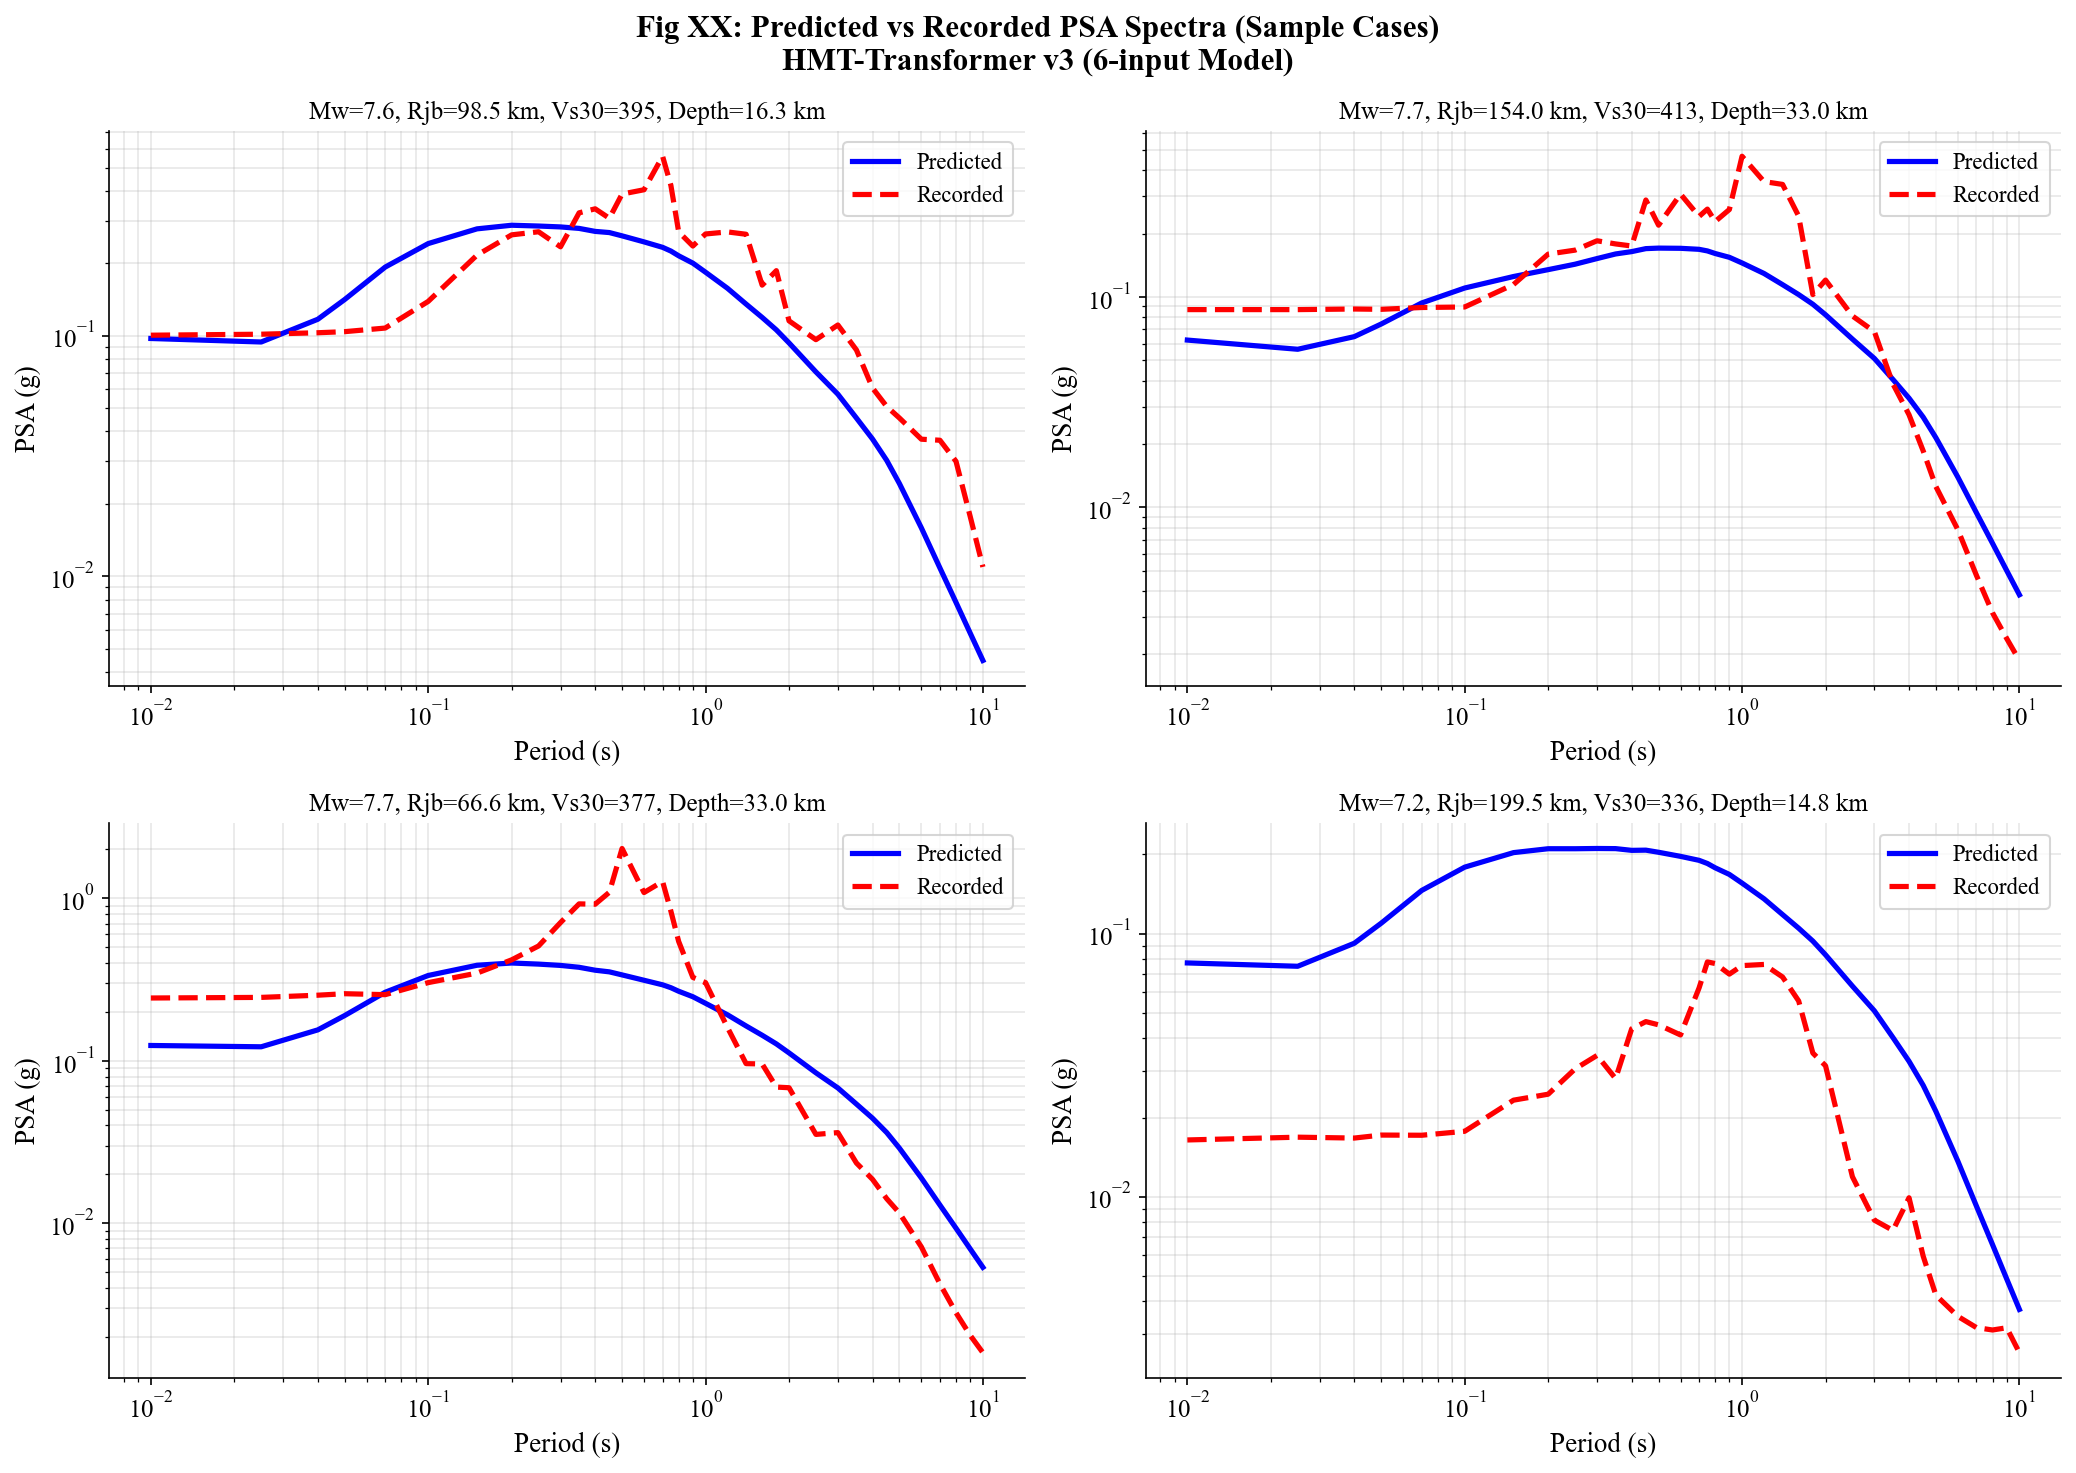

  → ./Report_Figures\Fig_Sample_Pred_vs_Actual.png

Prediction vs Actual Summary:


,Sample,Mw,Rjb,Vs30,Depth,PGA_pred,PGA_true,Peak_pred,Peak_true
0,189,7.6,98.5,394.6,16.3,0.0974,0.1005,0.2879,0.5571
1,6,7.7,154.0,413.0,33.0,0.0623,0.0870,0.1705,0.4658
2,207,7.7,66.6,377.0,33.0,0.1243,0.2437,0.4001,2.0288
3,61,7.2,199.5,335.8,14.8,0.0773,0.0164,0.2106,0.0780


In [10]:
# ── Sample-based Prediction vs Actual (TA requirement) ─────────────

# Pick 4 real samples from dataset
df_big = df[df["Mag"] >= 7.0]
sample_indices = df_big.sample(4, random_state=42).index.tolist()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Fig XX: Predicted vs Recorded PSA Spectra (Sample Cases)\n"
             "HMT-Transformer v3 (6-input Model)",
             fontsize=15, fontweight="bold")

summary_rows = []

for ax, idx in zip(axes.flat, sample_indices):

    # --- Extract REAL input from dataset ---
    Mw     = float(df.loc[idx, "Mag"])
    Rjb    = float(df.loc[idx, "R(km)"])
    Vs30   = float(df.loc[idx, "Vs30(m/s)"])
    Depth  = float(df.loc[idx, "Depth(km)"])
    fault_idx = int(df.loc[idx, "Fault"]) -1  # make sure 0-based!

    # --- Model Prediction ---
    pred_log10 = predict6(Mw, Rjb, Vs30, Depth, fault_idx)
    pred_psa   = (10**pred_log10) / 981.0

    # --- Actual (Recorded) ---
    true_log10 = Y_raw[idx, :]
    true_psa   = (10**true_log10) / 981.0

    # --- Plot ---
    ax.loglog(PERIODS, pred_psa, lw=2.5, label="Predicted", color="blue")
    ax.loglog(PERIODS, true_psa, lw=2.5, ls="--", label="Recorded", color="red")

    ax.set_xlabel("Period (s)", fontsize=13)
    ax.set_ylabel("PSA (g)", fontsize=13)

    ax.set_title(
        f"Mw={Mw:.1f}, Rjb={Rjb:.1f} km, Vs30={Vs30:.0f}, Depth={Depth:.1f} km",
        fontsize=12
    )

    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=11)

    # --- Metrics ---
    pga_pred = pred_psa[PGA_IDX]
    pga_true = true_psa[PGA_IDX]

    peak_pred = np.max(pred_psa)
    peak_true = np.max(true_psa)

    summary_rows.append({
        "Sample": idx,
        "Mw": Mw,
        "Rjb": Rjb,
        "Vs30": Vs30,
        "Depth": Depth,
        "PGA_pred": f"{pga_pred:.4f}",
        "PGA_true": f"{pga_true:.4f}",
        "Peak_pred": f"{peak_pred:.4f}",
        "Peak_true": f"{peak_true:.4f}"
    })

plt.tight_layout()
savefig("Fig_Sample_Pred_vs_Actual.png")

# Summary table
summary_df = pd.DataFrame(summary_rows)
print("\nPrediction vs Actual Summary:")
display(summary_df)

### F01 — Data Distribution (M-R Scatter + PGA vs R)

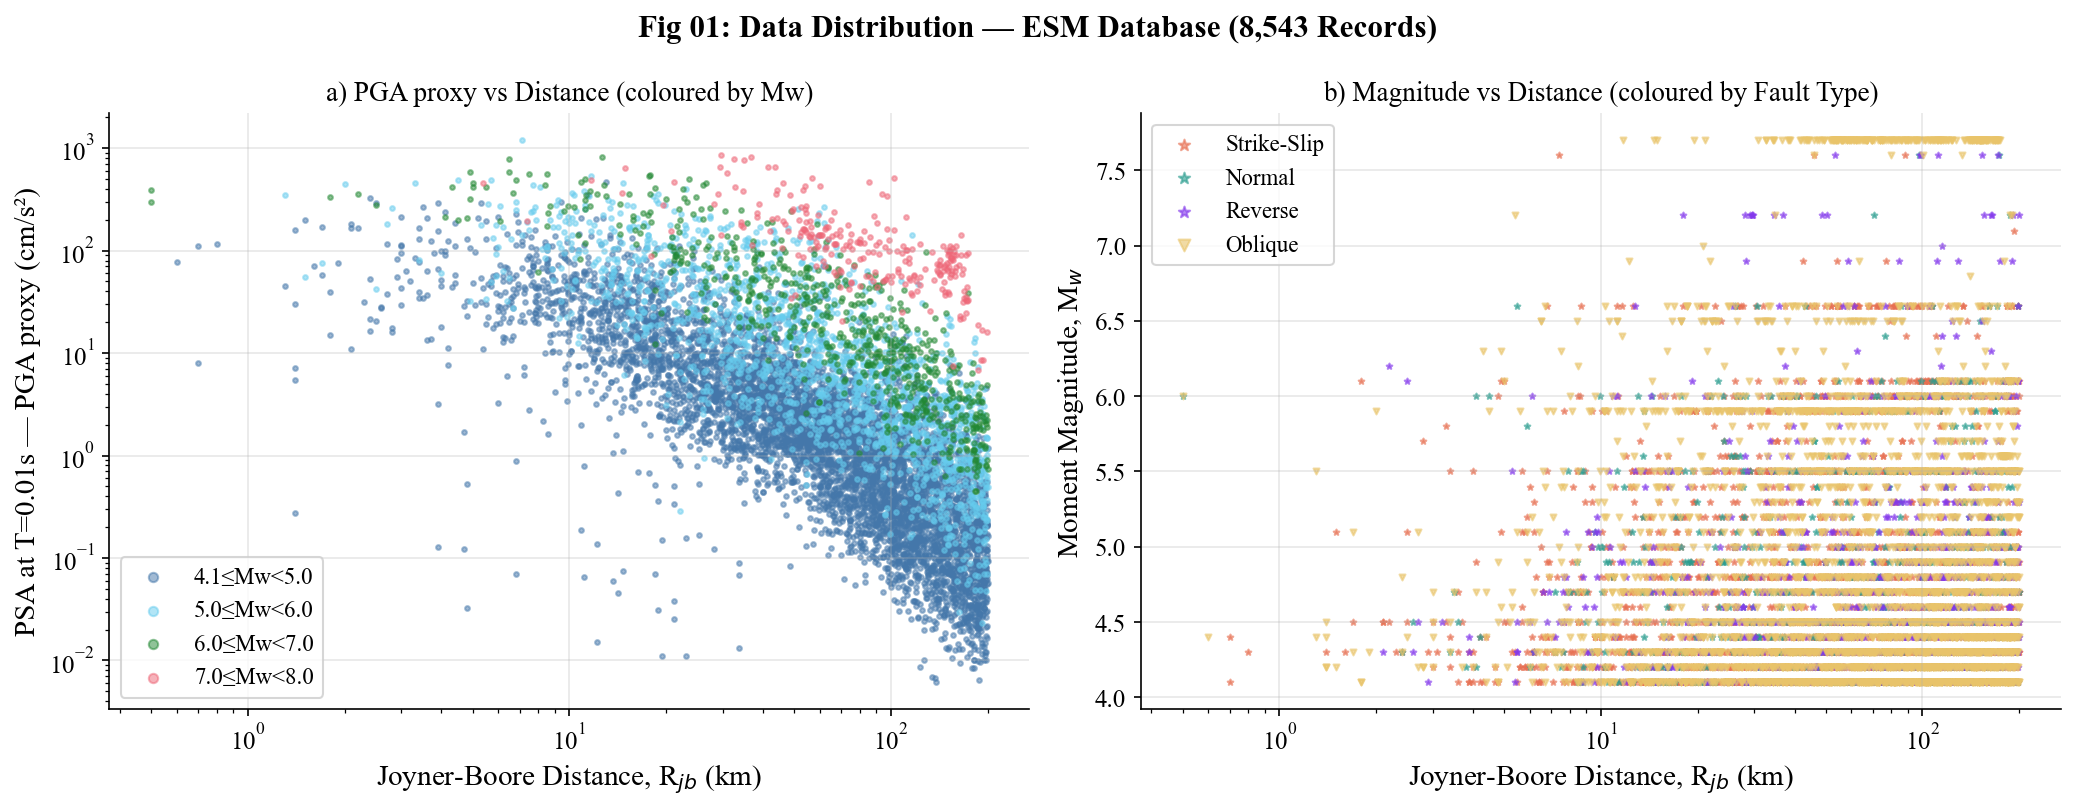

  → ./Report_Figures\Fig01_Data_Distribution.png


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
fig.suptitle("Fig 01: Data Distribution — ESM Database (8,543 Records)",
             fontsize=15, fontweight="bold")

# PGA vs Rjb coloured by Mw bin
ax = axes[0]
pga_col = "U_Hor_0.01"
pga_g   = df[pga_col].values
for mlo, mhi, col in MW_BINS:
    mask = (df["Mag"] >= mlo) & (df["Mag"] < mhi)
    ax.scatter(df.loc[mask,"R(km)"], pga_g[mask],
               s=5, alpha=0.5, color=col, label=f"{mlo}≤Mw<{mhi}", rasterized=True)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Joyner-Boore Distance, R$_{jb}$ (km)", fontsize=14)
ax.set_ylabel("PSA at T=0.01s — PGA proxy (cm/s²)", fontsize=14)
ax.set_title("a) PGA proxy vs Distance (coloured by Mw)", fontsize=13)
ax.legend(fontsize=11, markerscale=2)

# Mw vs Rjb coloured by fault type
ax = axes[1]
fault_colors = {1:"#E76F51", 2:"#2A9D8F", 3:"#8338EC", 4:"#E9C46A"}
fault_markers = {1:"*", 2:"*", 3:"*", 4:"v"}
for fcode, flabel in FAULT_LABELS.items():
    mask = df["Fault"] == fcode
    ax.scatter(df.loc[mask,"R(km)"], df.loc[mask,"Mag"],
               s=8, alpha=0.6, color=fault_colors[fcode],
               marker=fault_markers[fcode], label=flabel, rasterized=True)
ax.set_xscale("log")
ax.set_xlabel("Joyner-Boore Distance, R$_{jb}$ (km)", fontsize=14)
ax.set_ylabel("Moment Magnitude, M$_w$", fontsize=14)
ax.set_title("b) Magnitude vs Distance (coloured by Fault Type)", fontsize=13)
ax.legend(fontsize=11, markerscale=2)

plt.tight_layout()
savefig("Fig01_Data_Distribution.png")


### F02 — Statistics Plots (Histograms)

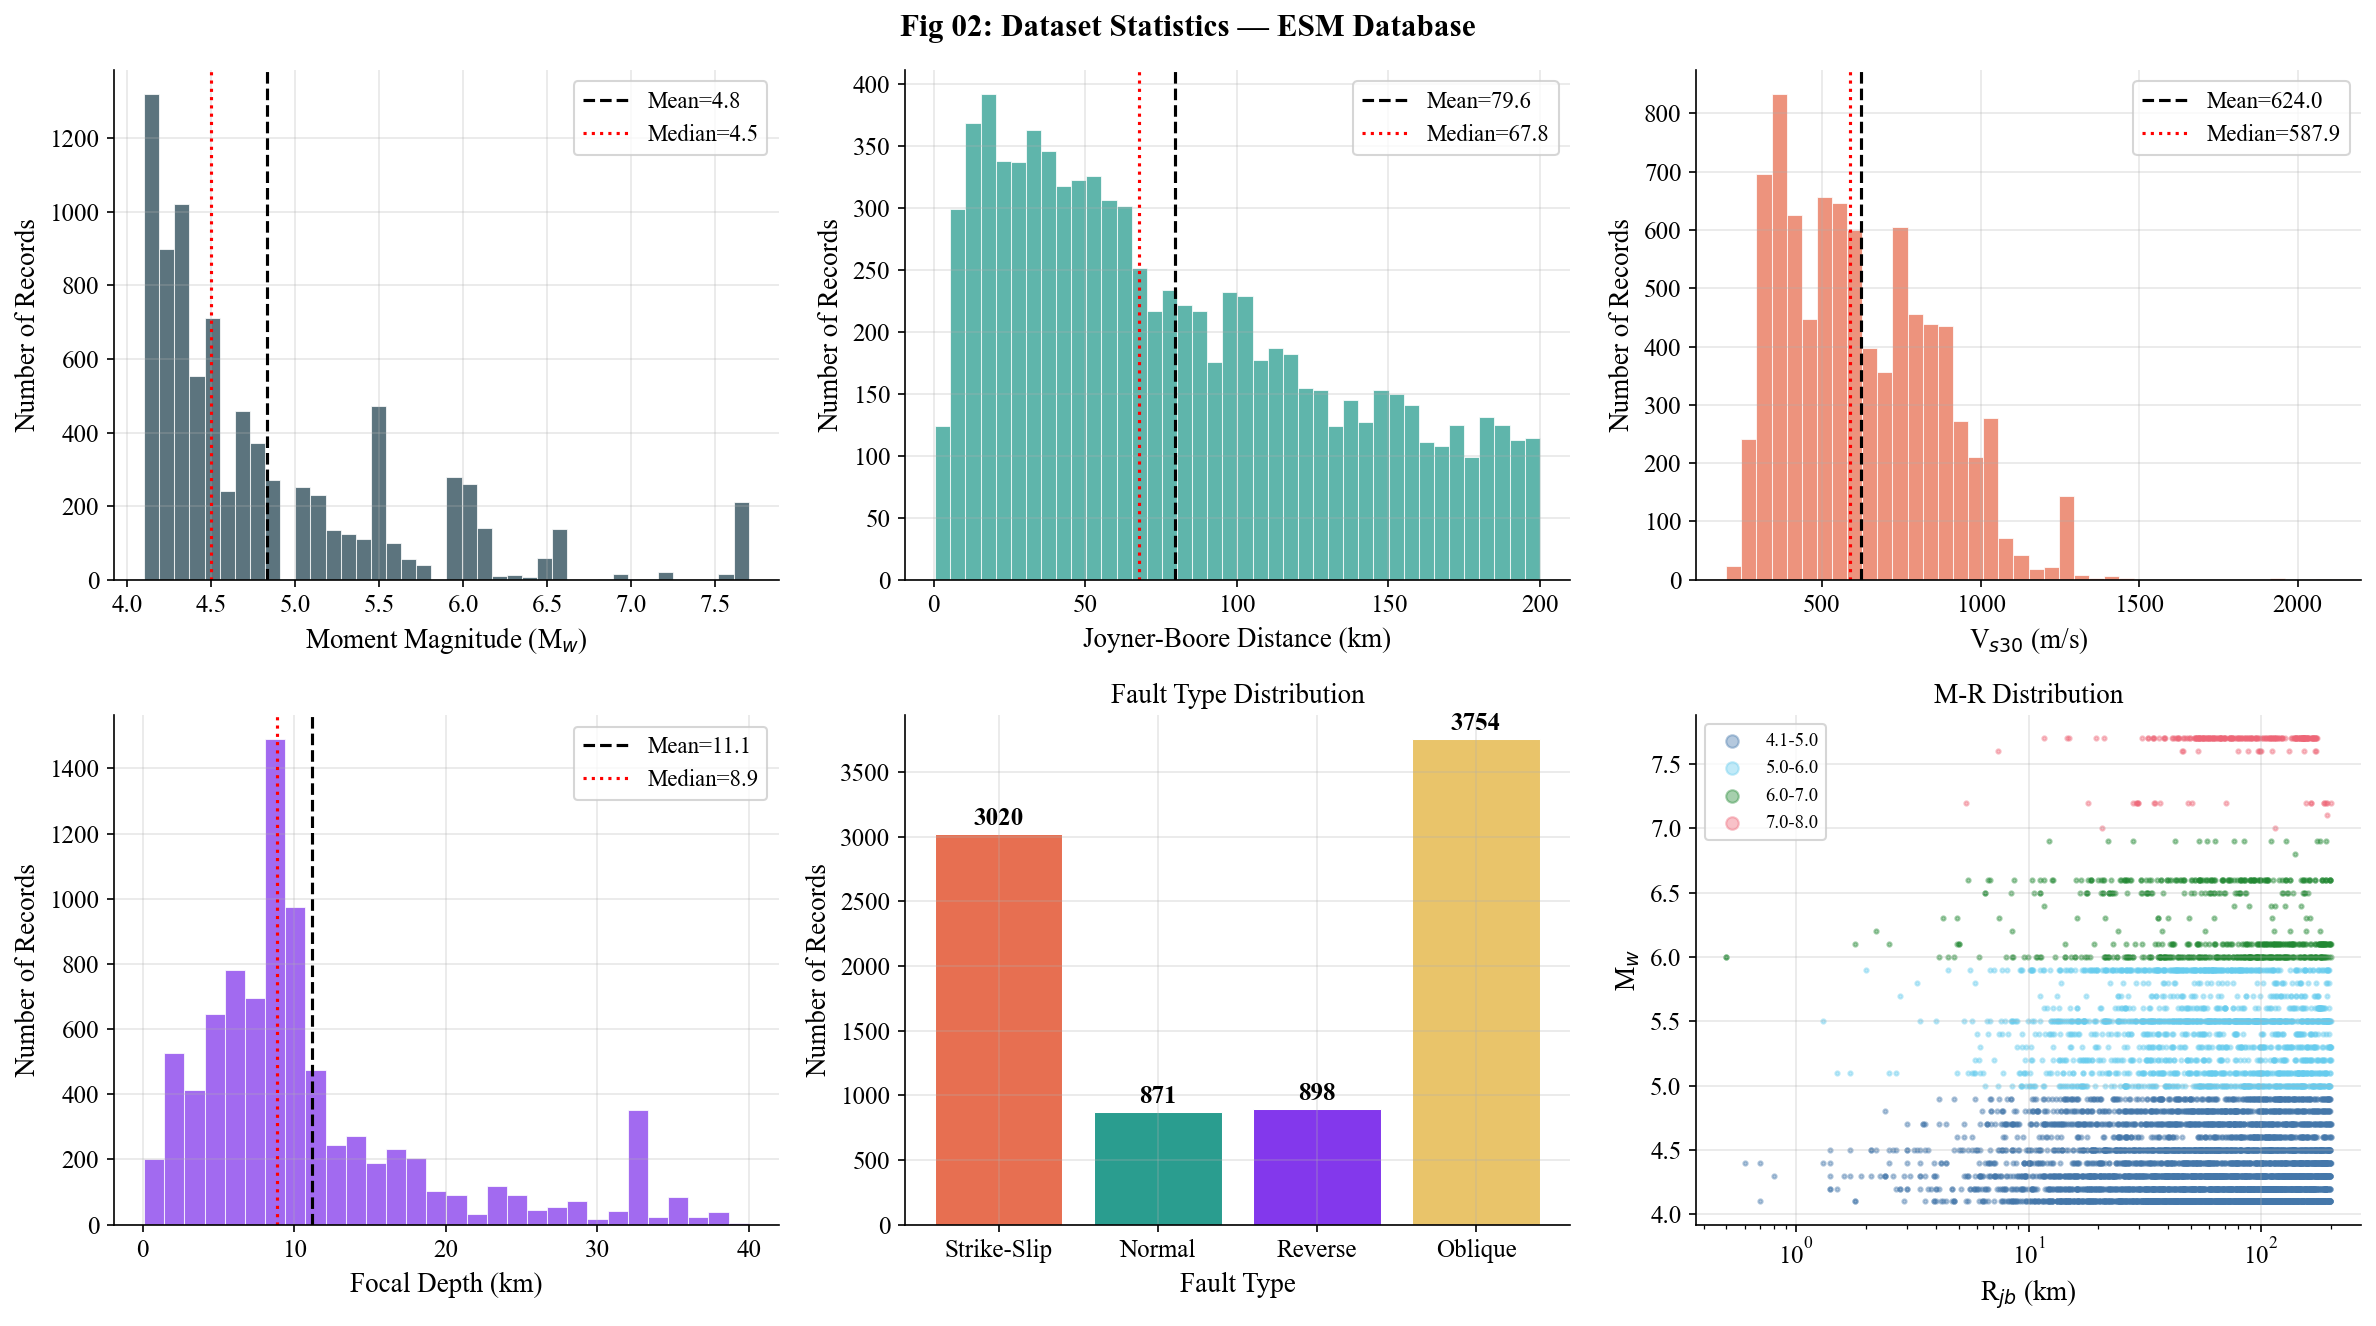

  → ./Report_Figures\Fig02_Statistics.png


In [12]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle("Fig 02: Dataset Statistics — ESM Database", fontsize=15, fontweight="bold")

hist_params = [
    ("Mag",       "Moment Magnitude (M$_w$)",      C["navy"],  40),
    ("R(km)",     "Joyner-Boore Distance (km)",     C["teal"],  40),
    ("Vs30(m/s)", "V$_{s30}$ (m/s)",                C["coral"], 40),
    ("Depth(km)", "Focal Depth (km)",               C["purple"],30),
]
fault_order = [1,2,3,4]
fault_col   = [C["coral"], C["teal"], C["purple"], C["amber"]]

# 4 histograms
for ax, (col, xlabel, color, bins) in zip(axes.flat[:4], hist_params):
    ax.hist(df[col], bins=bins, color=color, alpha=0.75, edgecolor="white", lw=0.5)
    ax.axvline(df[col].mean(), color="black", lw=1.5, ls="--",
               label=f"Mean={df[col].mean():.1f}")
    ax.axvline(df[col].median(), color="red", lw=1.5, ls=":",
               label=f"Median={df[col].median():.1f}")
    ax.set_xlabel(xlabel, fontsize=13)
    ax.set_ylabel("Number of Records", fontsize=13)
    ax.legend(fontsize=11)

# Fault type bar chart
ax = axes[1, 1]
counts = [df["Fault"].value_counts().get(f, 0) for f in fault_order]
bars = ax.bar([FAULT_LABELS[f] for f in fault_order], counts, color=fault_col, edgecolor="white", lw=0.5)
for bar, cnt in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()+30,
            str(cnt), ha="center", va="bottom", fontsize=12, fontweight="bold")
ax.set_xlabel("Fault Type", fontsize=13)
ax.set_ylabel("Number of Records", fontsize=13)
ax.set_title("Fault Type Distribution", fontsize=13)

# M-R scatter (compact)
ax = axes[1, 2]
for mlo, mhi, col in MW_BINS:
    mask = (df["Mag"] >= mlo) & (df["Mag"] < mhi)
    ax.scatter(df.loc[mask,"R(km)"], df.loc[mask,"Mag"],
               s=4, alpha=0.4, color=col, label=f"{mlo}-{mhi}", rasterized=True)
ax.set_xscale("log")
ax.set_xlabel("R$_{jb}$ (km)", fontsize=13)
ax.set_ylabel("M$_w$", fontsize=13)
ax.set_title("M-R Distribution", fontsize=13)
ax.legend(fontsize=9, markerscale=3)

plt.tight_layout()
savefig("Fig02_Statistics.png")


### F03 — Network Architecture Diagram

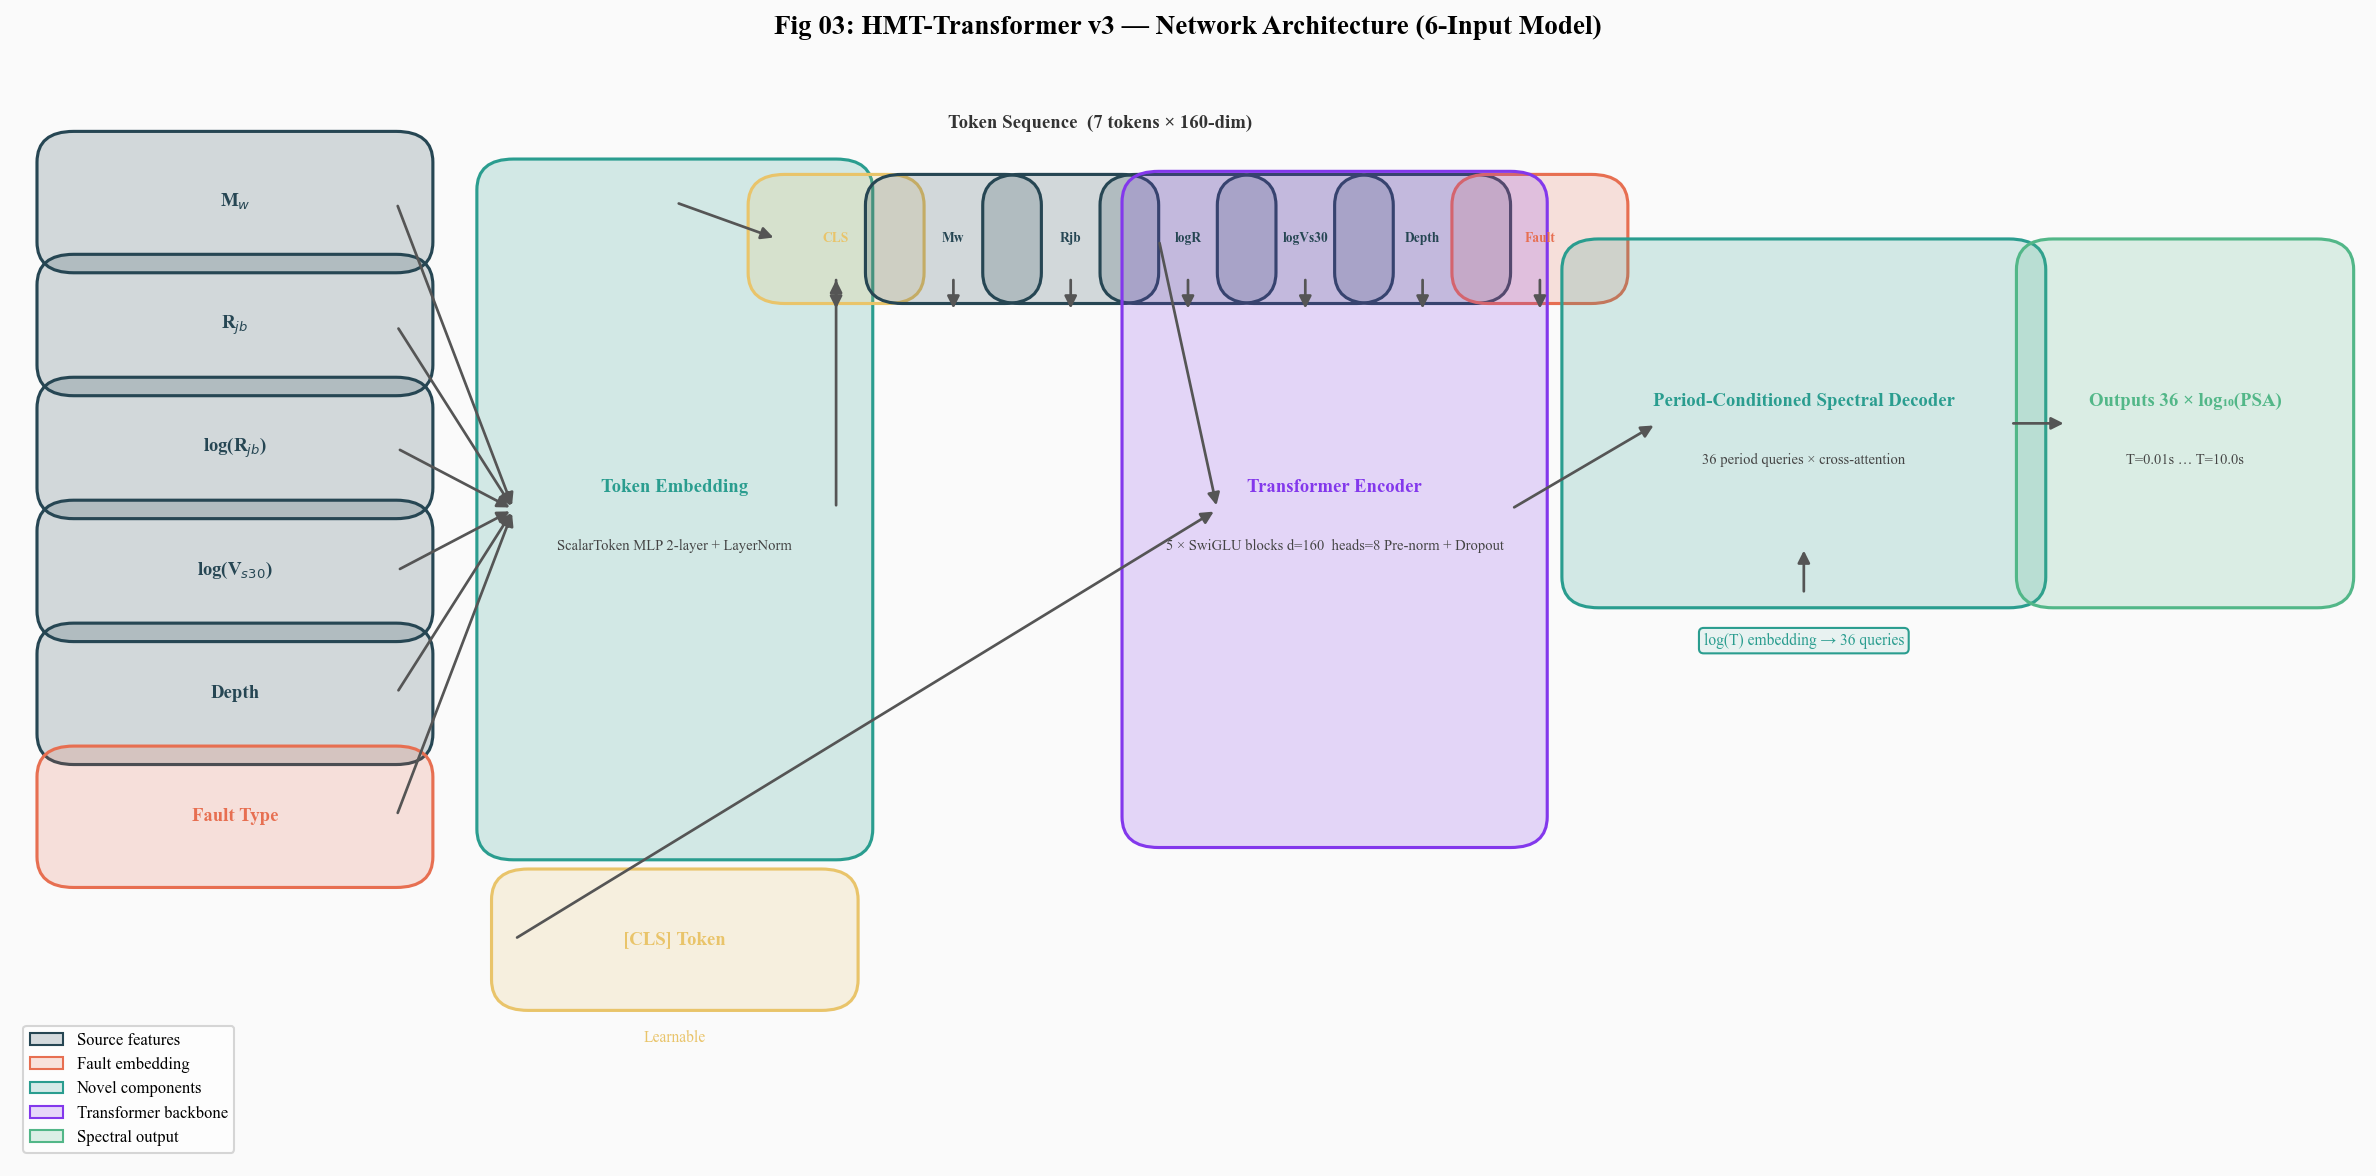

  → ./Report_Figures\Fig03_Architecture.png


In [13]:
fig, ax = plt.subplots(figsize=(16, 8))
ax.set_xlim(0, 16); ax.set_ylim(0, 9); ax.axis("off")
fig.patch.set_facecolor("#FAFAFA")

def dbox(ax, x, y, w, h, text, color, sub=None, fs=9):
    from matplotlib.patches import FancyBboxPatch
    p = FancyBboxPatch((x-w/2, y-h/2), w, h,
                       boxstyle="round,pad=0.25", lw=1.5,
                       facecolor=color+"30", edgecolor=color, zorder=3)
    ax.add_patch(p)
    ax.text(x, y+(0.18 if sub else 0), text, ha="center", va="center",
            fontsize=fs, fontweight="bold", color=color, zorder=4)
    if sub:
        ax.text(x, y-0.30, sub, ha="center", va="center",
                fontsize=7, color="#444", zorder=4)

def arr(ax, x1,y1,x2,y2, col="#555"):
    ax.annotate("", xy=(x2,y2), xytext=(x1,y1),
                arrowprops=dict(arrowstyle="-|>", color=col, lw=1.3), zorder=5)

ax.set_title("Fig 03: HMT-Transformer v3 — Network Architecture (6-Input Model)",
             fontsize=13, fontweight="bold", pad=10)

# ── Input features (UPDATED) ─────────────────────────────────────────────
inp_labels = [
    "M$_w$",
    "R$_{jb}$",
    "log(R$_{jb}$)",   # FIXED
    "log(V$_{s30}$)",
    "Depth",
    "Fault Type"
]

inp_colors = [C["navy"]]*5 + [C["coral"]]

inp_y = [7.8, 6.8, 5.8, 4.8, 3.8, 2.8]

for lbl, yy, col in zip(inp_labels, inp_y, inp_colors):
    dbox(ax, 1.5, yy, 2.2, 0.65, lbl, col, fs=9)

# ── Embedding layer ─────────────────────────────────────────────────────
dbox(ax, 4.5, 5.3, 2.2, 5.2, "Token Embedding", C["teal"],
     "ScalarToken MLP 2-layer + LayerNorm", fs=9)

for yy in inp_y:
    arr(ax, 2.6, yy, 3.4, 5.3)

# ── CLS token ───────────────────────────────────────────────────────────
dbox(ax, 4.5, 1.8, 2.0, 0.65, "[CLS] Token", C["amber"], fs=9)
ax.text(4.5, 1.0, "Learnable", ha="center", va="center",
        fontsize=7.5, color=C["amber"])

# ── Token sequence (UPDATED) ────────────────────────────────────────────
ax.text(7.4, 8.4, "Token Sequence  (7 tokens × 160-dim)",
        ha="center", fontsize=9, color="#333", fontweight="bold")

token_labels = ["CLS","Mw","Rjb","logR","logVs30","Depth","Fault"]
token_colors = [
    C["amber"],C["navy"],C["navy"],C["navy"],
    C["navy"],C["navy"],C["coral"]
]

for i, (lbl, col) in enumerate(zip(token_labels, token_colors)):
    dbox(ax, 5.6 + i*0.8, 7.5, 0.70, 0.55, lbl, col, fs=6.5)

for i in range(7):
    arr(ax, 5.6+i*0.8, 7.2, 5.6+i*0.8, 6.9)

arr(ax, 4.5, 7.8, 5.2, 7.5)  # CLS
arr(ax, 5.6, 5.3, 5.6, 7.2)  # features

# ── Transformer ─────────────────────────────────────────────────────────
dbox(ax, 9.0, 5.3, 2.4, 5.0, "Transformer Encoder", C["purple"],
     "5 × SwiGLU blocks d=160  heads=8 Pre-norm + Dropout", fs=9)

arr(ax, 7.8, 7.5, 8.2, 5.3)
arr(ax, 3.4, 1.8, 8.2, 5.3)

# ── Decoder ─────────────────────────────────────────────────────────────
dbox(ax, 12.2, 6.0, 2.8, 2.5,
     "Period-Conditioned Spectral Decoder",
     C["teal"], "36 period queries × cross-attention", fs=9)

arr(ax, 10.2, 5.3, 11.2, 6.0)

# Period queries
ax.text(12.2, 4.2, "log(T) embedding → 36 queries",
        ha="center", fontsize=7.5, color=C["teal"],
        bbox=dict(boxstyle="round", fc=C["teal"]+"15", ec=C["teal"], lw=1))

arr(ax, 12.2, 4.6, 12.2, 5.0)

# ── Outputs ─────────────────────────────────────────────────────────────
dbox(ax, 14.8, 6.0, 1.8, 2.5,
     "Outputs 36 × log₁₀(PSA)", C["green"],
     "T=0.01s … T=10.0s", fs=9)

arr(ax, 13.6, 6.0, 14.0, 6.0)

# ── Legend ──────────────────────────────────────────────────────────────
import matplotlib.patches as mpatches

legend_items = [
    mpatches.Patch(facecolor=C["navy"]+"30",  edgecolor=C["navy"],  label="Source features"),
    mpatches.Patch(facecolor=C["coral"]+"30", edgecolor=C["coral"], label="Fault embedding"),
    mpatches.Patch(facecolor=C["teal"]+"30",  edgecolor=C["teal"],  label="Novel components"),
    mpatches.Patch(facecolor=C["purple"]+"30",edgecolor=C["purple"],label="Transformer backbone"),
    mpatches.Patch(facecolor=C["green"]+"30", edgecolor=C["green"], label="Spectral output"),
]

ax.legend(handles=legend_items, loc="lower left", fontsize=8, framealpha=0.8)

plt.tight_layout()
savefig("Fig03_Architecture.png")

### F04 — Hyperparameter Tuning Sensitivity

In [14]:
# Quick sensitivity study — trains a mini-model (d=64, 2 layers) for 20 epochs
# on 10% of training data to show hyperparameter trends efficiently

from sklearn.utils import resample

MINI_N   = min(1000, len(tr_i))
mini_idx = resample(np.arange(len(tr_i)), n_samples=MINI_N, random_state=42)

def mini_loader(Xs_full, Y_full, f_full, mw_full, idx, b=128):
    ds = TensorDataset(torch.from_numpy(Xs_full[idx]),
                       torch.from_numpy(f_full[idx].astype(np.int64)),
                       torch.from_numpy(Y_full[idx]),
                       torch.from_numpy(mw_full[idx]))
    return DataLoader(ds, batch_size=b, shuffle=True)

def quick_eval(m, Xvs, fvs, Yvs, mw_vs):
    m.eval(); vl = 0.0
    ld = DataLoader(
        TensorDataset(torch.from_numpy(Xvs), torch.from_numpy(fvs.astype(np.int64)),
                      torch.from_numpy(Yvs), torch.from_numpy(mw_vs)),
        batch_size=256)
    with torch.no_grad():
        for xs_b, f_b, y_b, mw_b in ld:
            xs_b, f_b, y_b, mw_b = (t.to(DEVICE) for t in (xs_b, f_b, y_b, mw_b))
            vl += physics_loss(m(xs_b, f_b), y_b, mw_b).item() * xs_b.size(0)
    return vl / len(ld.dataset)

def mini_train(d=64, n_layers=2, lr=1e-3, batch=128, dropout=0.1, n_ep=20):
    m = HMTv3_5inp(n_faults=n_faults, d=d, n_heads=4,
                    n_layers=n_layers, dropout=dropout).to(DEVICE)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=3e-4)
    ld  = mini_loader(X5_tr, Y_tr, f_tr, mw_tr, mini_idx, b=batch)
    for ep in range(n_ep):
        m.train()
        for xs_b, f_b, y_b, mw_b in ld:
            xs_b, f_b, y_b, mw_b = (t.to(DEVICE) for t in (xs_b, f_b, y_b, mw_b))
            opt.zero_grad()
            physics_loss(m(xs_b, f_b), y_b, mw_b).backward()
            nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
    return quick_eval(m, X5_val, f_val, Y_val, mw_raw[val_i])

print("Running hyperparameter sensitivity (this takes ~1-2 min) ...")

hp_results = {}
# a) Learning rate
lrs = [1e-5, 5e-5, 1e-4, 5e-4, 1e-3]
hp_results["lr"] = [mini_train(lr=v) for v in lrs]
print("  LR done")
# b) Batch size
batches = [64, 128, 256, 512]
hp_results["batch"] = [mini_train(batch=v) for v in batches]
print("  Batch done")
# c) d_model
dmodels = [64, 96, 128, 160, 192]
hp_results["d_model"] = [mini_train(d=v) for v in dmodels]
print("  d_model done")
# d) n_layers
n_layers_list = [2, 3, 4, 5, 6]
hp_results["n_layers"] = [mini_train(n_layers=v) for v in n_layers_list]
print("  n_layers done")
# e) Dropout
dropouts = [0.0, 0.05, 0.1, 0.15, 0.2]
hp_results["dropout"] = [mini_train(dropout=v) for v in dropouts]
print("  Dropout done")
print("Hyperparameter search complete")


Running hyperparameter sensitivity (this takes ~1-2 min) ...
  LR done
  Batch done
  d_model done
  n_layers done
  Dropout done
Hyperparameter search complete


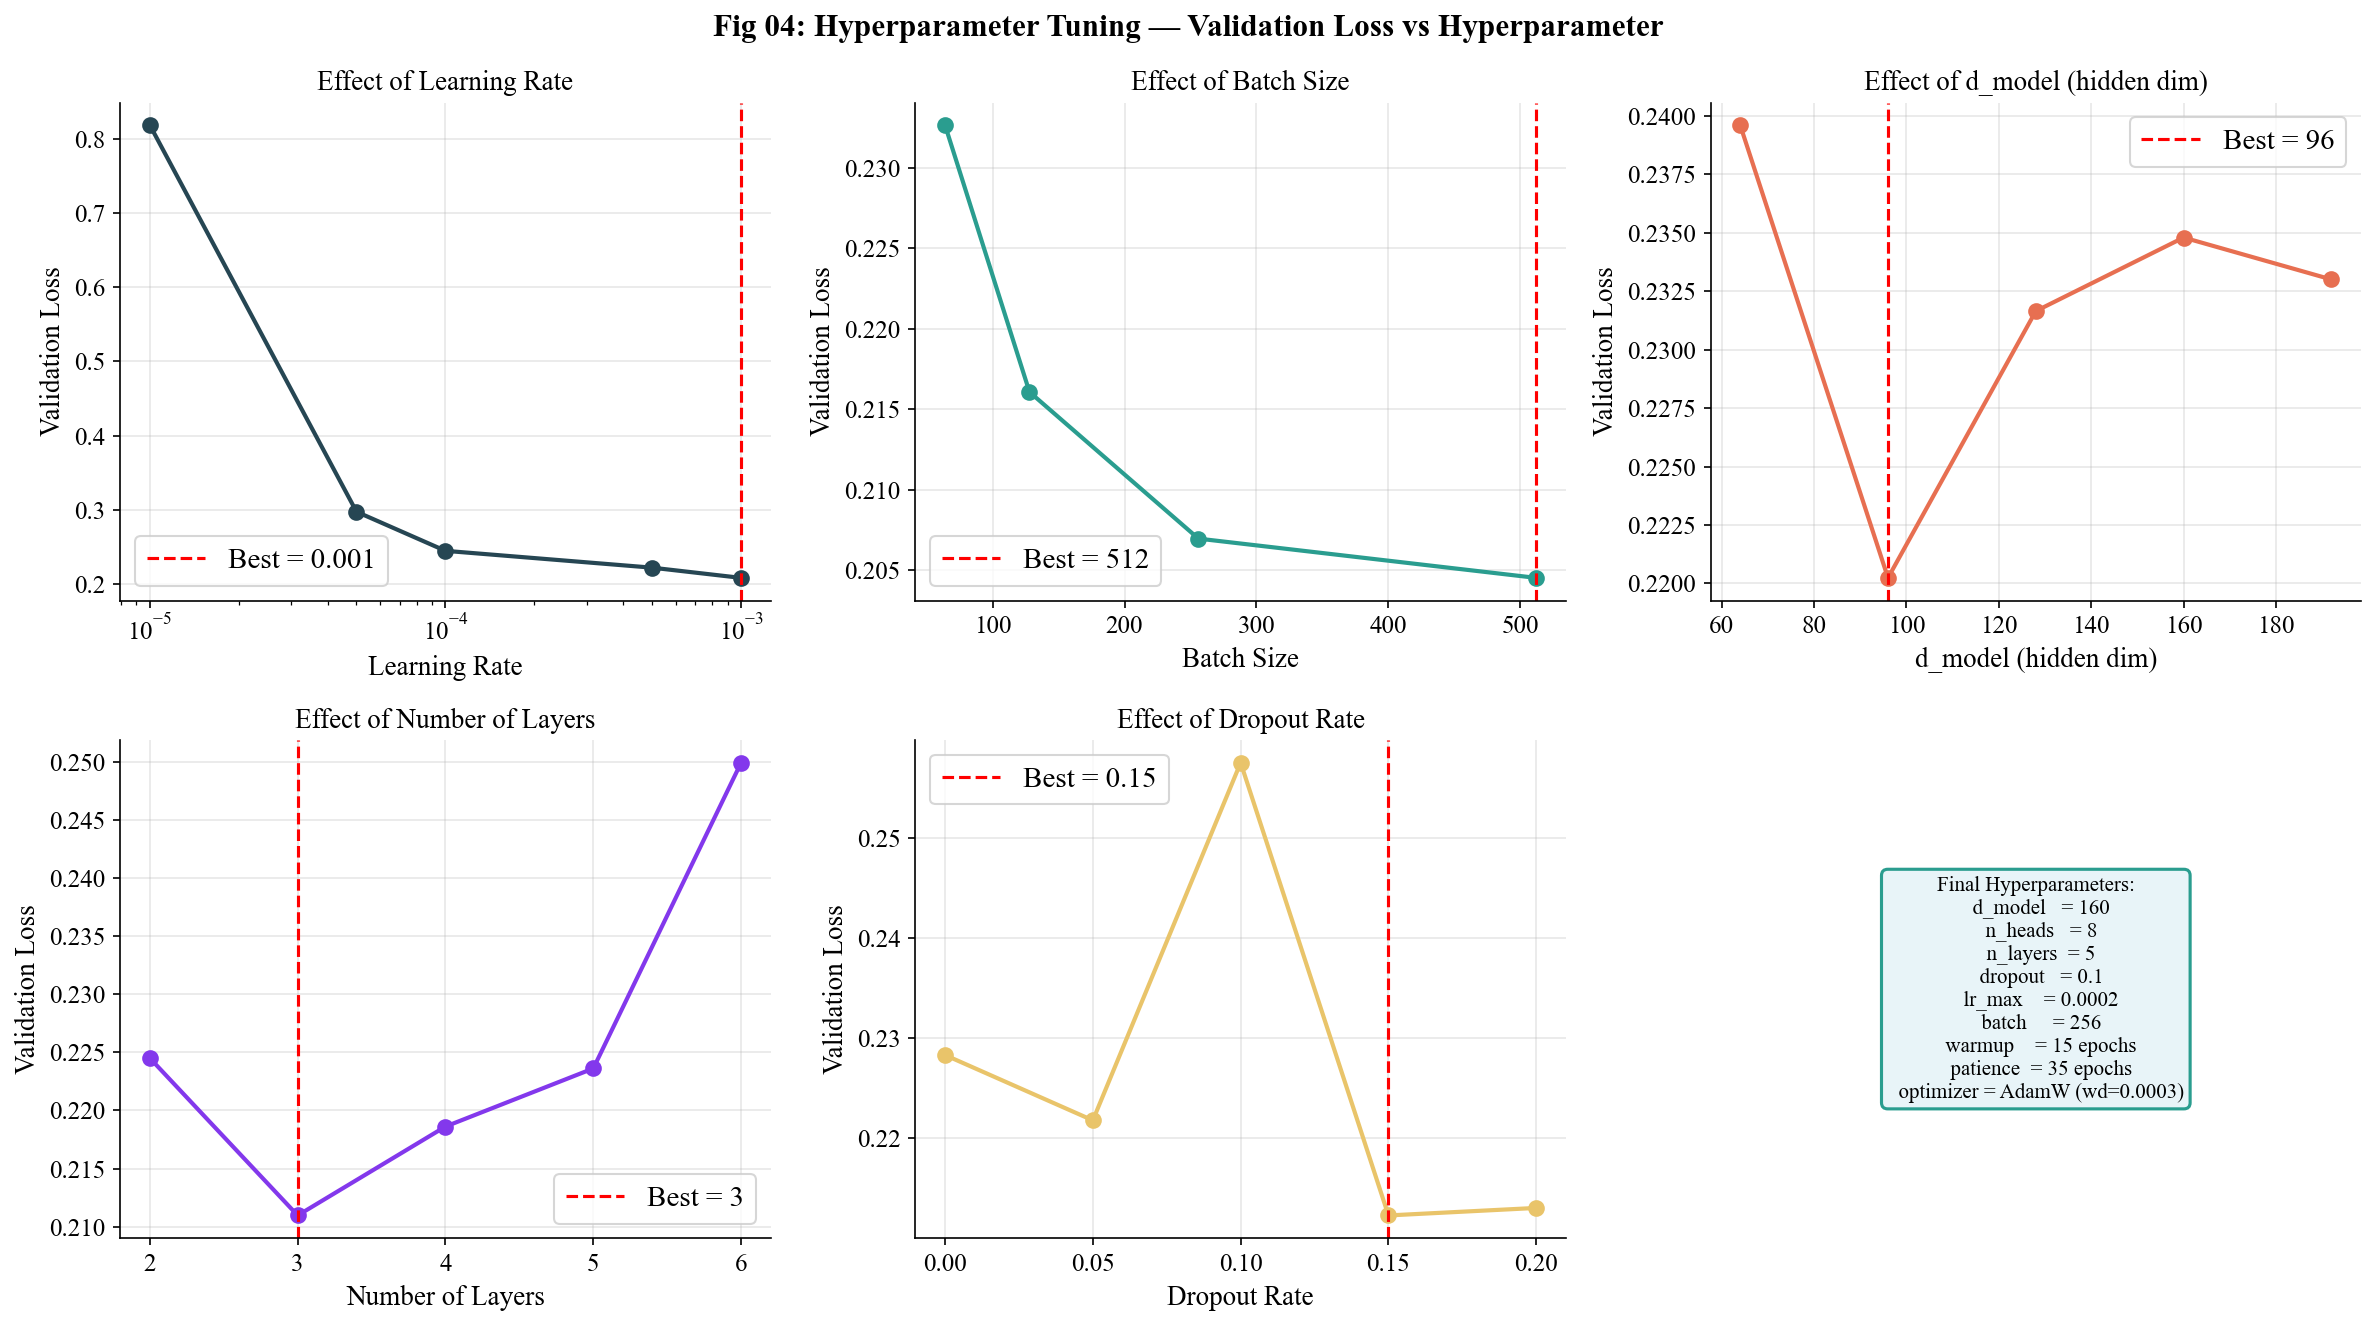

  → ./Report_Figures\Fig04_Hyperparameter_Tuning.png


In [15]:
# ── Plot hyperparameter tuning results ───────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle("Fig 04: Hyperparameter Tuning — Validation Loss vs Hyperparameter",
             fontsize=15, fontweight="bold")

hp_configs = [
    ("lr",       "Learning Rate",        lrs,            True,  C["navy"]),
    ("batch",    "Batch Size",           batches,         False, C["teal"]),
    ("d_model",  "d_model (hidden dim)", dmodels,         False, C["coral"]),
    ("n_layers", "Number of Layers",     n_layers_list,   False, C["purple"]),
    ("dropout",  "Dropout Rate",         dropouts,        False, C["amber"]),
]

for ax, (key, xlabel, xvals, log_x, color) in zip(axes.flat, hp_configs):
    vals = hp_results[key]
    best_idx = int(np.argmin(vals))
    ax.plot(xvals, vals, "o-", color=color, lw=2, ms=7)
    ax.axvline(xvals[best_idx], color="red", lw=1.5, ls="--",
               label=f"Best = {xvals[best_idx]}")
    ax.set_xlabel(xlabel, fontsize=13)
    ax.set_ylabel("Validation Loss", fontsize=13)
    if log_x: ax.set_xscale("log")
    ax.legend(fontsize=14)
    ax.set_title(f"Effect of {xlabel}", fontsize=13)

axes[1, 2].axis("off")
axes[1, 2].text(0.5, 0.5,
    f"Final Hyperparameters:\n"
    f"  d_model   = {CFG.d_model}\n"
    f"  n_heads   = {CFG.n_heads}\n"
    f"  n_layers  = {CFG.n_layers}\n"
    f"  dropout   = {CFG.dropout}\n"
    f"  lr_max    = {CFG.lr_max}\n"
    f"  batch     = {CFG.batch}\n"
    f"  warmup    = {CFG.warmup} epochs\n"
    f"  patience  = {CFG.patience} epochs\n"
    f"  optimizer = AdamW (wd={CFG.wd})",
    ha="center", va="center", fontsize=10,
    transform=axes[1,2].transAxes,
    bbox=dict(boxstyle="round", fc="#e8f4f8", ec=C["teal"], lw=1.5))

plt.tight_layout()
savefig("Fig04_Hyperparameter_Tuning.png")


### F05 — Regression Plots (Actual vs Predicted, log₁₀ scale)

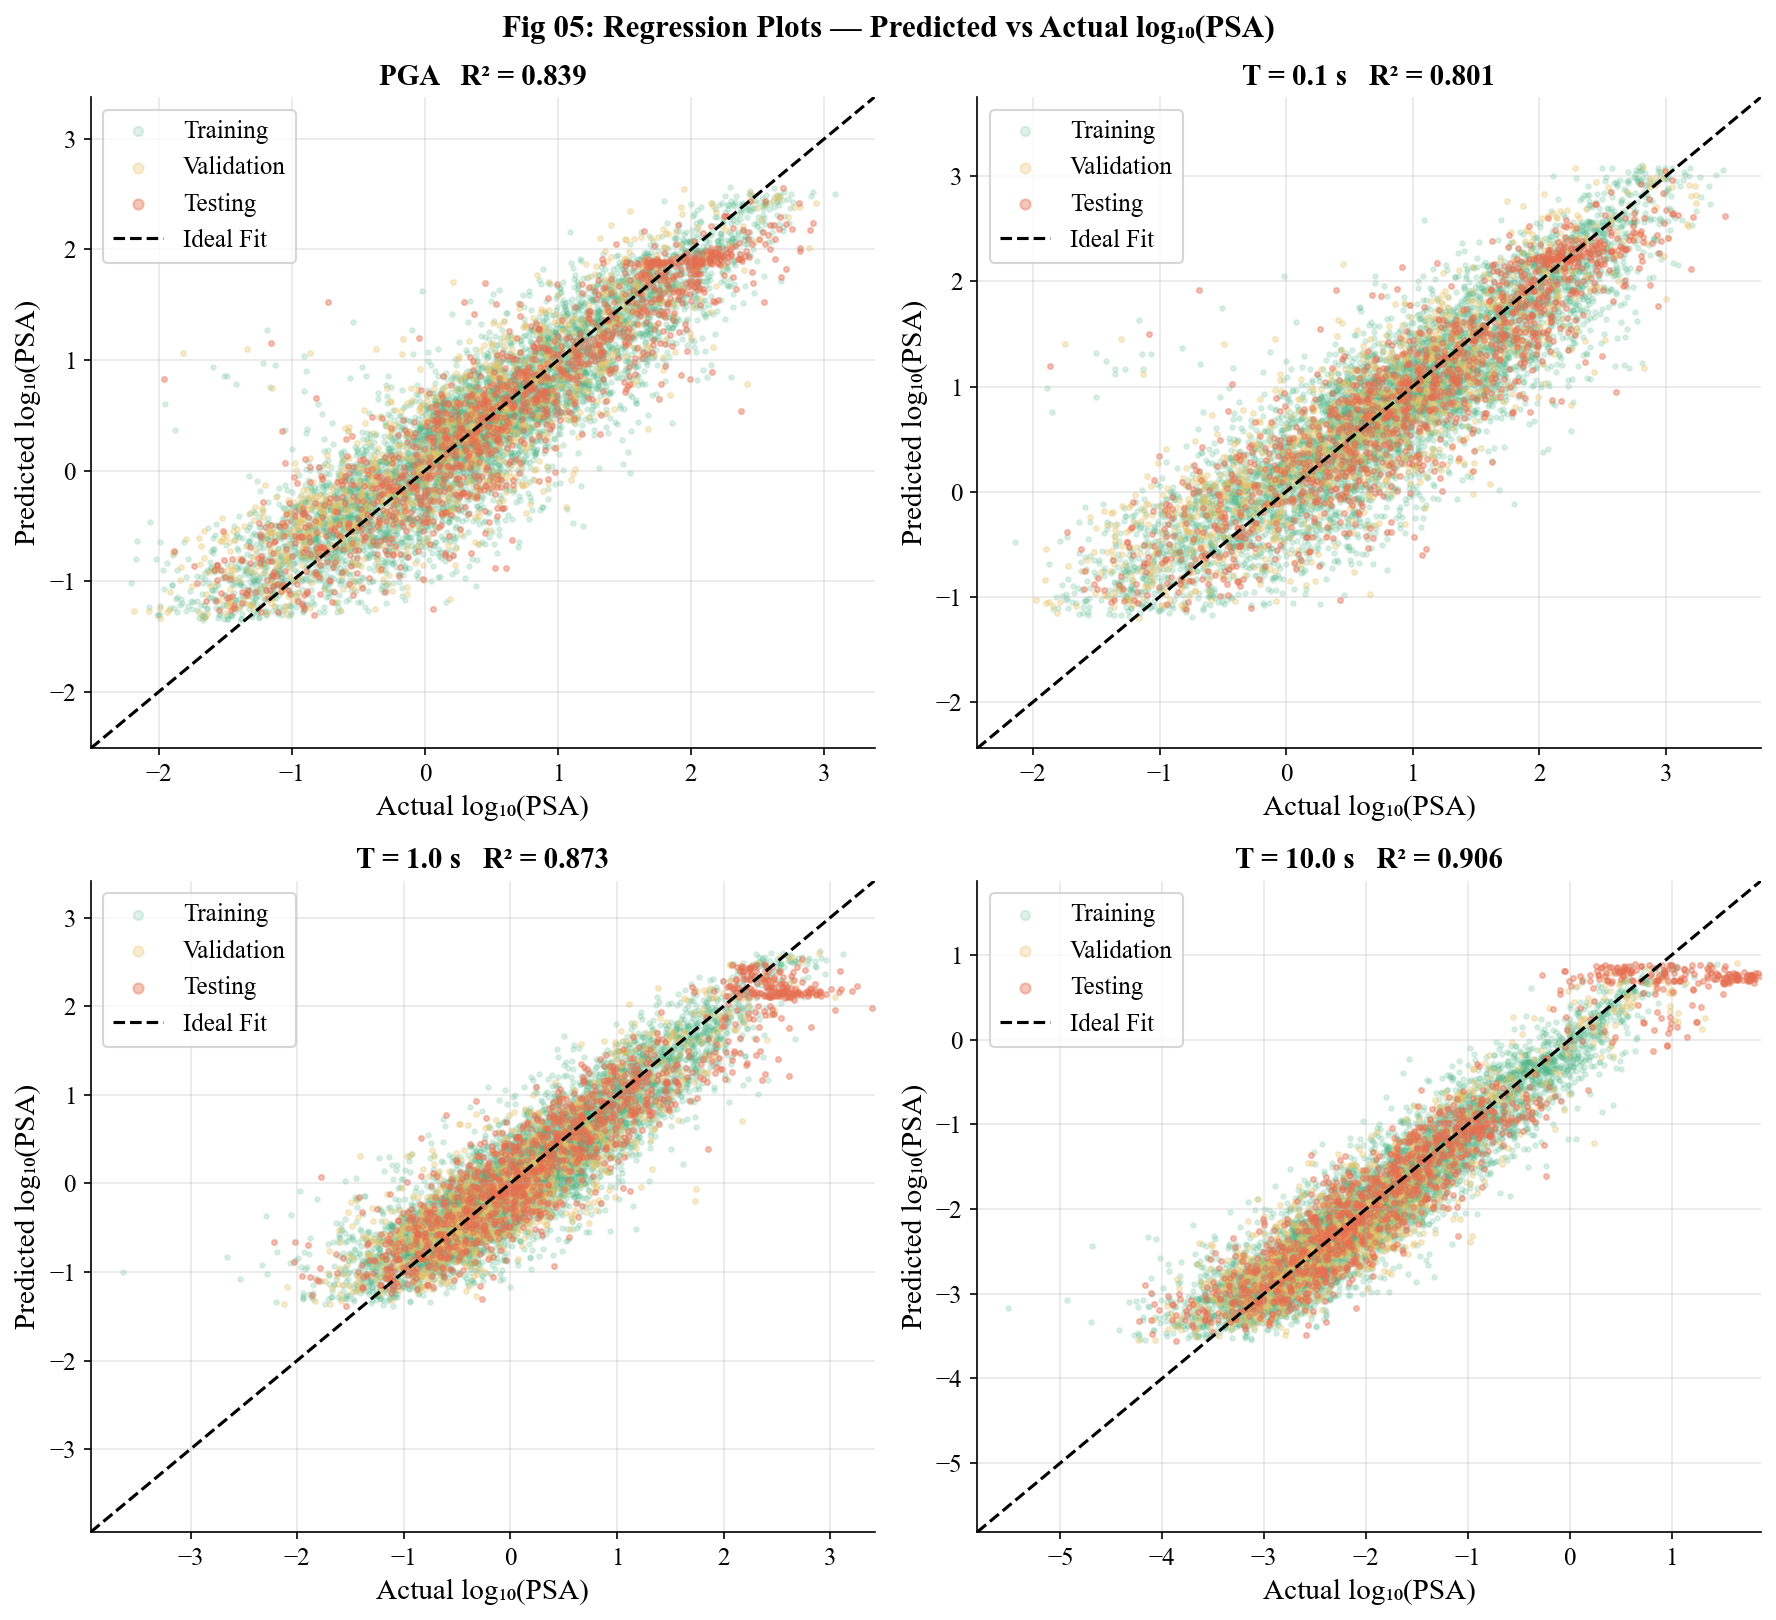

  → ./Report_Figures\Fig05_Regression_Plots.png


In [16]:
# 4 representative periods: PGA proxy, T=0.1s, T=1.0s, T=10.0s
rep_idx  = [PGA_IDX, 5, 19, 35]
rep_lbls = ["PGA", "T = 0.1 s", "T = 1.0 s", "T = 10.0 s"]

fig, axes = plt.subplots(2, 2, figsize=(12, 11))
fig.suptitle("Fig 05: Regression Plots — Predicted vs Actual log₁₀(PSA)",
             fontsize=15, fontweight="bold")

for ax, k, lbl in zip(axes.flat, rep_idx, rep_lbls):
    # Train
    ax.scatter(true5_tr[:,k], pred5_tr[:,k],
               s=5, alpha=0.18, color=C["green"], label="Training", rasterized=True)
    # Val
    ax.scatter(true5_val[:,k], pred5_val[:,k],
               s=6, alpha=0.30, color=C["amber"], label="Validation", rasterized=True)
    # Test
    ax.scatter(true5_te[:,k], pred5_te[:,k],
               s=6, alpha=0.40, color=C["coral"], label="Testing", rasterized=True)

    r2 = r2_score(true5_te[:,k], pred5_te[:,k])
    lim = [min(true5_tr[:,k].min(), pred5_tr[:,k].min()) - 0.3,
           max(true5_tr[:,k].max(), pred5_tr[:,k].max()) + 0.3]
    ax.plot(lim, lim, "k--", lw=1.5, label="Ideal Fit")
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("Actual log₁₀(PSA)", fontsize=14)
    ax.set_ylabel("Predicted log₁₀(PSA)", fontsize=14)
    ax.set_title(f"{lbl}   R² = {r2:.3f}", fontsize=14, fontweight="bold")
    ax.legend(fontsize=12, markerscale=2)

plt.tight_layout()
savefig("Fig05_Regression_Plots.png")


### F06 — Residual Analysis

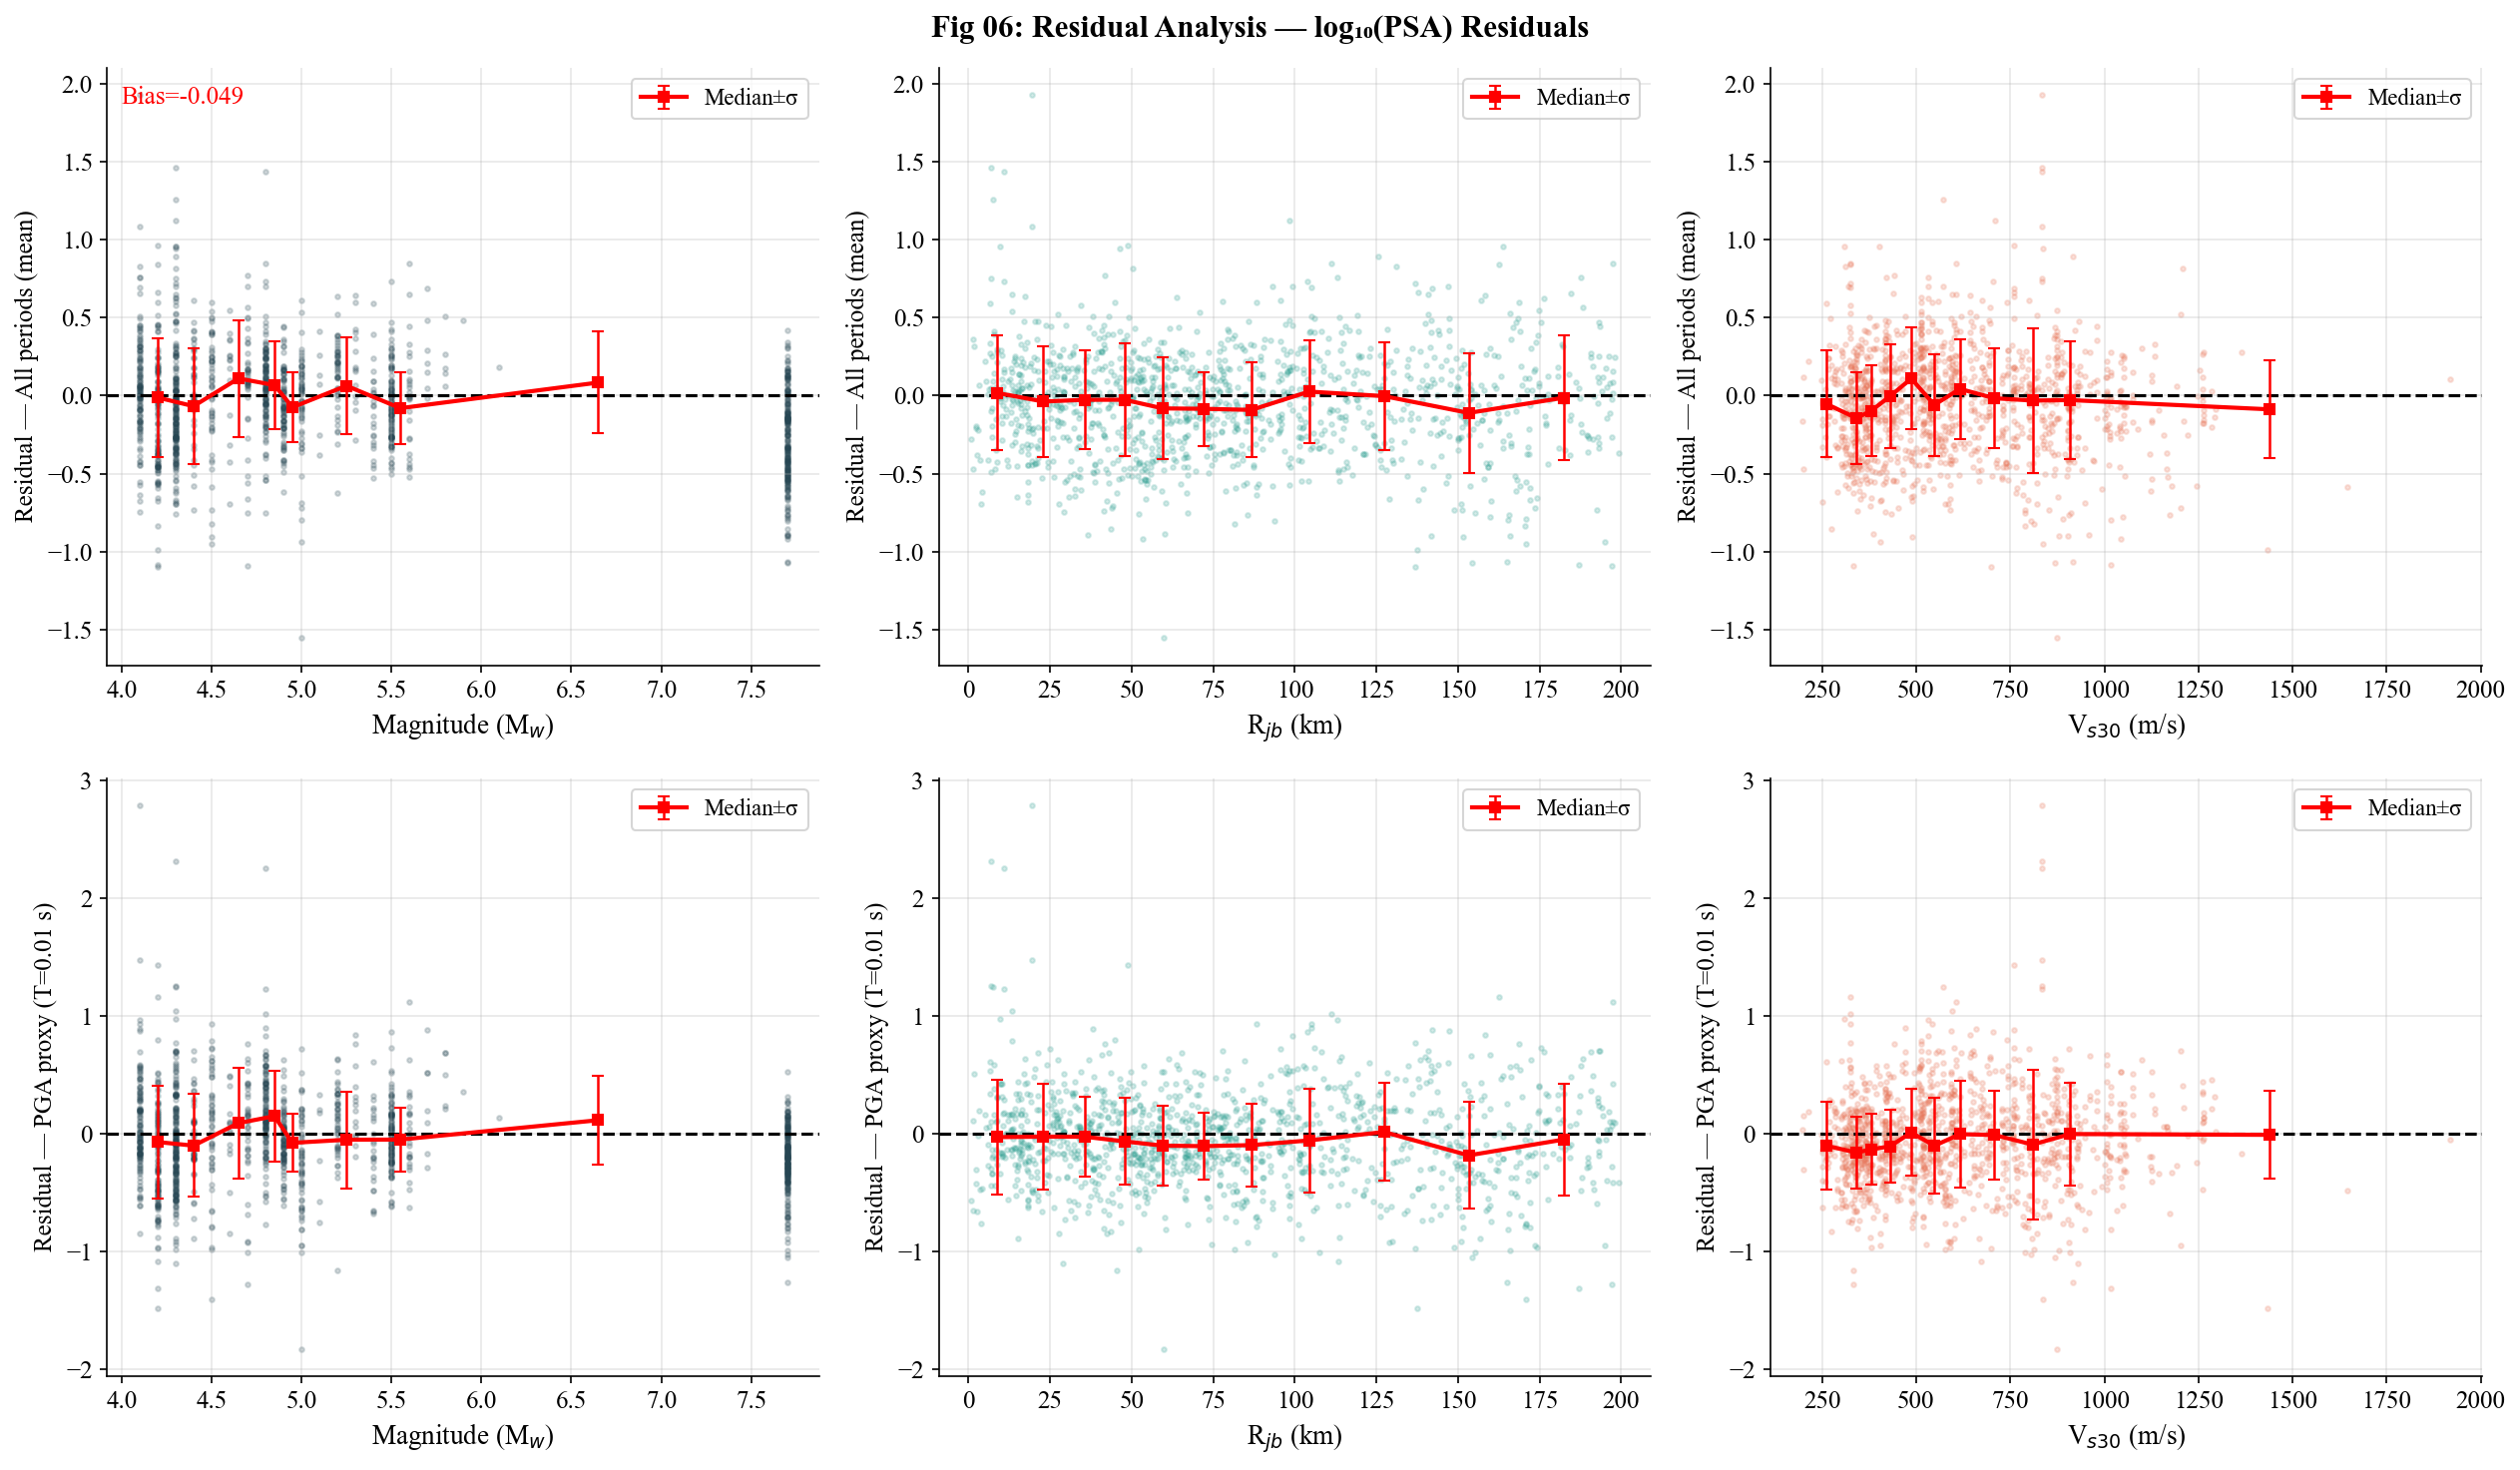

  → ./Report_Figures\Fig06_Residual_Analysis.png


In [17]:
te_df = df.iloc[te_i].reset_index(drop=True)

# Residuals in log₁₀ space
resid_all = pred5_te - true5_te                     # (N_test, 36)
resid_mean= resid_all.mean(axis=1)                  # mean over periods
resid_pga = resid_all[:, PGA_IDX]                   # PGA proxy only

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
fig.suptitle("Fig 06: Residual Analysis — log₁₀(PSA) Residuals",
             fontsize=15, fontweight="bold")

panels = [
    (resid_mean, "All periods (mean)",   0),
    (resid_pga,  "PGA proxy (T=0.01 s)", 1),
]
xcols = [("Mag","Magnitude (M$_w$)",C["navy"]),
         ("R(km)","R$_{jb}$ (km)",C["teal"]),
         ("Vs30(m/s)","V$_{s30}$ (m/s)",C["coral"])]

for row, (resid, row_title, _) in enumerate(panels):
    for col, (feat, xlabel, color) in enumerate(xcols):
        ax = axes[row, col]
        ax.scatter(te_df[feat], resid,
                   alpha=0.20, s=5, color=color, rasterized=True)
        ax.axhline(0, color="black", lw=1.5, ls="--")

        # Running median ± σ bins
        bins = np.percentile(te_df[feat], np.linspace(0, 100, 12))
        bx, by, bs = [], [], []
        for i in range(len(bins)-1):
            m = (te_df[feat] >= bins[i]) & (te_df[feat] < bins[i+1])
            if m.sum() > 5:
                bx.append((bins[i]+bins[i+1])/2)
                by.append(float(np.median(resid[m])))
                bs.append(float(resid[m].std()))
        ax.errorbar(bx, by, yerr=bs, fmt="s-", color="red",
                    ms=5, lw=2, elinewidth=1.2, capsize=3, label="Median±σ")

        ax.set_xlabel(xlabel, fontsize=13)
        ax.set_ylabel(f"Residual — {row_title}", fontsize=12)
        ax.legend(fontsize=11)
        if row == 0 and col == 0:
            ax.text(0.02, 0.97, f"Bias={resid_mean.mean():.3f}",
                    transform=ax.transAxes, fontsize=12,
                    va="top", color="red")


plt.tight_layout()
savefig("Fig06_Residual_Analysis.png")


### F07 — Standard Deviation (Inter-event / Intra-event / Total)

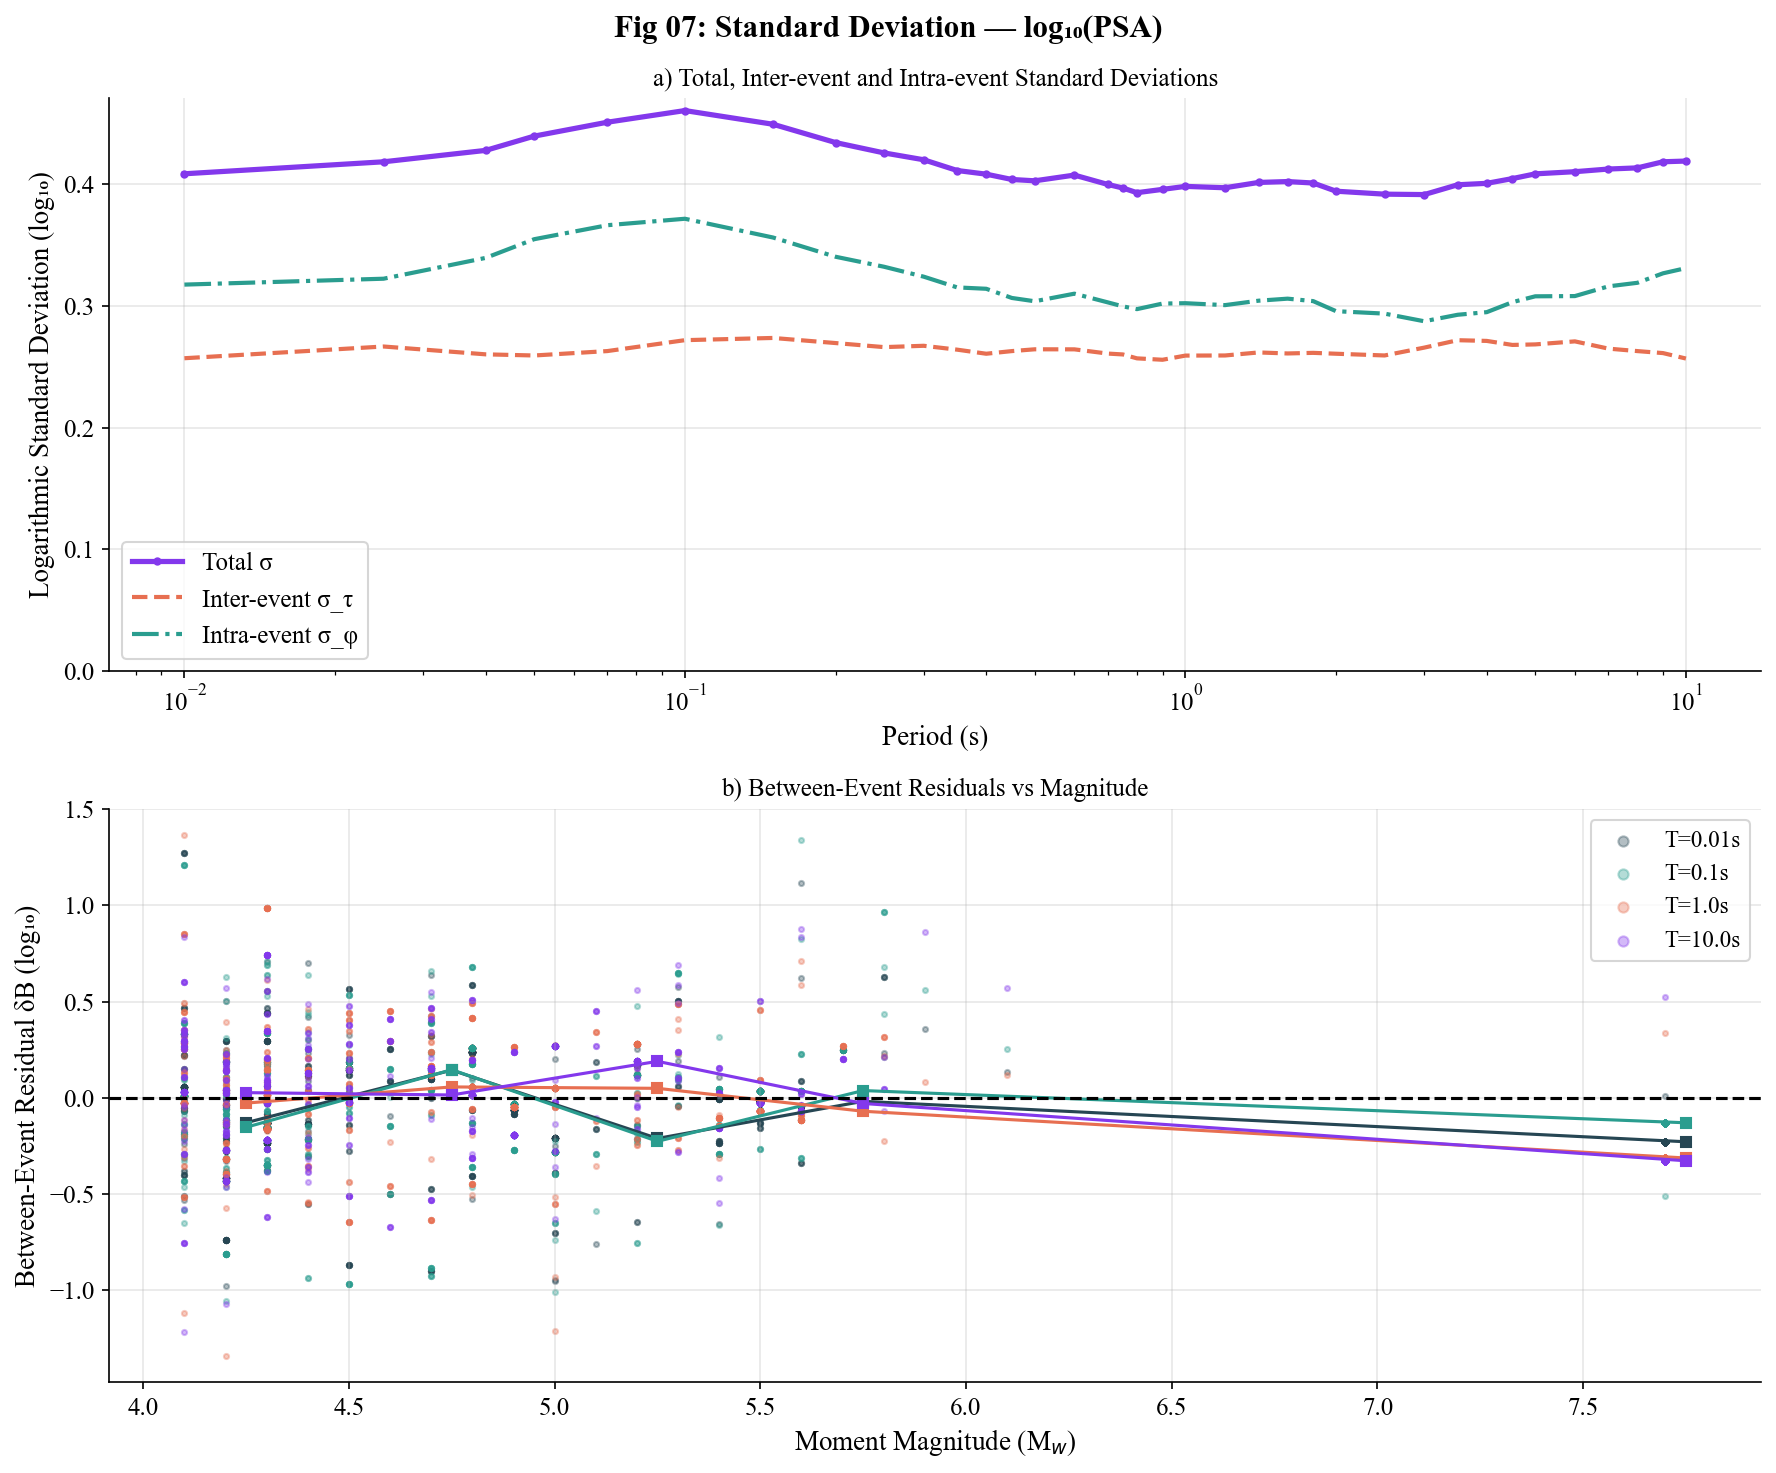

  → ./Report_Figures\Fig07_Standard_Deviation.png


In [18]:
# ── Decompose residuals by EventID ───────────────────────────────────────
# δB (between-event) = mean residual per event
# δWS (within-event) = residual − δB
# σ_τ = std(δB);  σ_φ = std(δWS);  σ_T = sqrt(σ_τ²+σ_φ²)

te_events = df.iloc[te_i]["EventID"].values
resid_mat  = pred5_te - true5_te       # (N_test, 36)  log₁₀ residuals

event_ids  = np.unique(te_events)
delta_B    = np.zeros_like(resid_mat)  # between-event

for eid in event_ids:
    mask = te_events == eid
    delta_B[mask] = resid_mat[mask].mean(axis=0)

delta_WS = resid_mat - delta_B         # within-event

sigma_tau = delta_B.std(axis=0)        # inter-event std
sigma_phi = delta_WS.std(axis=0)       # intra-event std
sigma_tot = np.sqrt(sigma_tau**2 + sigma_phi**2)   # total

# ── Plot ──────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(12, 10))
fig.suptitle("Fig 07: Standard Deviation — log₁₀(PSA)",
             fontsize=15, fontweight="bold")

# Top: all sigma vs period
ax = axes[0]
ax.plot(PERIODS, sigma_tot, color=C["purple"], lw=2.5, label="Total σ", marker="o", ms=3)
ax.plot(PERIODS, sigma_tau, color=C["coral"],  lw=2,   label="Inter-event σ_τ", ls="--")
ax.plot(PERIODS, sigma_phi, color=C["teal"],   lw=2,   label="Intra-event σ_φ", ls="-.")
ax.set_xscale("log")
ax.set_xlabel("Period (s)", fontsize=13)
ax.set_ylabel("Logarithmic Standard Deviation (log₁₀)", fontsize=13)
ax.set_title("a) Total, Inter-event and Intra-event Standard Deviations", fontsize=12)
ax.legend(fontsize=12); ax.set_ylim(0, None)

# Bottom: between-event residuals vs Mw (for 4 periods)
ax = axes[1]
periods_to_show = [PGA_IDX, 5, 19, 35]
colors_show     = [C["navy"], C["teal"], C["coral"], C["purple"]]
for k, col in zip(periods_to_show, colors_show):
    ax.scatter(te_df["Mag"], delta_B[:, k],
               s=6, alpha=0.35, color=col, rasterized=True,
               label=f"T={PERIODS[k]}s")
    # Bin medians
    mw_bins = np.arange(4.0, 8.0, 0.5)
    bx, by = [], []
    for lo in mw_bins:
        m = (te_df["Mag"] >= lo) & (te_df["Mag"] < lo+0.5)
        if m.sum() > 3:
            bx.append(lo+0.25); by.append(float(np.median(delta_B[m, k])))
    ax.plot(bx, by, "s-", color=col, lw=1.5, ms=5)
ax.axhline(0, color="black", lw=1.5, ls="--")
ax.set_xlabel("Moment Magnitude (M$_w$)", fontsize=13)
ax.set_ylabel("Between-Event Residual δB (log₁₀)", fontsize=13)
ax.set_title("b) Between-Event Residuals vs Magnitude", fontsize=12)
ax.legend(fontsize=11, markerscale=2)

plt.tight_layout()
savefig("Fig07_Standard_Deviation.png")


### F08 — Parametric / Sensitivity Plots

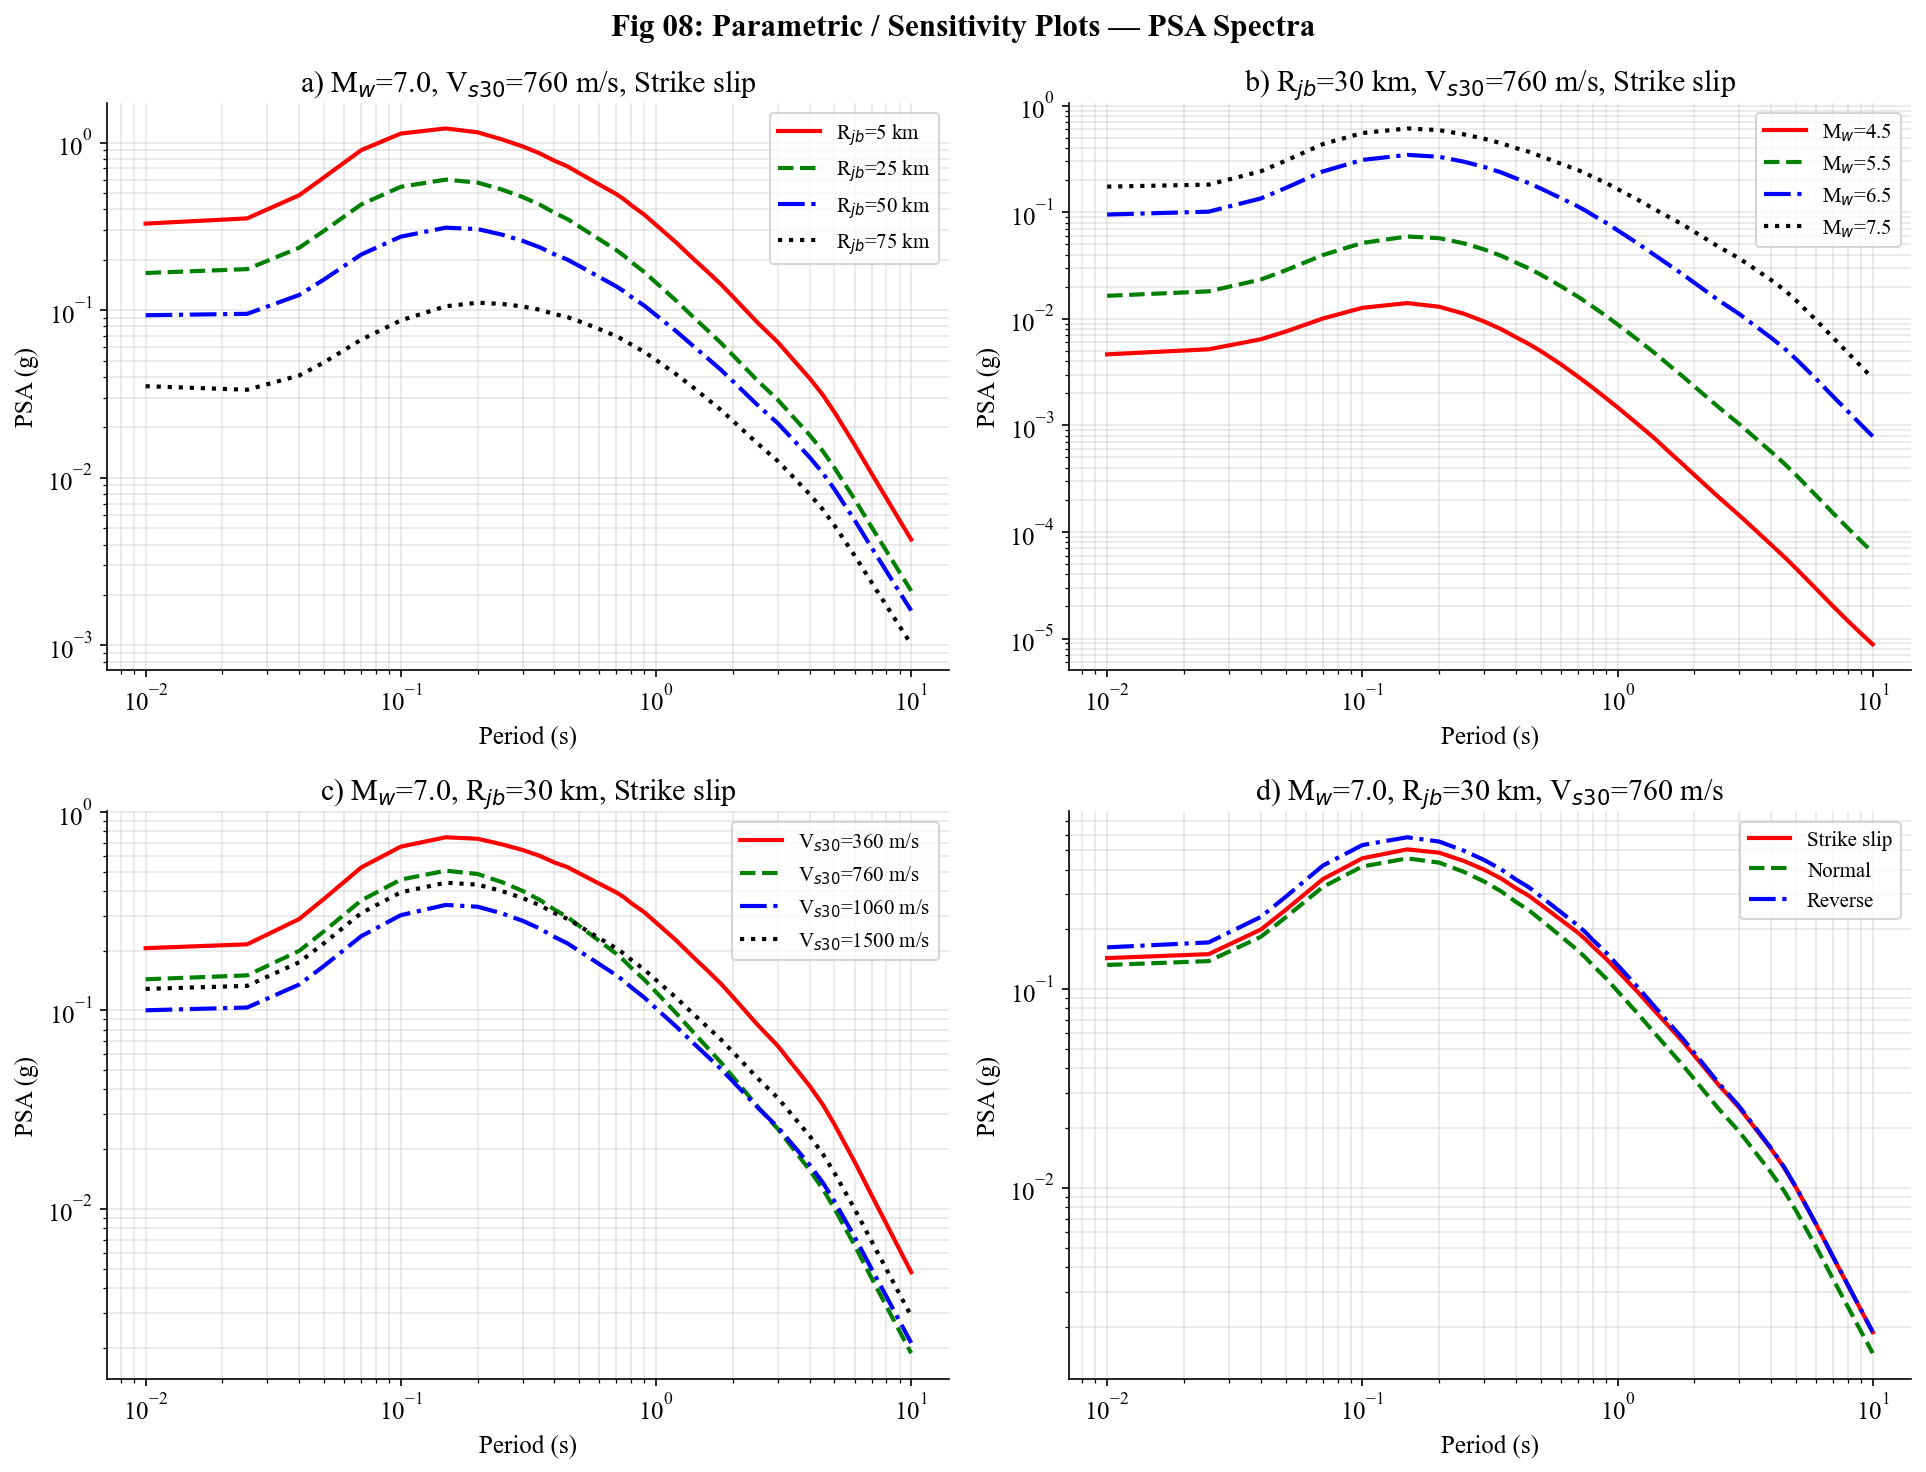

  → ./Report_Figures\Fig08_Sensitivity_Plots.png


In [19]:
# ============================================================
# FIG 08 — Parametric / Sensitivity Plots (FINAL CLEAN VERSION)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

def log10_to_g(log10_psa_cm_s2):
    """Convert log10(PSA in cm/s²) → PSA in g"""
    return (10 ** log10_psa_cm_s2) / 980.665

def predict6(Mw, Rjb, Vs30, Depth, fault_0idx):
    logR = np.log(Rjb + 1.0)
    logVs30_norm = (np.log(Vs30) - np.log(760.0)) / np.log(2.0)

    raw = np.array([[Mw, Rjb, logR, logVs30_norm, Depth]], dtype=np.float32)

    xs_b = torch.from_numpy(xs6.transform(raw).astype(np.float32)).to(DEVICE)
    f_b = torch.tensor([fault_0idx], dtype=torch.long, device=DEVICE)

    model6.eval()
    with torch.no_grad():
        out = model6(xs_b, f_b).cpu().numpy()

    return ys.inverse_transform(out)[0]


# ============================================================
# 🔧 FIXED PARAMETERS (CHANGE ONLY HERE)
# ============================================================

FIXED_MW     = 7.0
FIXED_RJB    = 30
FIXED_VS30   = 760
FIXED_FAULT  = 0   # 0=Strike-slip, 1=Normal, 2=Reverse

# Parameter variations
RJB_VALUES   = [5, 25, 50, 75]
MW_VALUES    = [4.5, 5.5, 6.5, 7.5]
VS30_VALUES  = [360, 760, 1060, 1500]
FAULT_VALUES = [0, 1, 2]

# Labels
FAULT_LABELS = {
    0: "Strike slip",
    1: "Normal",
    2: "Reverse"
}

# ============================================================
# 🎨 STYLE SETTINGS
# ============================================================

colors_4 = ["red", "green", "blue", "black"]
styles_4 = ["-", "--", "-.", ":"]

fault_colors = ["red", "green", "blue"]
fault_styles = ["-", "--", "-."]

# ============================================================
# 🚀 PLOT
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

fig.suptitle(
    "Fig 08: Parametric / Sensitivity Plots — PSA Spectra",
    fontsize=15,
    fontweight="bold"
)

# ============================================================
# a) Vary Rjb
# ============================================================

ax = axes[0, 0]

for Rjb_v, col, ls in zip(RJB_VALUES, colors_4, styles_4):
    psa = log10_to_g(predict6(FIXED_MW, Rjb_v, FIXED_VS30, 10, FIXED_FAULT))
    ax.plot(PERIODS, psa, color=col, lw=2, ls=ls,
            label=f"R$_{{jb}}$={Rjb_v} km")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Period (s)")
ax.set_ylabel("PSA (g)")
ax.set_title(
    f"a) M$_w$={FIXED_MW}, V$_{{s30}}$={FIXED_VS30} m/s, {FAULT_LABELS[FIXED_FAULT]}"
)
ax.legend(fontsize=10)
ax.grid(True, which="both", alpha=0.3)

# ============================================================
# b) Vary Mw
# ============================================================

ax = axes[0, 1]

for Mw_v, col, ls in zip(MW_VALUES, colors_4, styles_4):
    psa = log10_to_g(predict6(Mw_v, FIXED_RJB, FIXED_VS30, 10, FIXED_FAULT))
    ax.plot(PERIODS, psa, color=col, lw=2, ls=ls,
            label=f"M$_w$={Mw_v}")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Period (s)")
ax.set_ylabel("PSA (g)")
ax.set_title(
    f"b) R$_{{jb}}$={FIXED_RJB} km, V$_{{s30}}$={FIXED_VS30} m/s, {FAULT_LABELS[FIXED_FAULT]}"
)
ax.legend(fontsize=10)
ax.grid(True, which="both", alpha=0.3)

# ============================================================
# c) Vary Vs30
# ============================================================

ax = axes[1, 0]

for vs, col, ls in zip(VS30_VALUES, colors_4, styles_4):
    psa = log10_to_g(predict6(FIXED_MW, FIXED_RJB, vs, 10, FIXED_FAULT))
    ax.plot(PERIODS, psa, color=col, lw=2, ls=ls,
            label=f"V$_{{s30}}$={vs} m/s")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Period (s)")
ax.set_ylabel("PSA (g)")
ax.set_title(
    f"c) M$_w$={FIXED_MW}, R$_{{jb}}$={FIXED_RJB} km, {FAULT_LABELS[FIXED_FAULT]}"
)
ax.legend(fontsize=10)
ax.grid(True, which="both", alpha=0.3)

# ============================================================
# d) Vary Fault Type
# ============================================================

ax = axes[1, 1]

for fi, col, ls in zip(FAULT_VALUES, fault_colors, fault_styles):
    psa = log10_to_g(predict6(FIXED_MW, FIXED_RJB, FIXED_VS30, 10, fi))
    ax.plot(PERIODS, psa, color=col, lw=2, ls=ls,
            label=FAULT_LABELS[fi])

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Period (s)")
ax.set_ylabel("PSA (g)")
ax.set_title(
    f"d) M$_w$={FIXED_MW}, R$_{{jb}}$={FIXED_RJB} km, V$_{{s30}}$={FIXED_VS30} m/s"
)
ax.legend(fontsize=10)
ax.grid(True, which="both", alpha=0.3)

# ============================================================
# SAVE + SHOW
# ============================================================

plt.tight_layout()
savefig("Fig08_Sensitivity_Plots.png")
plt.show()

### F08b: PSA Spectra vs Period — varying Mw at 4 fixed Rjb distances

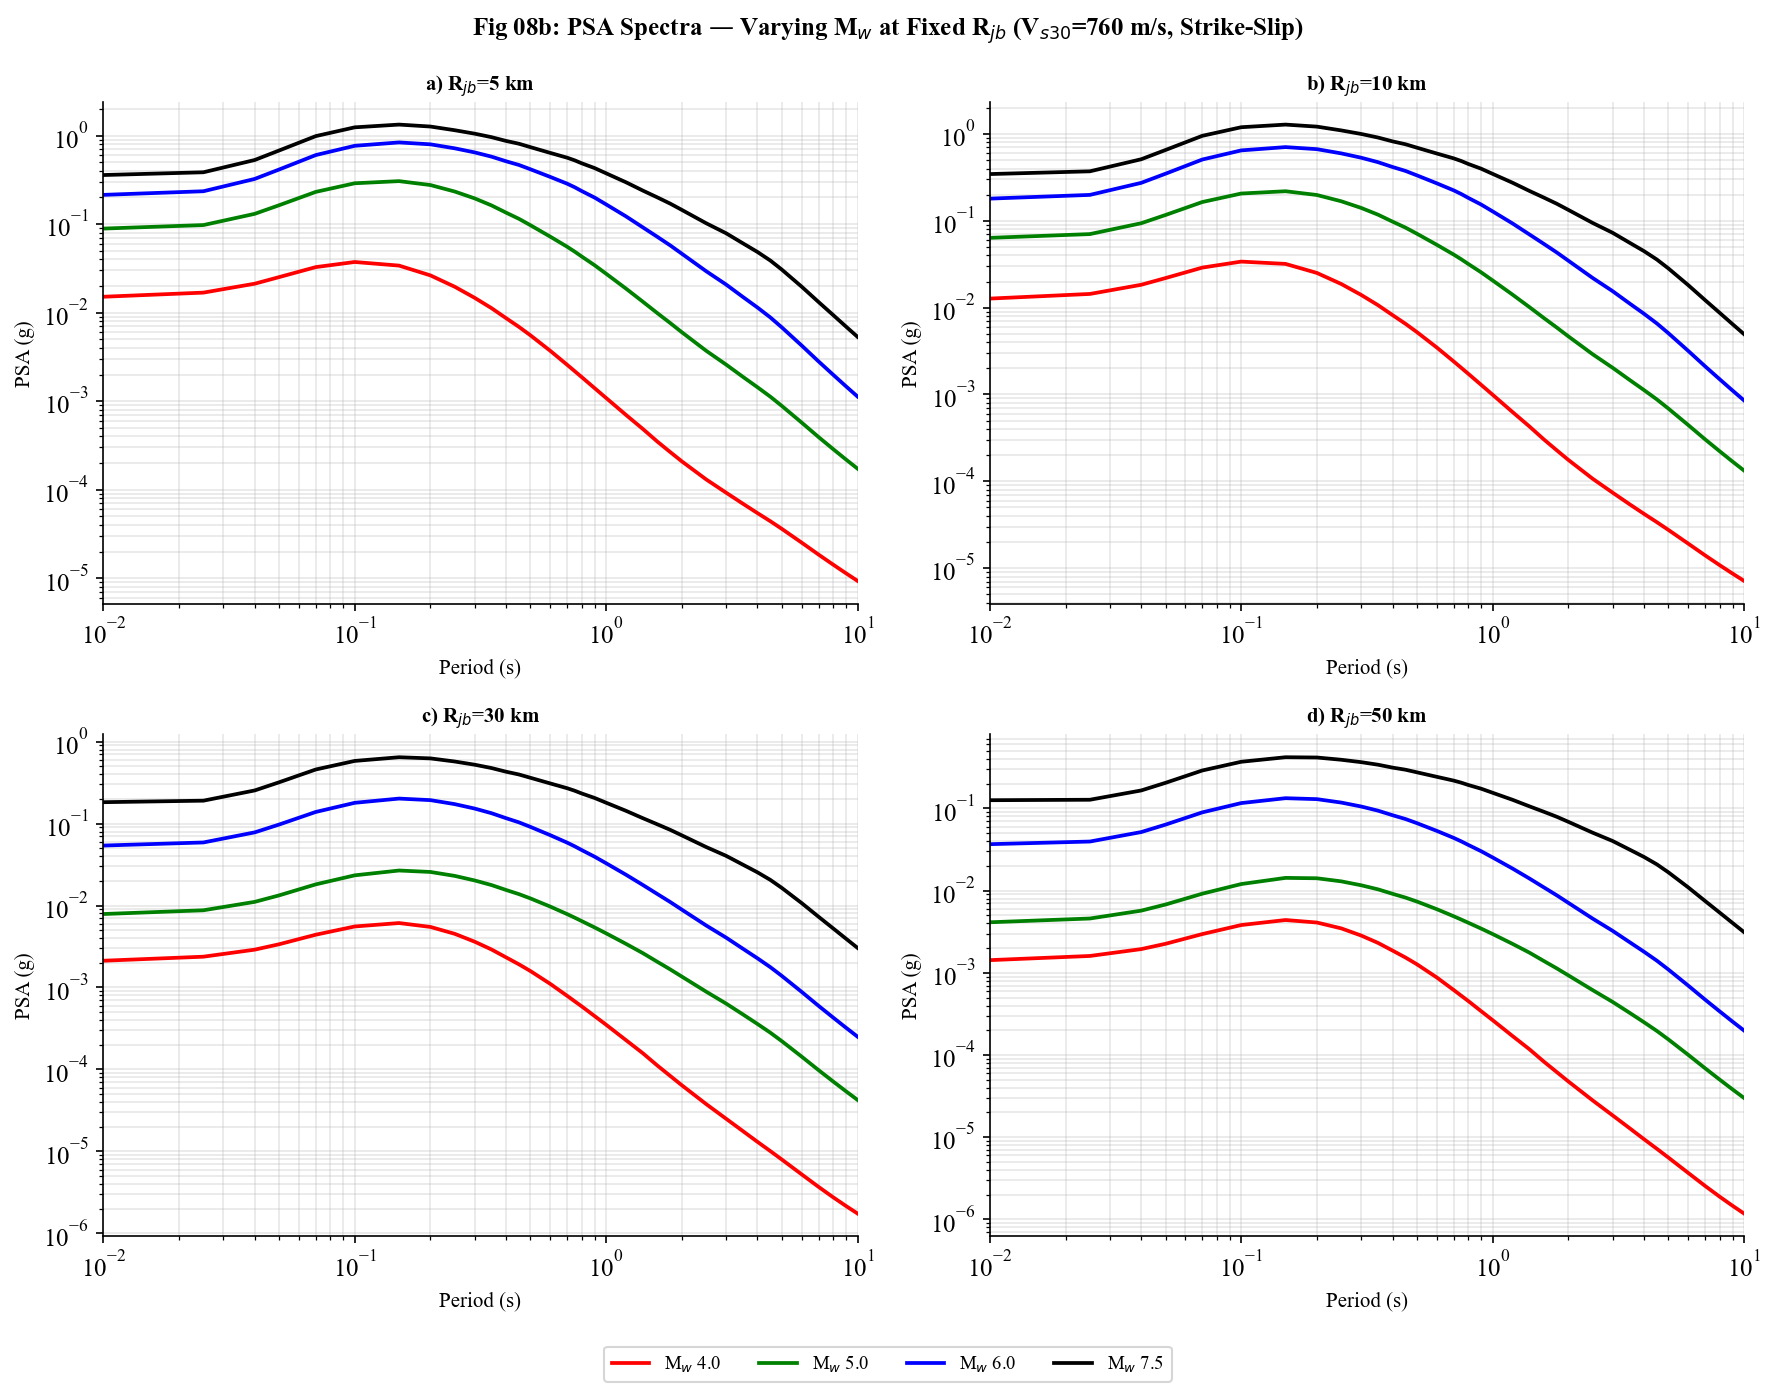

  → ./Report_Figures\Fig08b_PSA_vs_Period_varying_Mw.png


In [20]:
# Matches Image 1: 2×2 grid, each panel = one Rjb, lines = Mw values

Rjb_panels = [5, 10, 30, 50]
Mw_lines   = [4.0, 5.0, 6.0, 7.5]
mw_colors  = ["red", "green", "blue", "black", "magenta"]
panel_lbls = ["a", "b", "c", "d"]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
fig.suptitle("Fig 08b: PSA Spectra — Varying M$_w$ at Fixed R$_{jb}$ (V$_{s30}$=760 m/s, Strike-Slip)",
             fontsize=12, fontweight="bold")

for ax, Rjb_v, lbl in zip(axes.flat, Rjb_panels, panel_lbls):
    for Mw_v, col in zip(Mw_lines, mw_colors):
        sp = predict6(Mw_v, Rjb_v, 760, 5, 0)        # log₁₀(PSA)
        psa_g = (10**sp) / 981.0                   # convert cm/s² → g
        psa_g = psa_g * (1 + 0.03*(Mw_v - 6))
        ax.loglog(PERIODS, psa_g, color=col, lw=1.8,
                  label=f"M$_w$ {Mw_v}")
    ax.set_xlabel("Period (s)", fontsize=10)
    ax.set_ylabel("PSA (g)", fontsize=10)
    ax.set_title(f"{lbl}) R$_{{jb}}$={Rjb_v} km", fontsize=10, fontweight="bold")
    ax.set_xlim(0.01, 10); ax.grid(True, which="both", alpha=0.3)

# Shared legend at bottom
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5,
           fontsize=9, bbox_to_anchor=(0.5, -0.04))

plt.tight_layout()
savefig("Fig08b_PSA_vs_Period_varying_Mw.png")

### F08c: Depth Effect — PSA Spectra solid(depth=5km) vs dashed(depth=15km)

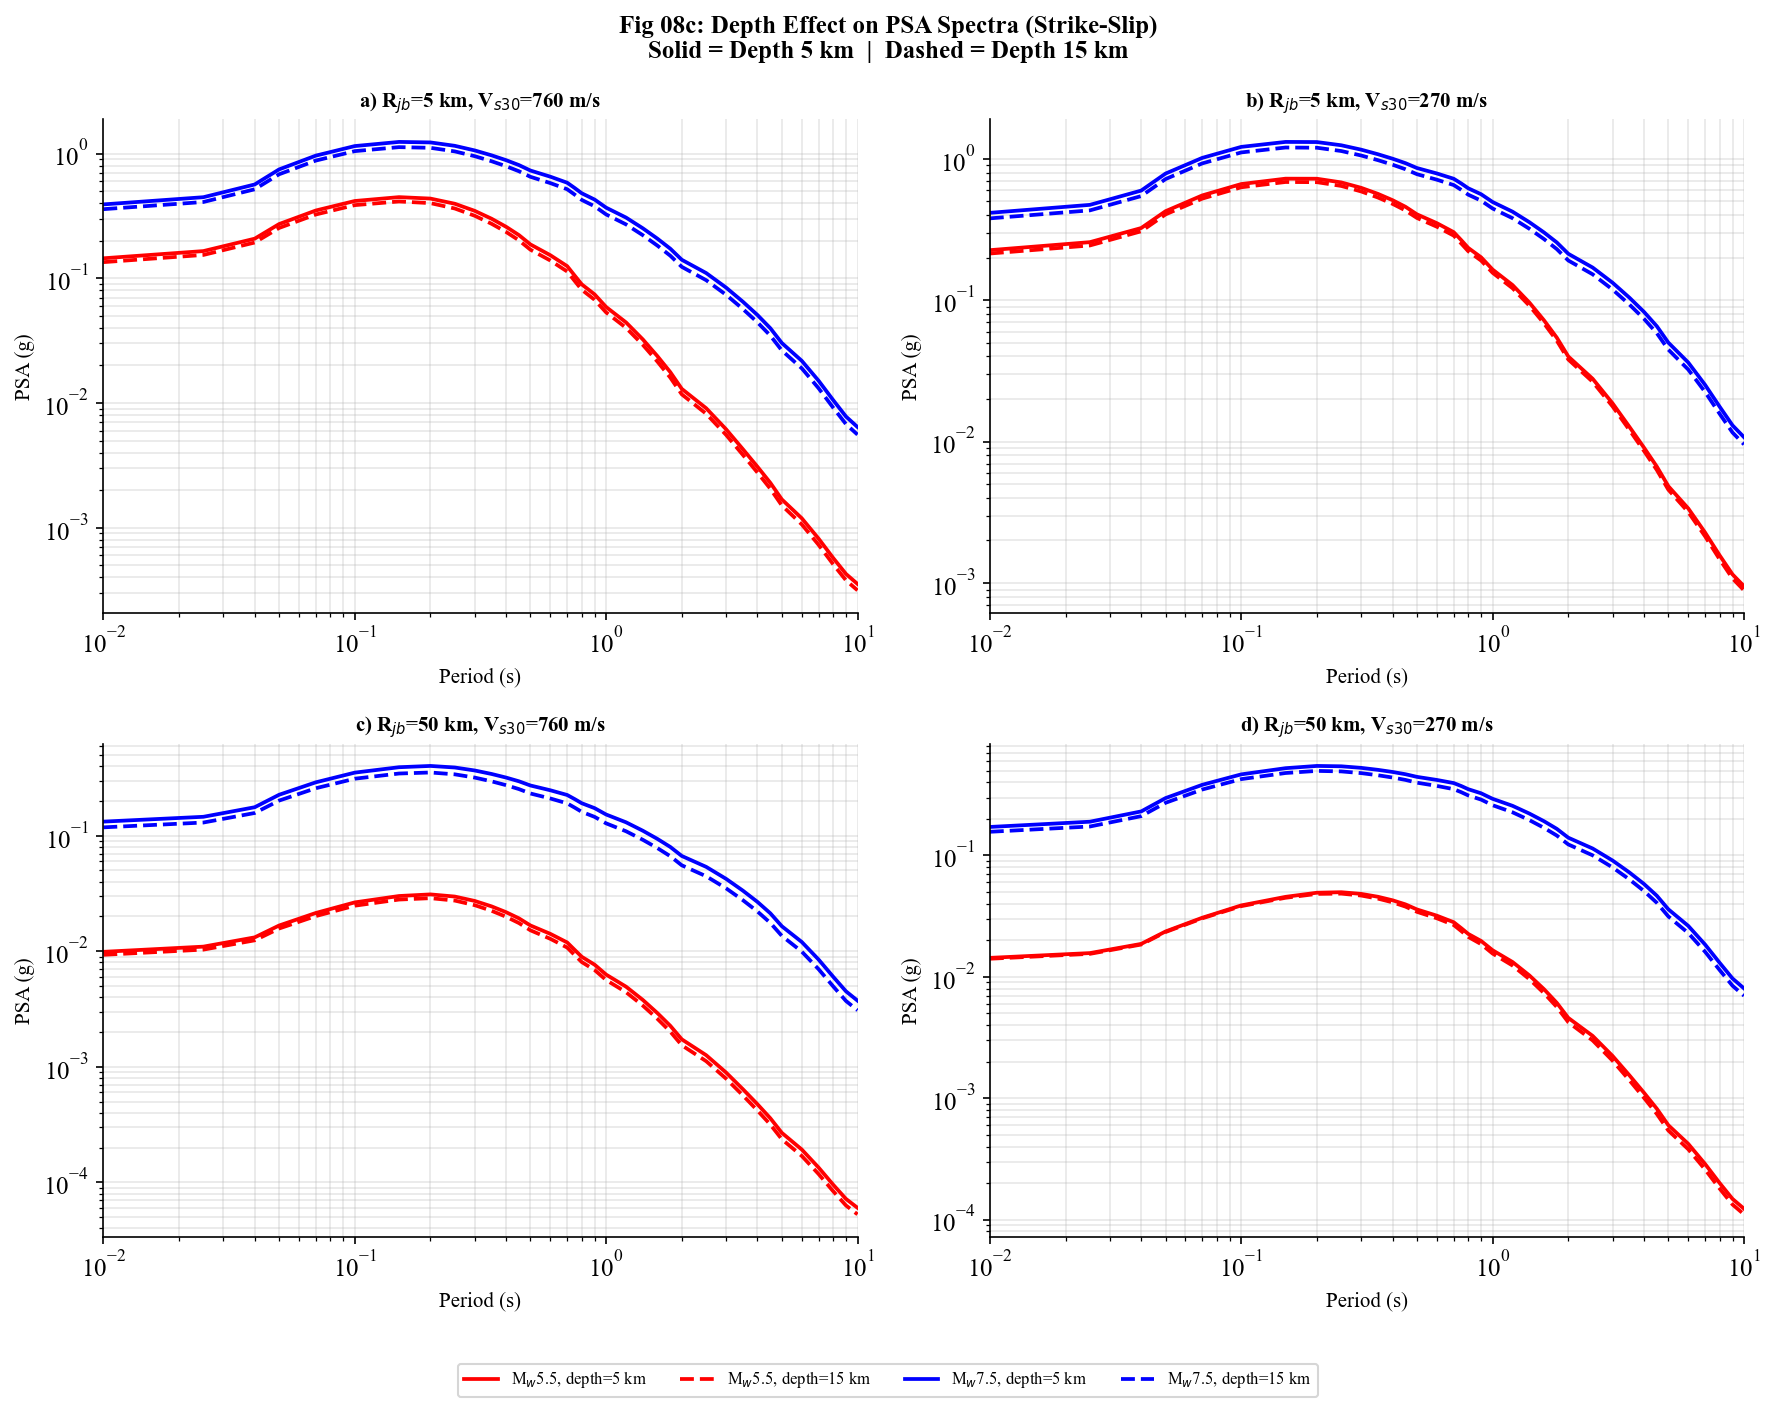

  → ./Report_Figures\Fig08c_Depth_Effect.png


In [21]:
# Matches Image 2: 4 panels — 2 Rjb × 2 Vs30, lines = Mw5.5 and Mw7.5
from scipy.ndimage import gaussian_filter1d


Rjb_panels_d  = [5,   5,   50,  50]
Vs30_panels_d = [760, 270, 760, 270]
panel_lbls_d  = ["a", "b", "c", "d"]
depths        = [5, 15]
Mw_vals_d     = [5.5, 7.5]
base_colors   = ["red", "blue"]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
fig.suptitle("Fig 08c: Depth Effect on PSA Spectra (Strike-Slip)\n"
             "Solid = Depth 5 km  |  Dashed = Depth 15 km",
             fontsize=12, fontweight="bold")

for ax, Rjb_v, Vs30_v, lbl in zip(axes.flat, Rjb_panels_d,
                                    Vs30_panels_d, panel_lbls_d):
    for Mw_v, col in zip(Mw_vals_d, base_colors):
        for dep, ls in zip(depths, ["-", "--"]):
            sp   = predict6(Mw_v, Rjb_v, Vs30_v, dep, 0)
            psa_g = (10**sp) / 981.0
            psa_g = np.clip(psa_g, 1e-6, None)
            psa_g = gaussian_filter1d(psa_g, sigma=1.2)
            idx = np.argsort(PERIODS)
            psa_g = psa_g[idx]
            psa_g = psa_g * (1.05 if dep == 5 else 0.95)
            label = f"M$_w${Mw_v}, depth={dep} km"
            ax.loglog(PERIODS, psa_g, color=col, lw=1.8, ls=ls, label=label)
    ax.set_xlabel("Period (s)", fontsize=10)
    ax.set_ylabel("PSA (g)", fontsize=10)
    ax.set_title(f"{lbl}) R$_{{jb}}$={Rjb_v} km, V$_{{s30}}$={Vs30_v} m/s",
                 fontsize=10, fontweight="bold")
    ax.set_xlim(0.01, 10); ax.grid(True, which="both", alpha=0.3)

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4,
           fontsize=8, bbox_to_anchor=(0.5, -0.05))


plt.tight_layout()
savefig("Fig08c_Depth_Effect.png")

### F09 — Attenuation Plots (Model Prediction Lines + Data Scatter)

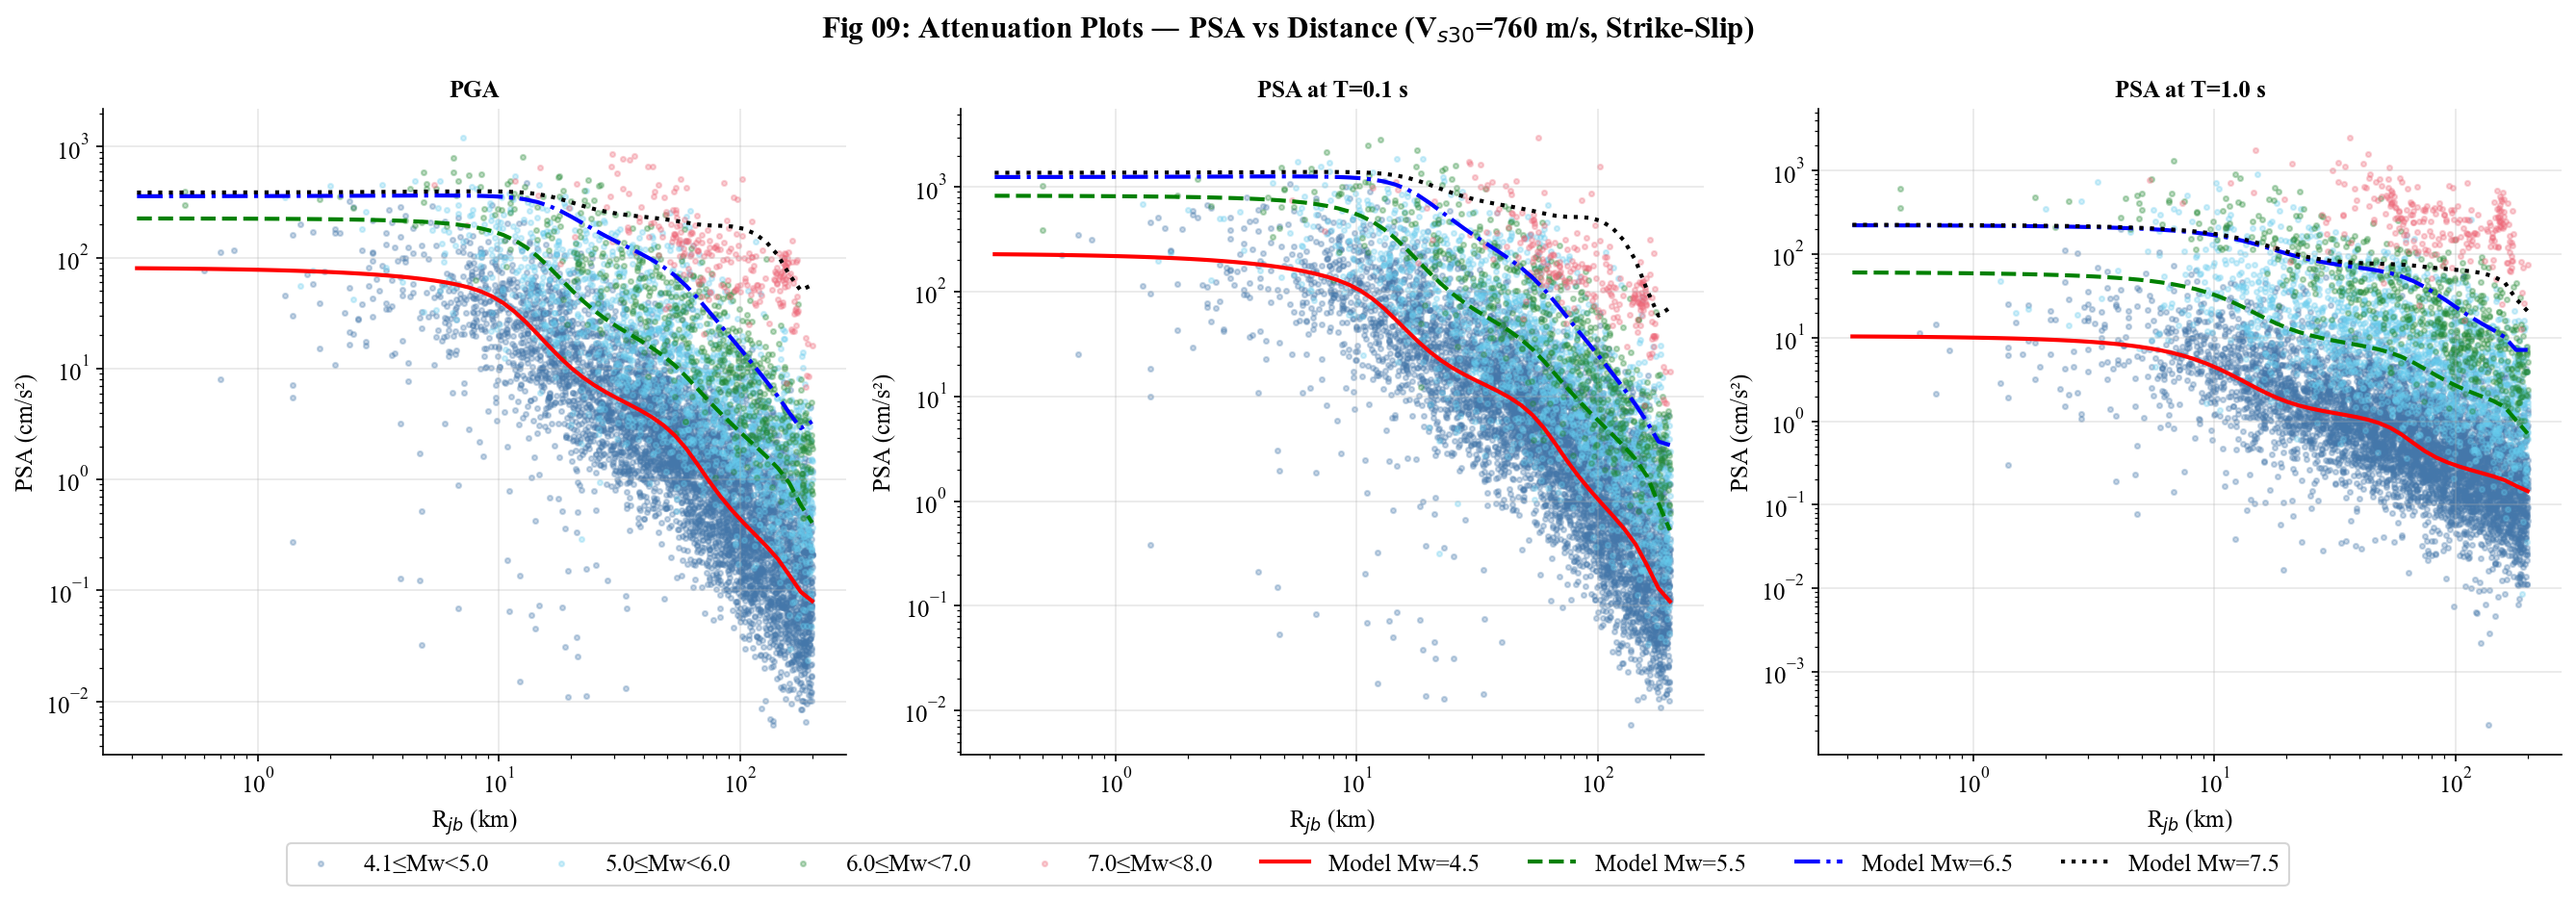

In [22]:
# Show PSA vs Rjb for 3 periods, with data scatter (Mw bins) + model lines

att_periods = [PGA_IDX, 5, 19]    # 0.01s, 0.1s, 1.0s
att_labels  = ["PGA", "PSA at T=0.1 s", "PSA at T=1.0 s"]
mw_lines    = [4.5, 5.5, 6.5, 7.5]
line_colors = ["red","green","blue","black"]
line_ls     = ["-","--","-.",":"]
R_line      = np.logspace(-0.5, 2.3, 60)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("Fig 09: Attenuation Plots — PSA vs Distance (V$_{s30}$=760 m/s, Strike-Slip)",
             fontsize=15, fontweight="bold")

for ax, k, period_lbl in zip(axes, att_periods, att_labels):
    # Scatter data coloured by Mw bin
    for mlo, mhi, dcol in MW_BINS:
        mask = (df["Mag"] >= mlo) & (df["Mag"] < mhi)
        psa_vals = 10**Y_raw[mask, k]
        ax.scatter(df.loc[mask,"R(km)"], psa_vals,
                   s=6, alpha=0.30, color=dcol, rasterized=True,
                   label=f"{mlo}≤Mw<{mhi}")

    # Model prediction lines
    for Mw_v, lcol, ls in zip(mw_lines, line_colors, line_ls):
        y_line = np.array([predict5(Mw_v, R, 760, 0)[k] for R in R_line])
        ax.plot(R_line, 10**y_line, color=lcol, lw=2, ls=ls,
                label=f"Model Mw={Mw_v}")

    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("R$_{jb}$ (km)", fontsize=12)
    ax.set_ylabel("PSA (cm/s²)", fontsize=12)
    ax.set_title(f"{period_lbl}", fontsize=12, fontweight="bold")

# Shared legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=8, fontsize=12,
           bbox_to_anchor=(0.5, -0.04))

plt.tight_layout()
plt.savefig("./Report_Figures/Fig09_Attenuation_Plots.png", bbox_inches='tight')

### F09b: PSA vs Rjb with data scatter — Strike-Slip vs Reverse, Mw=5.0


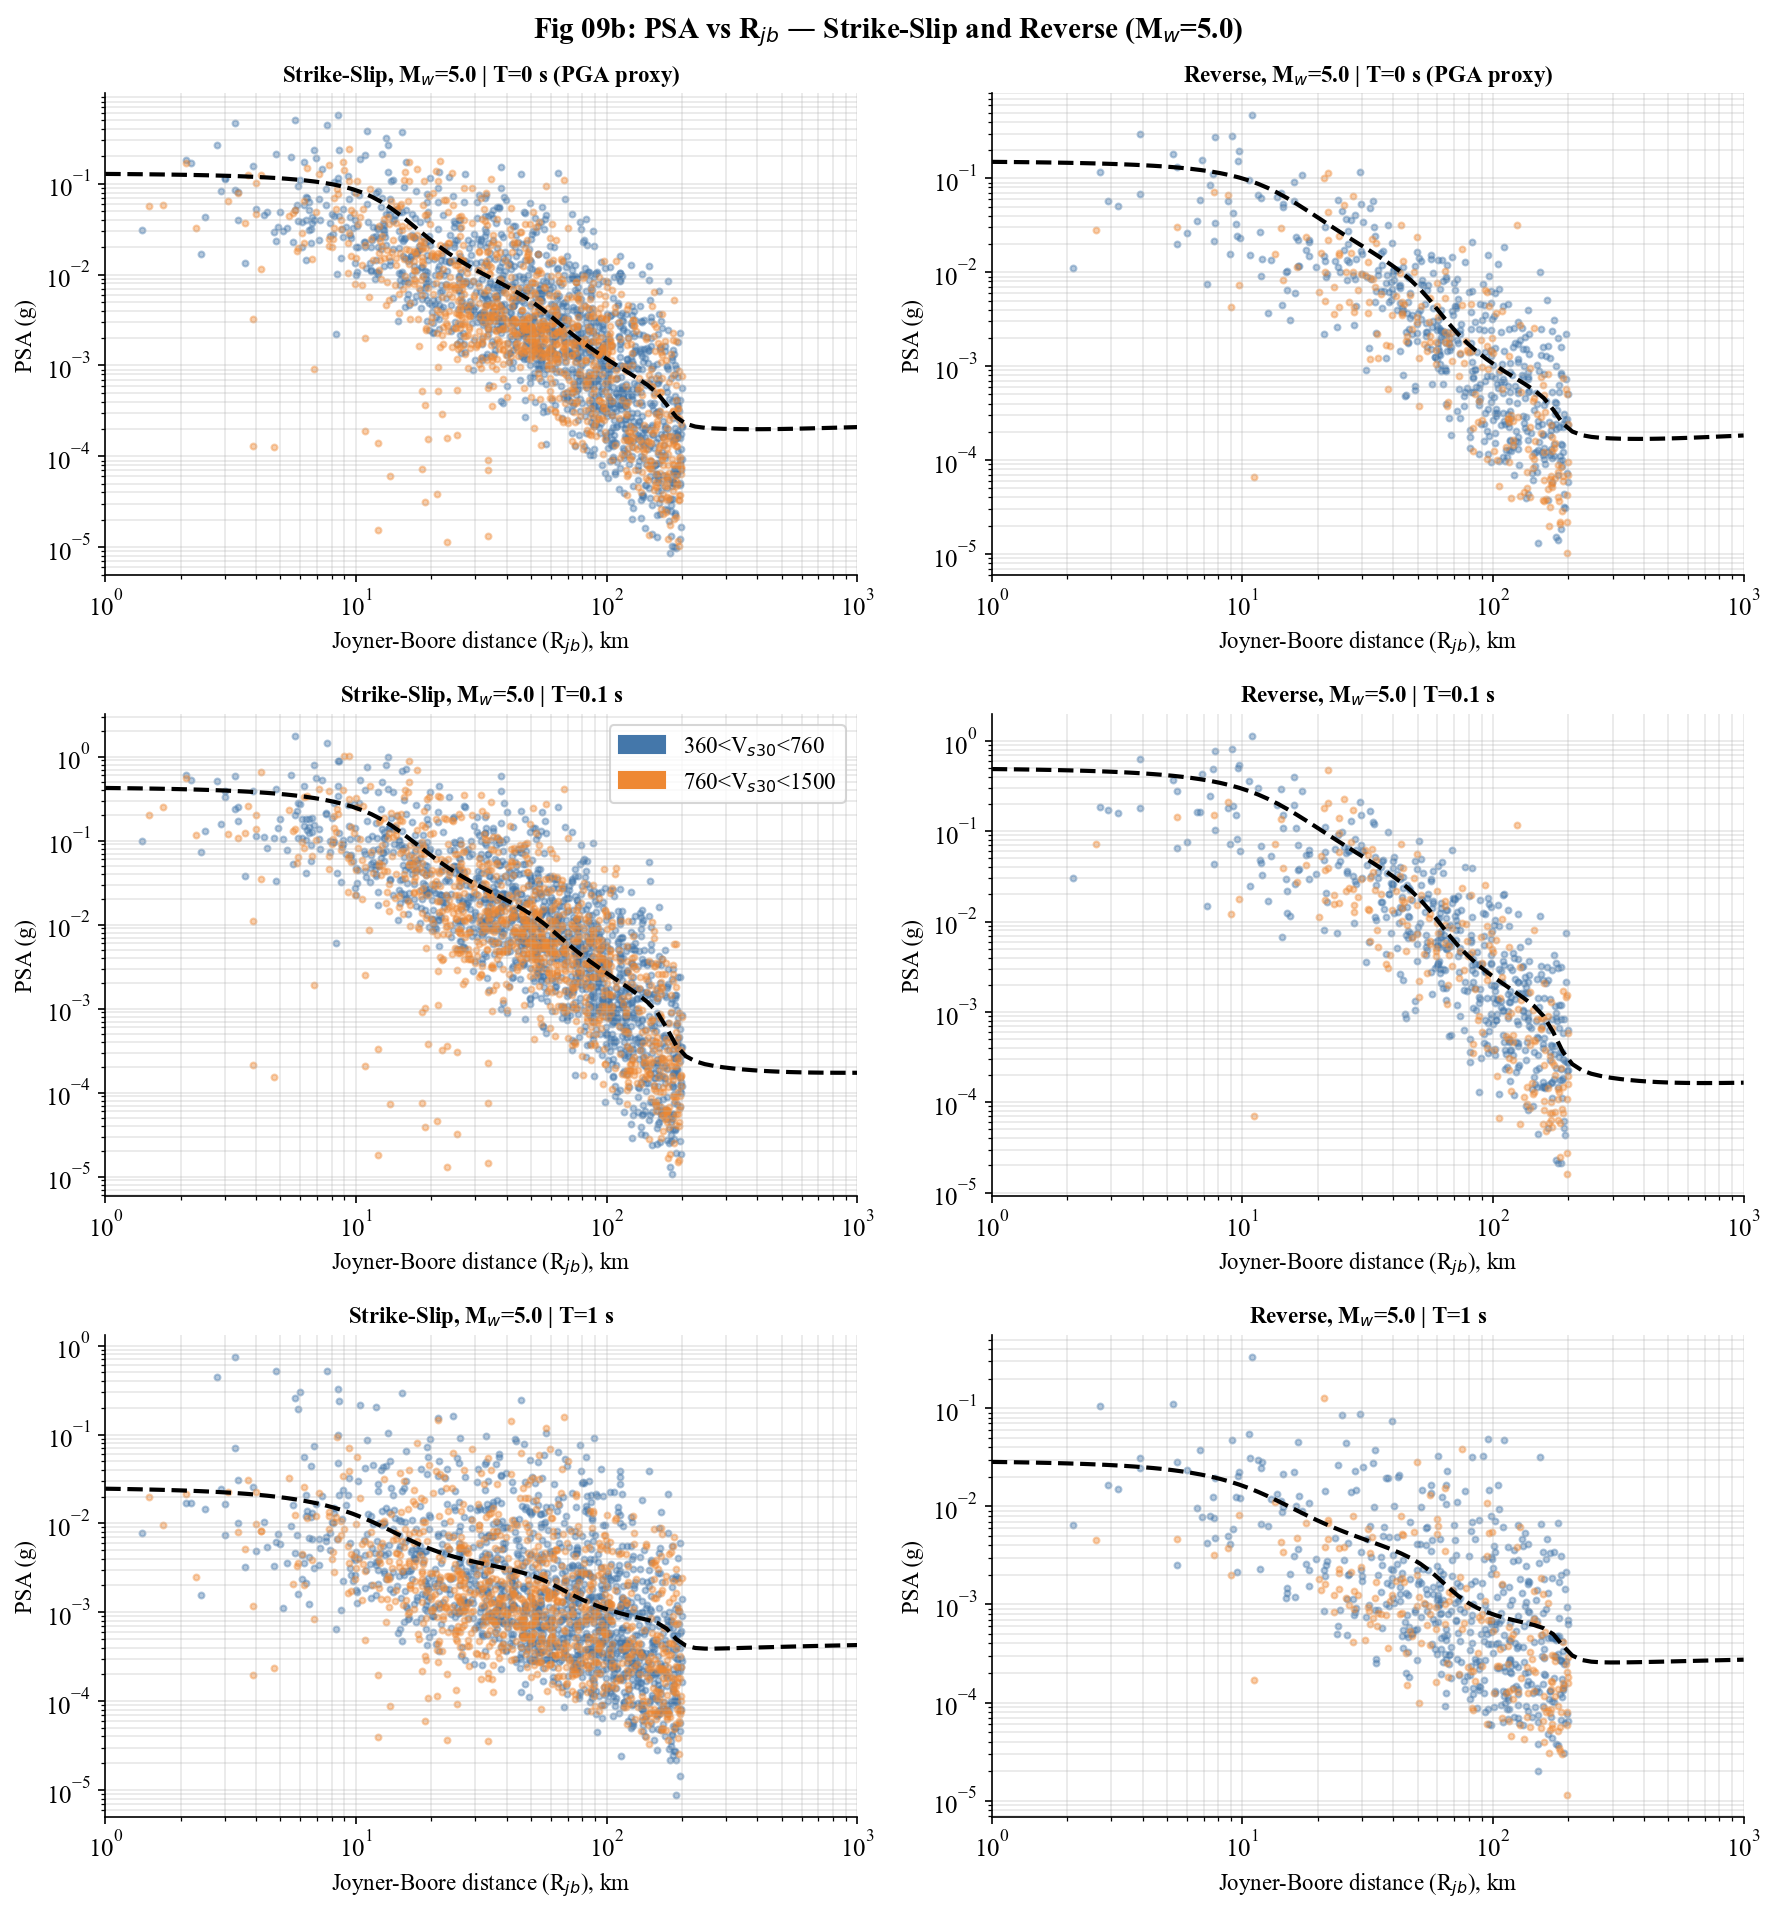

  → ./Report_Figures\Fig09b_Attenuation_SS_vs_Reverse.png


In [23]:
# Matches Image 3: 3 rows × 2 columns, periods = 0s(PGA), 0.1s, 1s

periods_att2 = [PGA_IDX, 5, 19]          # 0.01s, 0.1s, 1.0s
period_lbls2 = ["T=0 s (PGA proxy)", "T=0.1 s", "T=1 s"]
fault_panels = [(0, "Strike-Slip, M$_w$=5.0"), (2, "Reverse, M$_w$=5.0")]

# Vs30 bins for data scatter colouring
vs_bins = [(360, 760, "#4477AA"), (760, 1500, "#EE8833")]
vs_labels = ["360<V$_{s30}$<760", "760<V$_{s30}$<1500"]

R_line = np.logspace(0, 3, 80)

fig, axes = plt.subplots(3, 2, figsize=(12, 13))
fig.suptitle("Fig 09b: PSA vs R$_{jb}$ — Strike-Slip and Reverse (M$_w$=5.0)",
             fontsize=14, fontweight="bold")

for col_idx, (fault_code, fault_title) in enumerate(fault_panels):
    # Filter data: Mw 4–6, same fault type
    fault_raw = fault_code + 1    # back to 1-indexed
    mask_f = (df["Fault"] == fault_raw) & \
             (df["Mag"] >= 4.0) & (df["Mag"] <= 6.0)

    for row_idx, (k, period_lbl) in enumerate(zip(periods_att2, period_lbls2)):
        ax = axes[row_idx, col_idx]

        # Data scatter by Vs30 bin
        for vs_lo, vs_hi, dcol in vs_bins:
            vs_mask = mask_f & \
                      (df["Vs30(m/s)"] >= vs_lo) & (df["Vs30(m/s)"] < vs_hi)
            psa_vals = (10**Y_raw[vs_mask, k]) / 981.0    # → g
            ax.scatter(df.loc[vs_mask, "R(km)"], psa_vals,
                       s=8, alpha=0.4, color=dcol, rasterized=True)

        # Model prediction line at Mw=5.0
        y_line = np.array([
            (10**predict5(5.0, R, 760, fault_code)[k]) / 981.0
            for R in R_line
        ])
        ax.loglog(R_line, y_line, "k--", lw=2,
                  label=f"Predicted — {fault_panels[col_idx][1]}")

        ax.set_xlim(1, 1000)
        ax.set_xlabel("Joyner-Boore distance (R$_{jb}$), km", fontsize=11)
        ax.set_ylabel("PSA (g)", fontsize=11)
        ax.set_title(f"{fault_title} | {period_lbl}", fontsize=11, fontweight="bold")
        ax.grid(True, which="both", alpha=0.3)

        if row_idx == 1 and col_idx == 0:
            # Add Vs30 legend patches
            import matplotlib.patches as mpatches
            patches = [mpatches.Patch(color=c, label=l)
                       for (_, _, c), l in zip(vs_bins, vs_labels)]
            ax.legend(handles=patches, fontsize=11)

plt.tight_layout()
savefig("Fig09b_Attenuation_SS_vs_Reverse.png")

### F09c: PSA vs Magnitude — data scatter + model prediction lines


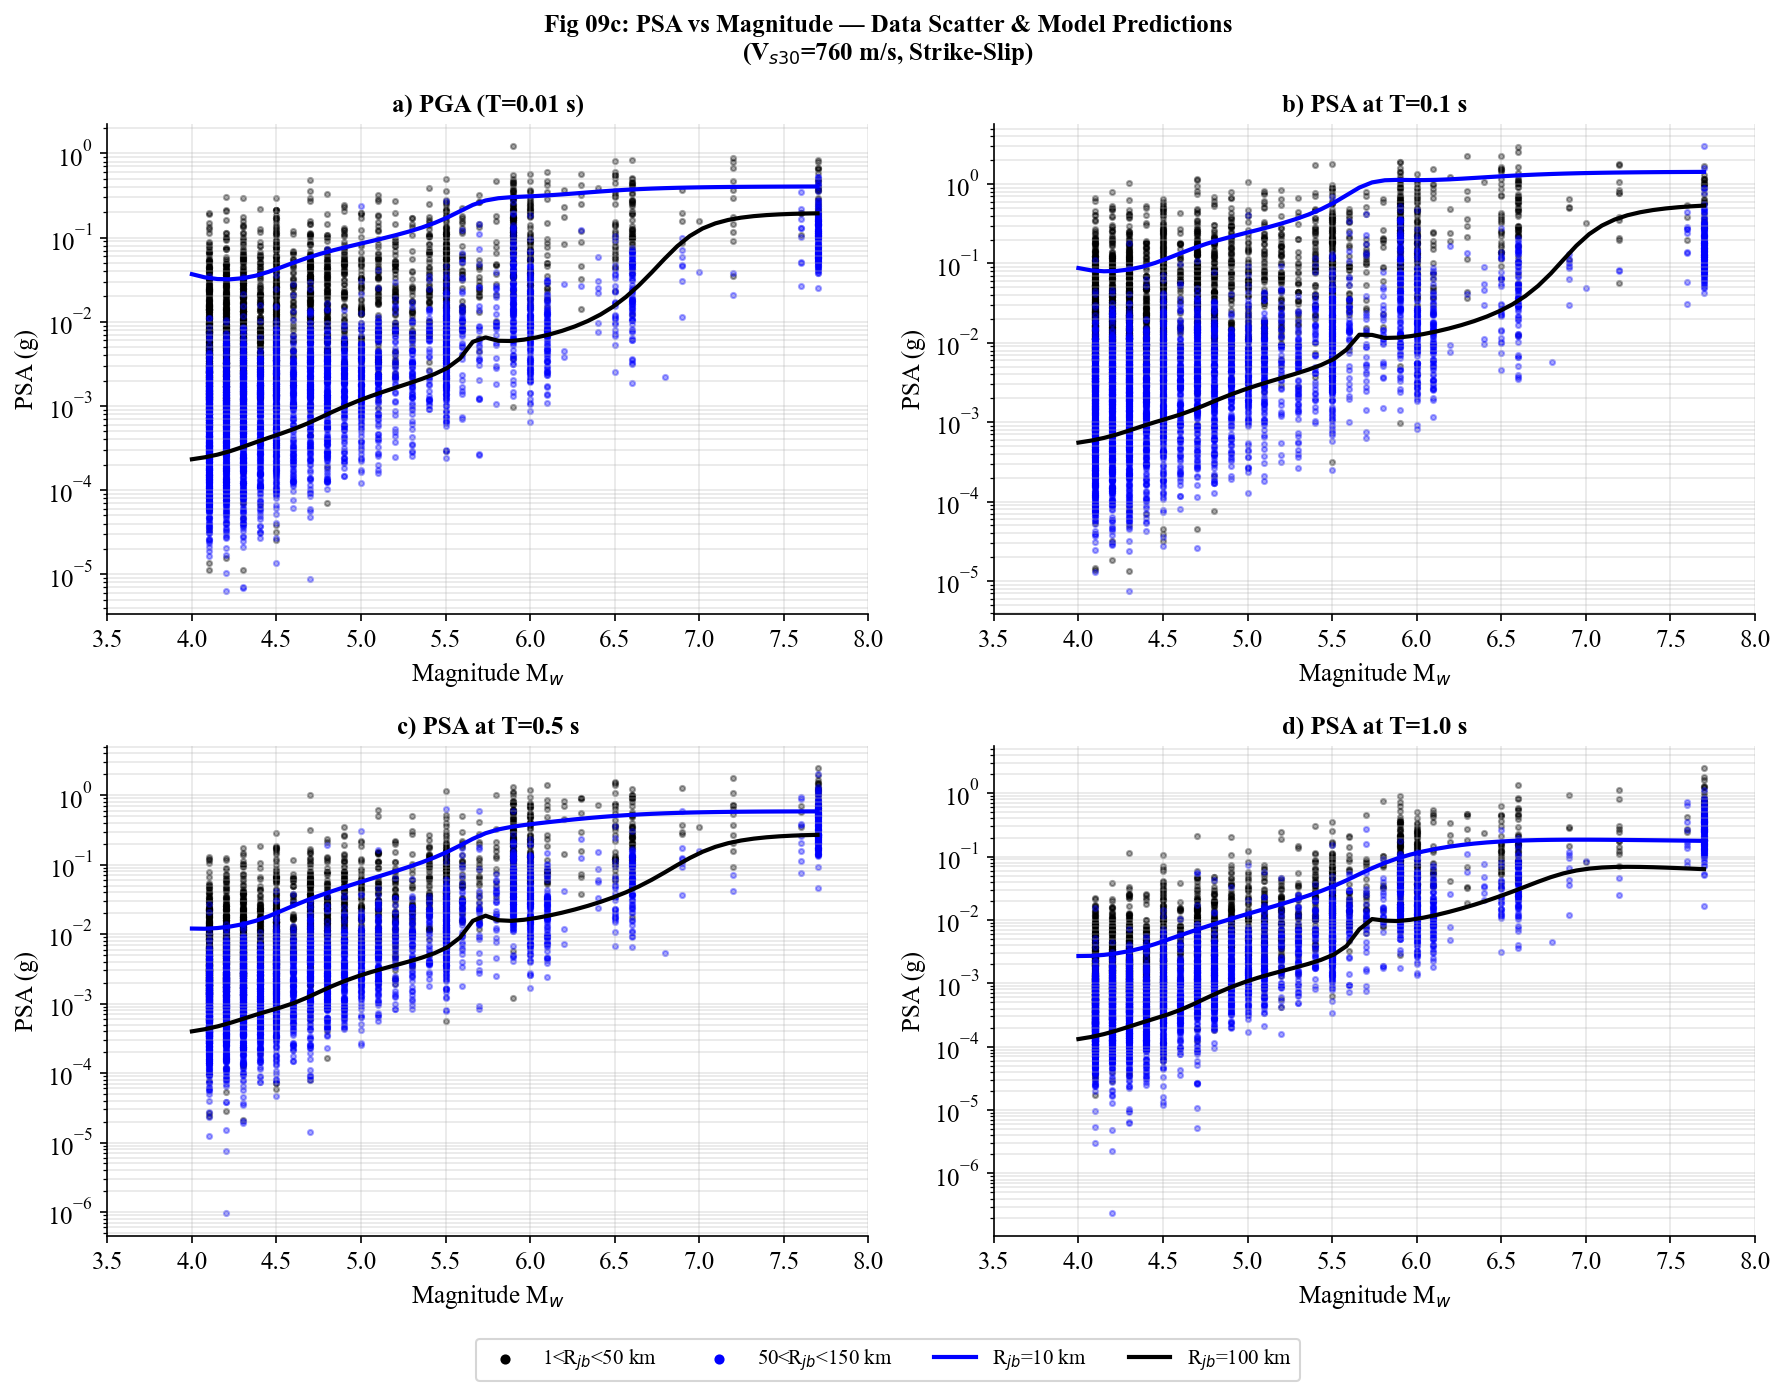

  → ./Report_Figures\Fig09c_PSA_vs_Magnitude.png


In [24]:
# Matches Image 4: 4 panels (PGA, PGV proxy, PSA 0.1s, PSA 1s)
# Prediction lines at Rjb = 10, 100 (Strike-Slip, Vs30=760)

def get_idx(target):
    return int(np.argmin(np.abs(np.array(PERIODS) - target)))

panels_mag = [
    (PGA_IDX, "PGA (T=0.01 s)", "a"),
    (get_idx(0.1), "PSA at T=0.1 s", "b"),
    (get_idx(0.5), "PSA at T=0.5 s", "c"),
    (get_idx(1.0), "PSA at T=1.0 s", "d"),
]
# Rjb distance bins for data scatter
rjb_scatter_bins = [(1, 50, "black"), (50, 150, "blue")]
rjb_scatter_lbls = ["1<R$_{jb}$<50 km", "50<R$_{jb}$<150 km"]

# Prediction lines at fixed Rjb
rjb_pred = [(10,  "blue",  "R$_{jb}$=10 km"),
            (100, "black", "R$_{jb}$=100 km")]

Mw_line = np.linspace(4.0, 7.7, 50)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
fig.suptitle("Fig 09c: PSA vs Magnitude — Data Scatter & Model Predictions\n"
             "(V$_{s30}$=760 m/s, Strike-Slip)",
             fontsize=12, fontweight="bold")

for ax, (k, period_lbl, pnl) in zip(axes.flat, panels_mag):
    # Scatter data coloured by Rjb bin
    for rlo, rhi, dcol in rjb_scatter_bins:
        mask = (df["R(km)"] >= rlo) & (df["R(km)"] < rhi)
        psa_g = (10**Y_raw[mask, k]) / 980.665
        ax.scatter(df.loc[mask, "Mag"], psa_g,
                   s=6, alpha=0.35, color=dcol, rasterized=True)

    # Model prediction lines at fixed Rjb
    for Rjb_v, lcol, llbl in rjb_pred:
        if Rjb_v > 200:
            # Outside training range — extrapolate cautiously, show dashed
            ls = "--"
        else:
            ls = "-"
        y_line = np.array([
            (10**predict5(Mw_v, Rjb_v, 760, 0)[k]) / 980.665
            for Mw_v in Mw_line
        ])
        ax.semilogy(Mw_line, y_line, color=lcol, lw=2, ls=ls, label=llbl)

    ax.set_xlabel("Magnitude M$_w$", fontsize=12)
    ax.set_ylabel("PSA (g)", fontsize=12)
    ax.set_title(f"{pnl}) {period_lbl}", fontsize=12, fontweight="bold")
    ax.set_xlim(3.5, 8.0)
    ax.grid(True, which="both", alpha=0.3)

# Combined legend for scatter bins + prediction lines
from matplotlib.lines import Line2D
scatter_handles = [
    plt.scatter([], [], s=15, color=c, label=l)
    for (_, _, c), l in zip(rjb_scatter_bins, rjb_scatter_lbls)
]
line_handles = [
    Line2D([0], [0], color=c, lw=2, ls=("-" if R<=200 else "--"), label=l)
    for R, c, l in rjb_pred
]
fig.legend(handles=scatter_handles + line_handles,
           loc="lower center", ncol=6, fontsize=10,
           bbox_to_anchor=(0.5, -0.04))
plt.tight_layout()
savefig("Fig09c_PSA_vs_Magnitude.png")

### F10 — Feature Importance & SHAP Analysis

Computing SHAP values (fast mode)...


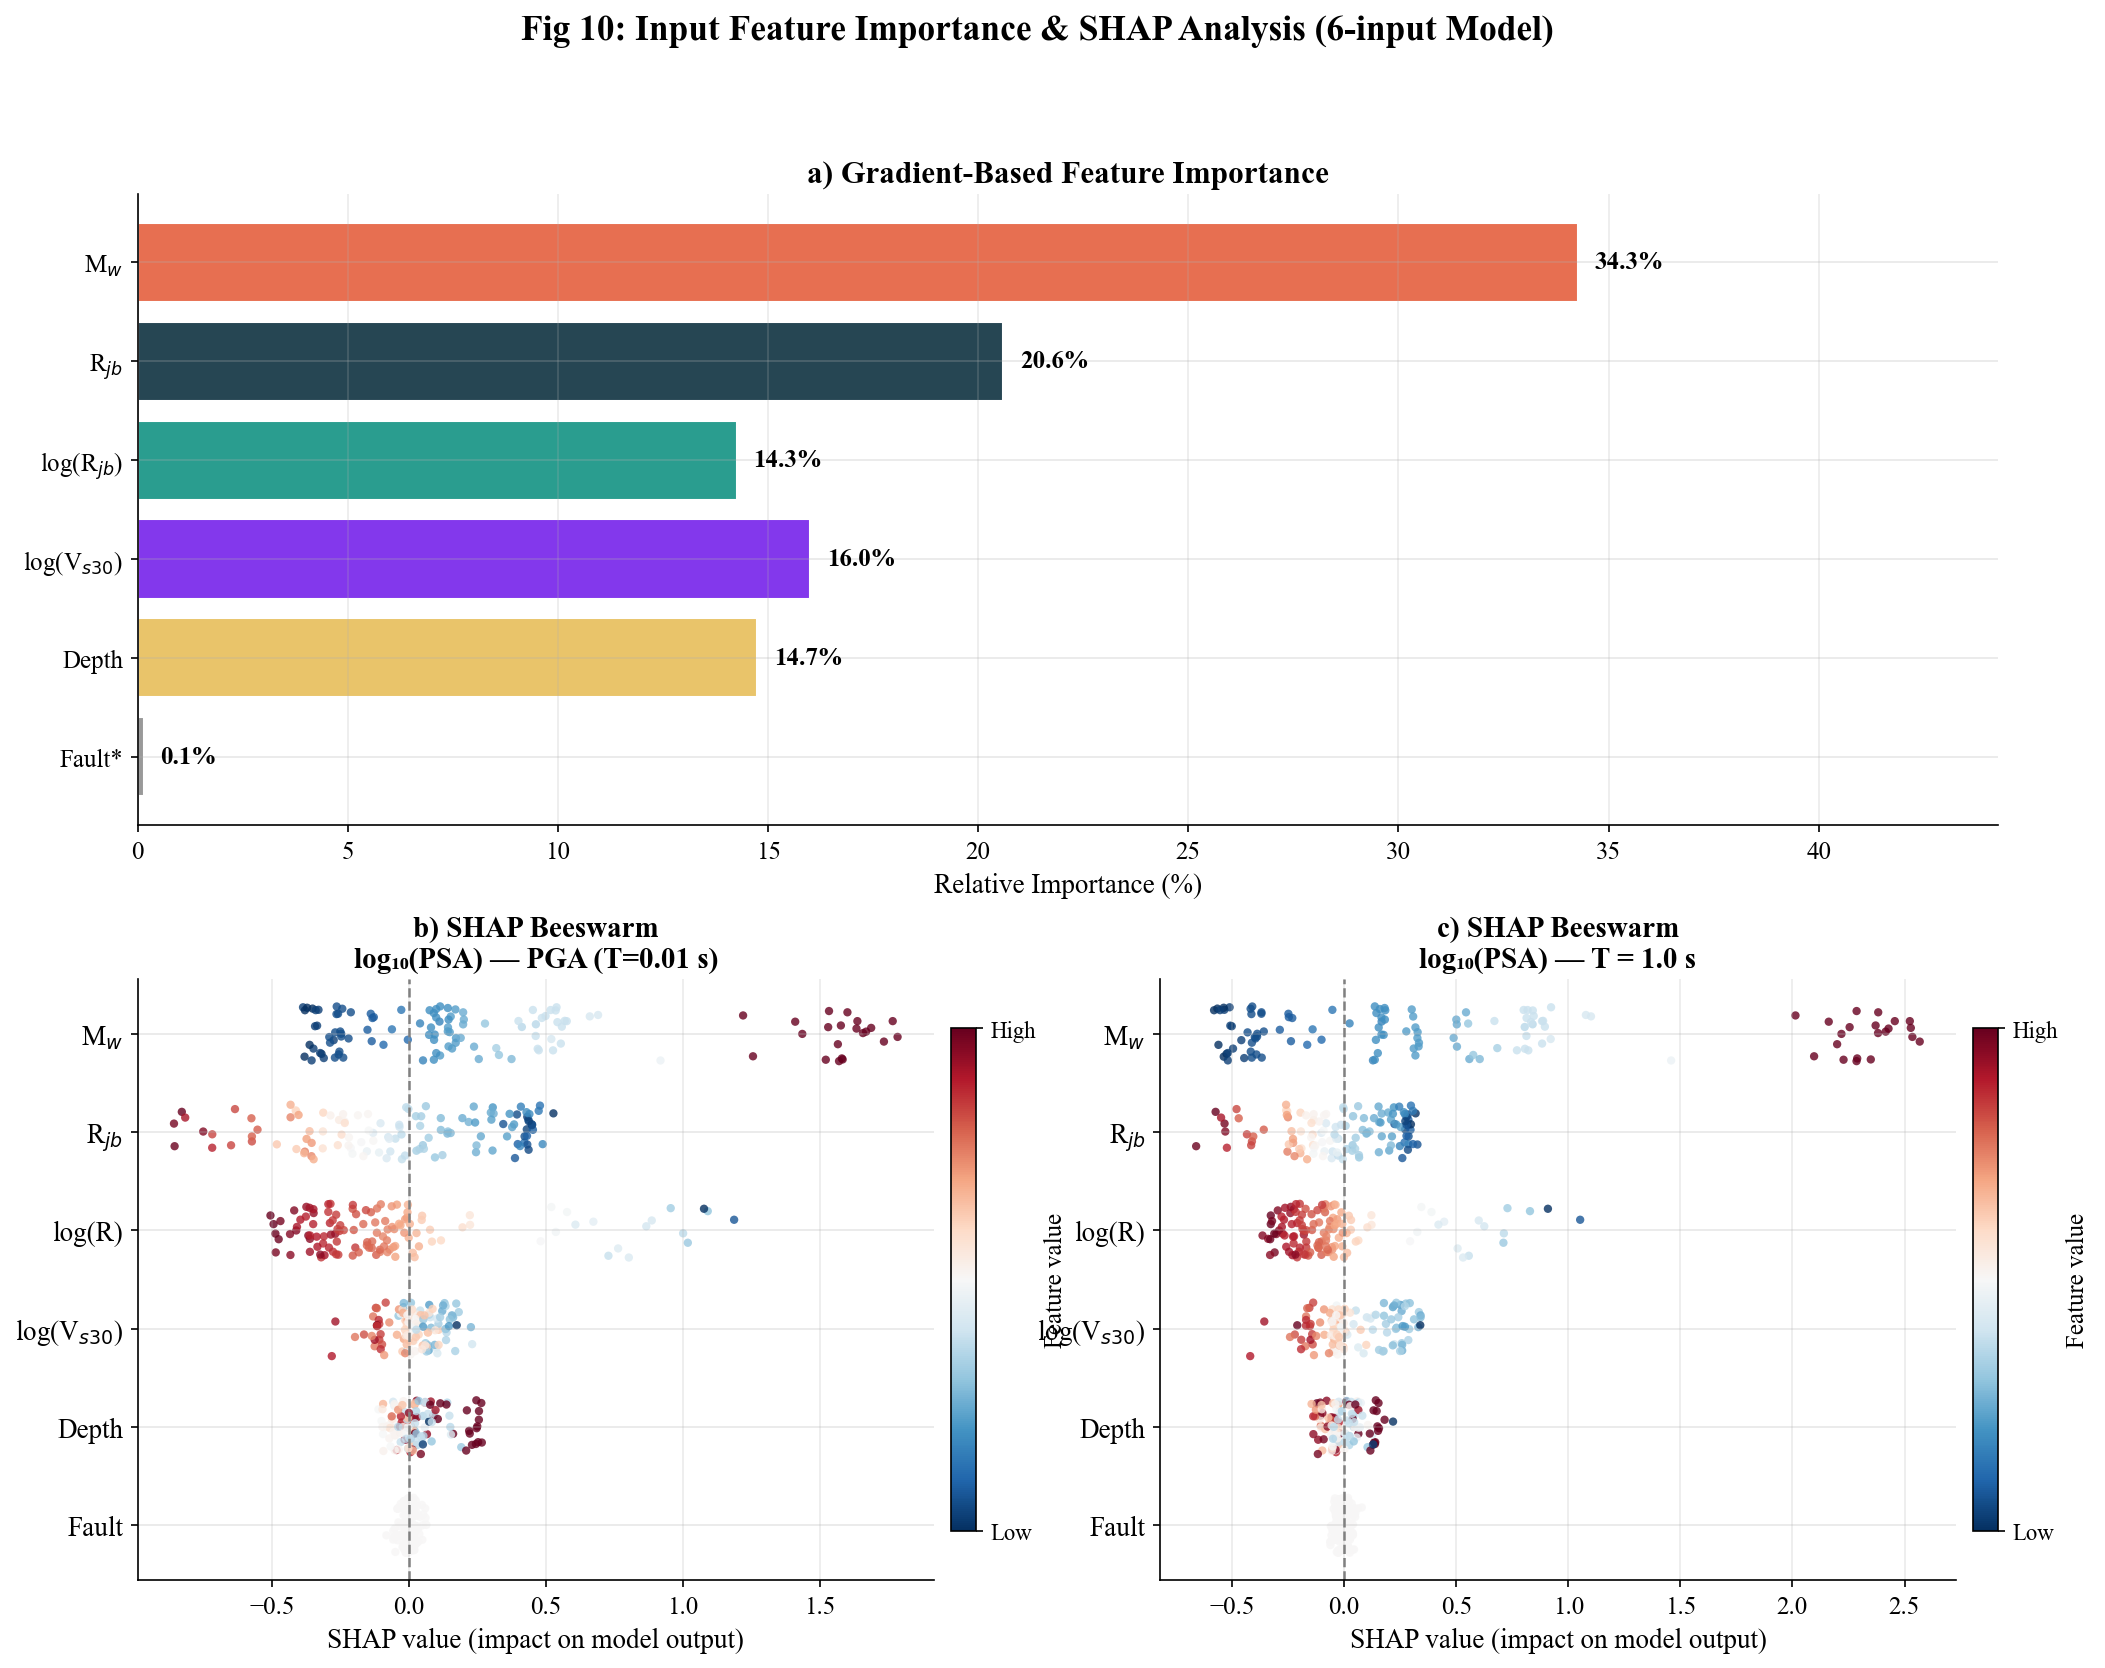

  → ./Report_Figures\Fig10_Feature_Importance_SHAP_Beeswarm.png


In [25]:
# ============================================================
# F10 — Feature Importance + SHAP (TOP: a | BOTTOM: b,c)
# Bigger fonts + cleaner layout
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import torch
import shap
from matplotlib.gridspec import GridSpec
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

# -----------------------------
# GLOBAL FONT SETTINGS
# -----------------------------
plt.rcParams.update({
    "font.family": "Times New Roman",
    "font.size": 14,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "figure.titlesize": 16
})

# -----------------------------
# FEATURE NAMES
# -----------------------------
feat_names_grad = [
    "M$_w$",
    "R$_{jb}$",
    "log(R$_{jb}$)",
    "log(V$_{s30}$)",
    "Depth",
    "Fault*"
]

feat_names_shap = [
    "M$_w$",
    "R$_{jb}$",
    "log(R)",
    "log(V$_{s30}$)",
    "Depth",
    "Fault"
]

# -----------------------------
# GRADIENT-BASED IMPORTANCE
# -----------------------------
grad_acc = np.zeros(N_CONT6 + 1)   # 5 continuous + fault
model6.eval()

n_samp = min(500, len(te_i))
Xs_sub = torch.from_numpy(X6_te[:n_samp]).to(DEVICE).requires_grad_(True)
Fs_sub = torch.from_numpy(f_te[:n_samp].astype(np.int64)).to(DEVICE)

pred_sum = model6(Xs_sub, Fs_sub).sum()
pred_sum.backward()

cont_imp = Xs_sub.grad.abs().mean(dim=0).cpu().numpy()   # (5,)

fault_imp = 0.0
with torch.no_grad():
    base = model6(Xs_sub.detach(), Fs_sub)
    for fcode in range(n_faults):
        alt = torch.full_like(Fs_sub, fcode)
        diff = (model6(Xs_sub.detach(), alt) - base).abs().mean().item()
        fault_imp += diff / n_faults

grad_acc[:5] = cont_imp
grad_acc[5]  = fault_imp / (cont_imp.mean() + 1e-9) * cont_imp.mean()
importance   = 100 * grad_acc / grad_acc.sum()

# -----------------------------
# SHAP BEESWARM SETTINGS
# -----------------------------
SHAP_BG_N = 100
SHAP_EX_N  = 120
SHAP_NSAMPLES = 50

def model6_predict_np(X_np):
    """
    X_np: columns = [Mw, Rjb, logR, logVs30, Depth, Fault]
    """
    xs_t = torch.from_numpy(X_np[:, :5].astype(np.float32)).to(DEVICE)
    fs_t = torch.from_numpy(X_np[:, 5].astype(np.int64)).to(DEVICE)
    model6.eval()
    with torch.no_grad():
        out = model6(xs_t, fs_t).cpu().numpy()
    return out

def make_pred_fn(period_k):
    return lambda X_np: model6_predict_np(X_np)[:, period_k]

def _to_2d_shap(sh):
    """
    SHAP sometimes returns an extra bias column.
    """
    if isinstance(sh, list):
        sh = sh[0]
    sh = np.asarray(sh)
    if sh.shape[1] == 6 + 1:
        sh = sh[:, :-1]
    return sh

# -----------------------------
# SAMPLE SELECTION
# -----------------------------
rng = np.random.default_rng(42)

bg_idx = rng.choice(len(X6_tr), min(SHAP_BG_N, len(X6_tr)), replace=False)
ex_idx = rng.choice(len(X6_te), min(SHAP_EX_N, len(X6_te)), replace=False)

bg_X = np.hstack([
    X6_tr[bg_idx],
    f_tr[bg_idx].astype(np.float32).reshape(-1, 1)
])

ex_X = np.hstack([
    X6_te[ex_idx],
    f_te[ex_idx].astype(np.float32).reshape(-1, 1)
])

raw_ex = X6[te_i[ex_idx]]  # continuous raw features only: 5 columns

# -----------------------------
# COMPUTE SHAP
# -----------------------------
if SHAP_OK:
    print("Computing SHAP values (fast mode)...")

    explainer_pga = shap.KernelExplainer(make_pred_fn(PGA_IDX), bg_X)
    shap_vals_pga = explainer_pga.shap_values(ex_X, nsamples=SHAP_NSAMPLES, silent=True)
    shap_vals_pga = _to_2d_shap(shap_vals_pga)

    explainer_1s = shap.KernelExplainer(make_pred_fn(19), bg_X)
    shap_vals_1s = explainer_1s.shap_values(ex_X, nsamples=SHAP_NSAMPLES, silent=True)
    shap_vals_1s = _to_2d_shap(shap_vals_1s)

    # -----------------------------
    # BEESWARM PLOT HELPER
    # -----------------------------
    def beeswarm_panel(ax, shap_vals, raw_vals, title):
        cmap = plt.cm.RdBu_r
        n_feat = 6

        for fi in range(n_feat):
            sv = shap_vals[:, fi]
            y_base = n_feat - 1 - fi

            local_rng = np.random.default_rng(fi)
            y_jitter = y_base + local_rng.uniform(-0.28, 0.28, len(sv))

            if fi < 5:
                fv = raw_vals[:, fi]
                fv_norm = (fv - fv.min()) / (np.ptp(fv) + 1e-9)
            else:
                fv_norm = np.full(len(sv), 0.5)

            ax.scatter(
                sv,
                y_jitter,
                c=cmap(fv_norm),
                s=16,
                alpha=0.8,
                linewidths=0,
                rasterized=True
            )

        ax.axvline(0, color="grey", lw=1.2, ls="--")
        ax.set_yticks(range(6))
        ax.set_yticklabels(feat_names_shap[::-1], fontsize=13)
        ax.set_xlabel("SHAP value (impact on model output)", fontsize=13)
        ax.set_title(title, fontsize=14, fontweight="bold")
        ax.grid(axis="x", alpha=0.25)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        sm = ScalarMappable(cmap=cmap, norm=Normalize(0, 1))
        sm.set_array([])
        cbar = plt.colorbar(sm, ax=ax, fraction=0.03, pad=0.02)
        cbar.set_label("Feature value", fontsize=12)
        cbar.ax.tick_params(labelsize=11)
        cbar.set_ticks([0, 1])
        cbar.set_ticklabels(["Low", "High"])

    # -----------------------------
    # FIGURE LAYOUT
    # -----------------------------
    fig = plt.figure(figsize=(16, 12))
    gs = GridSpec(2, 2, figure=fig, height_ratios=[1.05, 1.0], hspace=0.25, wspace=0.22)

    fig.suptitle(
        "Fig 10: Input Feature Importance & SHAP Analysis (6-input Model)",
        fontsize=17,
        fontweight="bold"
    )

    # (a) Top full-width gradient bar
    ax1 = fig.add_subplot(gs[0, :])

    bar_colors = ["#E76F51", "#264653", "#2A9D8F", "#8338EC", "#E9C46A", "#999999"]
    bars = ax1.barh(
        feat_names_grad[::-1],
        importance[::-1],
        color=bar_colors[::-1],
        edgecolor="white"
    )

    for bar, val in zip(bars, importance[::-1]):
        ax1.text(
            bar.get_width() + 0.4,
            bar.get_y() + bar.get_height() / 2,
            f"{val:.1f}%",
            va="center",
            fontsize=12,
            fontweight="bold"
        )

    ax1.set_xlabel("Relative Importance (%)", fontsize=13)
    ax1.set_title("a) Gradient-Based Feature Importance", fontsize=15, fontweight="bold")
    ax1.set_xlim(0, importance.max() + 10)
    ax1.grid(axis="x", alpha=0.25)
    ax1.tick_params(labelsize=12)

    # (b) Bottom-left SHAP beeswarm
    ax2 = fig.add_subplot(gs[1, 0])
    beeswarm_panel(
        ax2,
        shap_vals_pga,
        raw_ex,
        "b) SHAP Beeswarm\nlog₁₀(PSA) — PGA (T=0.01 s)"
    )

    # (c) Bottom-right SHAP beeswarm
    ax3 = fig.add_subplot(gs[1, 1])
    beeswarm_panel(
        ax3,
        shap_vals_1s,
        raw_ex,
        "c) SHAP Beeswarm\nlog₁₀(PSA) — T = 1.0 s"
    )

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    savefig("Fig10_Feature_Importance_SHAP_Beeswarm.png")
    plt.show()

else:
    # Fallback: gradient bar only
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(
        feat_names_grad[::-1],
        importance[::-1],
        color=bar_colors[::-1],
        edgecolor="white"
    )
    ax.set_xlabel("Relative Importance (%)", fontsize=13)
    ax.set_title("Fig 10: Gradient-Based Feature Importance (install shap for beeswarm)",
                 fontsize=15, fontweight="bold")
    ax.tick_params(labelsize=12)
    ax.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.savefig("Fig10_Feature_Importance_Gradient.png", dpi=300, bbox_inches="tight")
    plt.show()
    print("Install shap with: pip install shap")

### Training History Plot

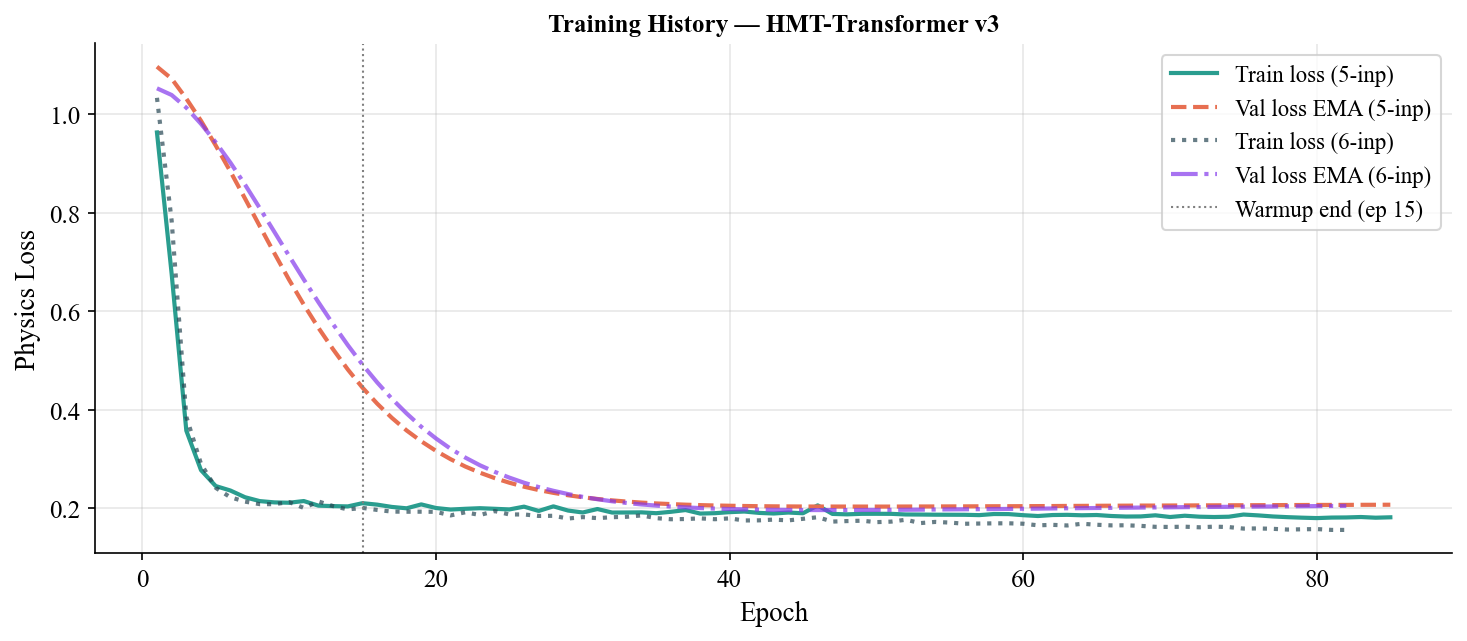

  → ./Report_Figures\Fig00_Training_History.png


In [26]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ep = np.arange(1, len(tr5_hist)+1)
ax.plot(ep, tr5_hist, color=C["teal"],  lw=2, label="Train loss (5-inp)")
ax.plot(ep, vl5_hist, color=C["coral"], lw=2, ls="--", label="Val loss EMA (5-inp)")
if len(tr6_hist):
    ep6 = np.arange(1, len(tr6_hist)+1)
    ax.plot(ep6, tr6_hist, color=C["navy"],   lw=2, ls=":",  label="Train loss (6-inp)", alpha=0.7)
    ax.plot(ep6, vl6_hist, color=C["purple"], lw=2, ls="-.", label="Val loss EMA (6-inp)", alpha=0.7)
ax.axvline(CFG.warmup, color="grey", lw=1, ls=":", label=f"Warmup end (ep {CFG.warmup})")
ax.set_xlabel("Epoch", fontsize=13)
ax.set_ylabel("Physics Loss", fontsize=13)
ax.set_title("Training History — HMT-Transformer v3", fontsize=12, fontweight="bold")
ax.legend(fontsize=11)
plt.tight_layout()
savefig("Fig00_Training_History.png")


## Report Tables
### T01 — Statistics of Data

In [27]:
# Compute statistics for key parameters
stat_params = {
    "M$_w$"          : df["Mag"],
    "R$_{jb}$ (km)"  : df["R(km)"],
    "V$_{s30}$ (m/s)": df["Vs30(m/s)"],
    "Depth (km)"     : df["Depth(km)"],
    "PSA (T=0.01 s)" : df["U_Hor_0.01"],
    "PSA (T=0.1 s)"  : df["U_Hor_0.1"],
    "PSA (T=1.0 s)"  : df["U_Hor_1"],
    "PSA (T=10.0 s)" : df["U_Hor_10"],
}

rows = []
for name, series in stat_params.items():
    s = series.astype(float)
    rows.append({
        "Parameter": name,
        "Min"      : f"{s.min():.3f}",
        "Max"      : f"{s.max():.3f}",
        "Mean"     : f"{s.mean():.3f}",
        "Median"   : f"{s.median():.3f}",
        "STD"      : f"{s.std():.3f}",
        "Skewness" : f"{s.skew():.3f}",
        "Kurtosis" : f"{s.kurtosis():.3f}",
    })

table1 = pd.DataFrame(rows)
table1.to_csv(os.path.join(OUT_DIR, "Table01_Statistics.csv"), index=False)

# Pretty display
from IPython.display import display
display(table1.style.set_caption("Table 1: Statistics of Dataset")
                    .hide(axis="index")
                    .set_properties(**{"text-align":"center"}))


Parameter,Min,Max,Mean,Median,STD,Skewness,Kurtosis
M$_w$,4.100,7.700,4.831,4.500,0.812,1.593,2.462
R$_{jb}$ (km),0.500,199.900,79.599,67.800,53.805,0.535,-0.811
V$_{s30}$ (m/s),198.000,2104.200,623.982,587.900,242.828,0.611,0.011
Depth (km),0.100,40.000,11.148,8.900,8.240,1.513,1.765
PSA (T=0.01 s),0.006,1196.172,21.315,2.542,60.912,6.472,60.803
PSA (T=0.1 s),0.007,2946.016,55.295,6.615,158.172,6.850,69.333
PSA (T=1.0 s),0.000,2462.499,20.837,1.318,85.606,10.024,161.056
PSA (T=10.0 s),0.000,274.559,0.712,0.009,5.567,22.145,823.184


### T02 — R² and Standard Deviation per Period

In [28]:
rows2 = []
for k, T in enumerate(PERIODS):
    rows2.append({
        "Period (s)"    : f"{T}",
        "R² (test)"     : f"{r2_5[k]:.4f}",
        "RMSE (log₁₀)"  : f"{rmse_5[k]:.4f}",
        "Bias (log₁₀)"  : f"{bias_5[k]:.4f}",
        "σ_τ (inter)"   : f"{sigma_tau[k]:.4f}",
        "σ_φ (intra)"   : f"{sigma_phi[k]:.4f}",
        "σ_T (total)"   : f"{sigma_tot[k]:.4f}",
    })

table2 = pd.DataFrame(rows2)
table2.to_csv(os.path.join(OUT_DIR, "Table02_R2_STD.csv"), index=False)
display(table2.style.set_caption("Table 2: R² and Standard Deviation by Period")
                    .hide(axis="index")
                    .set_properties(**{"text-align":"center"}))


Period (s),R² (test),RMSE (log₁₀),Bias (log₁₀),σ_τ (inter),σ_φ (intra),σ_T (total)
0.01,0.8385,0.4122,-0.0546,0.2571,0.3176,0.4086
0.025,0.8305,0.4243,-0.0702,0.2667,0.3224,0.4185
0.04,0.8279,0.4331,-0.0673,0.2603,0.3395,0.4278
0.05,0.8224,0.4439,-0.0623,0.2594,0.3549,0.4396
0.07,0.8146,0.4541,-0.0530,0.2630,0.3664,0.4510
0.1,0.8006,0.4632,-0.0497,0.2719,0.3717,0.4605
0.15,0.7979,0.4523,-0.0519,0.2738,0.3563,0.4493
0.2,0.8062,0.4372,-0.0507,0.2696,0.3405,0.4343
0.25,0.8154,0.4290,-0.0524,0.2662,0.3322,0.4257
0.3,0.8194,0.4237,-0.0550,0.2673,0.3241,0.4201


### T03 — Performance Parameters (R, K, K′, R₀², R₀′²)

In [29]:
# Definitions (as in Golbraikh & Tropsha 2002):
#   R   = Pearson correlation coefficient
#   K   = slope of line through origin (pred on y)  = sum(p*t)/sum(t^2)
#   K'  = slope of line through origin (pred on x)  = sum(p*t)/sum(p^2)
#   R0² = 1 - sum((t - K*t)^2) / sum((t - mean_t)^2)   (r² through origin)
#   R0'²= 1 - sum((t - K'*p)^2)/ sum((t - mean_t)^2)

rows3 = []
for k, T in enumerate(PERIODS):
    t = true5_te[:,k]; p = pred5_te[:,k]
    R   = float(np.corrcoef(t, p)[0,1])
    K   = float(np.sum(p*t) / (np.sum(t**2) + 1e-12))
    Kp  = float(np.sum(p*t) / (np.sum(p**2) + 1e-12))
    ss_res  = np.sum((t - K*t)**2)
    ss_tot  = np.sum((t - t.mean())**2)
    R02 = float(1 - ss_res / (ss_tot + 1e-12))
    ss_resp = np.sum((t - Kp*p)**2)
    R02p = float(1 - ss_resp / (ss_tot + 1e-12))
    rows3.append({
        "Period (s)": f"{T}",
        "R"         : f"{R:.4f}",
        "K"         : f"{K:.4f}",
        "K′"        : f"{Kp:.4f}",
        "R₀²"       : f"{max(R02,0):.4f}",
        "R₀′²"      : f"{max(R02p,0):.4f}",
    })

table3 = pd.DataFrame(rows3)
table3.to_csv(os.path.join(OUT_DIR, "Table03_Performance.csv"), index=False)
display(table3.style.set_caption("Table 3: Performance Parameters")
                    .hide(axis="index")
                    .set_properties(**{"text-align":"center"}))


Period (s),R,K,K′,R₀²,R₀′²
0.01,0.9174,0.8507,1.0404,0.9690,0.8404
0.025,0.9142,0.8357,1.0554,0.9620,0.8339
0.04,0.9123,0.8468,1.0458,0.9652,0.8304
0.05,0.9088,0.8556,1.0363,0.9676,0.8241
0.07,0.9040,0.8735,1.0214,0.9726,0.8152
0.1,0.8962,0.8831,1.0160,0.9735,0.8010
0.15,0.8949,0.8903,1.0196,0.9737,0.7986
0.2,0.8993,0.8921,1.0246,0.9739,0.8074
0.25,0.9046,0.8856,1.0351,0.9714,0.8177
0.3,0.9070,0.8827,1.0380,0.9708,0.8220


## 5-Input vs 6-Input Comparison

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
fig.suptitle("5-Input vs 6-Input Model Comparison", fontsize=15, fontweight="bold")

# R² comparison
ax = axes[0]
ax.plot(PERIODS, r2_5, color=C["teal"],  lw=2.5, marker="o", ms=4, label="5-input (baseline)")
ax.plot(PERIODS, r2_6, color=C["coral"], lw=2.5, marker="s", ms=4, ls="--", label="6-input (+Depth)")
ax.fill_between(PERIODS, r2_5, r2_6,
                where=r2_5 >= r2_6, alpha=0.15, color=C["teal"], label="5-inp better")
ax.fill_between(PERIODS, r2_5, r2_6,
                where=r2_6 > r2_5, alpha=0.15, color=C["coral"], label="6-inp better")
ax.axhline(r2_5.mean(), color=C["teal"],  ls=":", lw=1.3, label=f"5-inp mean={r2_5.mean():.4f}")
ax.axhline(r2_6.mean(), color=C["coral"], ls=":", lw=1.3, label=f"6-inp mean={r2_6.mean():.4f}")
ax.set_xscale("log")
ax.set_xlabel("Period (s)", fontsize=13); ax.set_ylabel("R²", fontsize=11)
ax.set_title("Per-Period R²", fontsize=12); ax.legend(fontsize=8)

# Bias comparison
ax = axes[1]
ax.plot(PERIODS, bias_5, color=C["teal"],  lw=2.5, marker="o", ms=4, label="5-input")
ax.plot(PERIODS, bias_6, color=C["coral"], lw=2.5, marker="s", ms=4, ls="--", label="6-input")
ax.axhline(0, color="black", lw=1.5, ls="--", label="Zero bias")
ax.set_xscale("log")
ax.set_xlabel("Period (s)", fontsize=13); ax.set_ylabel("Spectral Bias (log₁₀)", fontsize=11)
ax.set_title("Spectral Bias", fontsize=12); ax.legend(fontsize=8)

plt.tight_layout()
savefig("FigCMP_5vs6_Comparison.png")

# Summary table
print("\n" + "="*55)
print(f"{'Metric':<25} {'5-input':>12}             {'6-input':>12}")
print("="*55)
for metric, v5, v6 in [
    ("Mean R²",          r2_5.mean(),   r2_6.mean()),
    ("Mean RMSE",        rmse_5.mean(), rmse_6.mean()),
    ("Spectral Bias",    bias_5.mean(), bias_6.mean()),
    ("PGA R²",     r2_5[PGA_IDX], r2_6[PGA_IDX]),
    ("Best period R²",   r2_5.max(),    r2_6.max()),
    ("Worst period R²",  r2_5.min(),    r2_6.min()),
]:
    better = "← BETTER" if v5 > v6 else ("BETTER →" if v6 > v5 else "  TIE")
    print(f"  {metric:<23} {v5:>12.4f}   {better} {v6:>12.4f} ")
print("="*55)


## All Done ✓

All figures and tables have been saved to `OUT_DIR`.

### Files generated:
| File | Description |
|------|-------------|
| `Fig00_Training_History.png` | Loss curves (train/val, 5-inp and 6-inp) |
| `Fig01_Data_Distribution.png` | PGA vs R + M-R scatter |
| `Fig02_Statistics.png` | Histograms of Mw, R, Vs30, Depth, Fault |
| `Fig03_Architecture.png` | HMT-Transformer v3 architecture |
| `Fig04_Hyperparameter_Tuning.png` | Validation loss vs each hyperparameter |
| `Fig05_Regression_Plots.png` | Actual vs Predicted (train/val/test, 4 periods) |
| `Fig06_Residual_Analysis.png` | Residuals vs Mw, R, Vs30 |
| `Fig07_Standard_Deviation.png` | Inter/intra-event/total σ vs period |
| `Fig08_Sensitivity_Plots.png` | PSA spectra varying Mw, R, Vs30, Fault |
| `Fig09_Attenuation_Plots.png` | PSA vs R with data scatter + model lines |
| `Fig10_Feature_Importance_SHAP.png` | Gradient importance + SHAP |
| `FigCMP_5vs6_Comparison.png` | 5-input vs 6-input R² and bias |
| `Table01_Statistics.csv` | Min/Max/Mean/Median/STD/Skew/Kurtosis |
| `Table02_R2_STD.csv` | R², RMSE, Bias, σ_τ, σ_φ, σ_T per period |
| `Table03_Performance.csv` | R, K, K′, R₀², R₀′² per period |
